# Publication figures

Consolidated, publication-quality figures for the digital-bat paper. Every analysis loads the **17 `DEFAULT_SESSIONS` once** (`use_kinematics=False`; Krishna sessions never appear) and uses the single consensus joint model `joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft.pth` throughout. Shared style/stat/plot helpers live in `plotting_helpers.py`.

In [8]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
import notebook_helpers as nh
import plotting_helpers as ph

ph.set_pub_style()
ph.FIG_DIR = Path('out/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# Canonical display name for the joint encode/decode transformer (used in all labels).
HIPPO_NEDS = 'Hippo-NEDS'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cuda


## Shared setup

Load the 17 `DEFAULT_SESSIONS` **once** (`use_kinematics=False`, `behavior_dim==3`, Krishna excluded) and instantiate the single consensus joint model used throughout the paper. Downstream figures reuse these objects; nothing below re-loads data or re-instantiates the model.

In [9]:
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders

# 17 DEFAULT_SESSIONS, position-only (behavior_dim == 3).
session_names = list(DEFAULT_SESSION_NAMES)
data_config = make_data_config(session_names=session_names)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

# Single load in the joint model's *training* universe. make_joint_dataloaders
# loads once (kinematics on) and returns the position-only view `dl_pos` plus the
# shared meta. We use this ONE universe for BOTH the encode and decode arms so
# every analysis shares one flight_path_index (no cross-universe remapping). The
# tradeoff vs the plain position-only loader is that a few tail flights with short
# IMU are dropped — negligible, and it matches how the model was trained.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

bats = ph.bat_order()
BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(f'{len(session_names)} sessions | {n_neurons_total} neurons | behavior_dim={behavior_dim}')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
17 sessions | 3080 neurons | behavior_dim=3


In [10]:
from digitalbat.models.joint import JointMaskedTransformer

# --- Consensus model: the single joint encode/decode transformer used paper-wide
# (6-masking infill/forecast finetune; joint-encode-decode.ipynb §6.4).
JOINT_CKPT = ('./out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity'
              '_we1.9_wd2.8_wa0.67_n17_infillft.pth')
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)
INPUT_TRANSFORM = 'identity'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}

set_random_state(seed)
if os.path.exists(JOINT_CKPT):
    joint_model = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, input_transform=INPUT_TRANSFORM,
        session_to_room=session_to_room, **JOINT_PARAMS).to(device)
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    joint_model = joint_model.eval()
else:
    # Train-if-missing: 200-trial Optuna search (use_kinematics=False, fde_weight=0.5),
    # then train the winner. Reproduces the consensus checkpoint named above.
    from digitalbat.training.joint_trainer import ensure_joint_model
    joint_model, _jp, JOINT_CKPT = ensure_joint_model(
        dataloaders, unit_num_dict, session_to_room, meta_info_dict, device,
        seed=seed, out_dir='./out/joint', n_trials=200)
    JOINT_PARAMS = dict(num_layers=_jp['num_layers'], latent_dim=_jp['latent_dim'],
                        num_heads=4, ff_dim=_jp['ff_dim'], dropout=_jp['dropout'])

# Encode and decode arms share ONE flight universe (see the data-load cell), so the
# decode-arm loaders/meta are simply the shared ones — no separate universe.
joint_loaders, joint_meta = dataloaders, meta_info_dict
print('consensus joint model ready:', JOINT_CKPT)

consensus joint model ready: ./out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17.pth


In [11]:
# Encode-arm adapter + per-neuron encode-metric helper now live in the package
# (digitalbat.models.joint), keeping this notebook focused on the figures.
from digitalbat.models.joint import JointEncoderAdapter, encode_eval_records

bat_former = JointEncoderAdapter(joint_model, unit_num_dict).to(device).eval()

### Training utilities (train-if-missing)

Every model below loads its cached checkpoint if present; otherwise it is **trained
here** (the training code is ported from the source notebooks — `model_comparison`,
`decode-position-comparison`, `perturbations`) and saved, so `figures.ipynb` is
reproducible from scratch and fast on re-runs. Set `FORCE_RETRAIN = True` to ignore
the cache.

In [12]:
# === Training utilities: load-or-train for every model ===
import optuna
from copy import deepcopy
from digitalbat.models.former_defaults import make_trainer_config
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.models.glm import coupling_group_penalty

optuna.logging.set_verbosity(optuna.logging.WARNING)
from tqdm import tqdm as _tqdm


def _optuna_progress(study, trial):
    """Print one line after every Optuna trial so searches are never silent."""
    v = f'{trial.value:.4f}' if trial.value is not None else str(trial.value)
    try:
        best = f'{study.best_value:.4f}'
    except ValueError:
        best = 'n/a'
    print(f'    [optuna] trial {trial.number + 1} value={v} best={best} params={trial.params}', flush=True)
FORCE_RETRAIN = False
GLM_N_TRIALS, GLM_WD_RANGE, GLM_ALPHA_RANGE = 10, (1e-4, 50.0), (1e-4, 1e2)
NB_N_TRIALS = 20


def _exists(path):
    return (not FORCE_RETRAIN) and os.path.exists(path)


# --- GLM trainer (Poisson NLL; coupling params get lower LR + group-lasso) ---
def _val_fde_glm(model, flight_cluster=None):
    model.eval(); scores = []
    is_joint = getattr(model, 'joint', False)
    with torch.no_grad():
        for s, sd in dataloaders['valid'].items():
            yt, yp = [], []
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                m = b.mask.to(device)
                out = model(s, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
                v = m == 1.0
                yt.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
            scores.append(poisson_fde_population(np.vstack(yt), np.vstack(yp)))
    return float(np.nanmedian(np.hstack(scores)))


def train_glm(model, alpha=0.0, weight_decay=1.0, flight_cluster=None, n_epochs=1000,
              lr=1e-2, coup_lr=1e-3, grad_clip=5.0, patience=20, label=''):
    model = model.to(device)
    loss_fn = nn.PoissonNLLLoss(log_input=False).to(device)
    is_joint = getattr(model, 'joint', False); use_coup = getattr(model, 'use_coup', False)
    coup_ids = set(id(p) for p in model.coup_weights.parameters()) if use_coup else set()
    opt = torch.optim.AdamW(
        [{'params': [p for p in model.parameters() if id(p) not in coup_ids], 'weight_decay': weight_decay, 'lr': lr},
         {'params': [p for p in model.parameters() if id(p) in coup_ids], 'weight_decay': 0.0, 'lr': coup_lr}], lr=lr)
    best, best_w, no_imp = -np.inf, None, 0
    bar = _tqdm(range(n_epochs), desc=f'  train_glm{label}', leave=False)
    for _ in bar:
        model.train()
        for s, sd in dataloaders['train'].items():
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                X, Y, M = b.behavior.to(device), b.spike.to(device), b.mask.to(device)
                out = model(s, X, M, spike=Y, cluster_idx=ci); v = M == 1.0
                loss = loss_fn(out[v], Y[v])
                if use_coup:
                    loss = loss + alpha * coupling_group_penalty(model.coup_weights[s])
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip); opt.step()
        val = _val_fde_glm(model, flight_cluster)
        if val > best:
            best, best_w, no_imp = val, deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
        bar.set_postfix(val=f'{val:.4f}', best=f'{best:.4f}', no_imp=no_imp)
        if no_imp >= patience:
            break
    bar.close()
    if best_w is not None:
        model.load_state_dict(best_w)
    return best


def ensure_glm(path, make_model, cond='position', search_alpha=False):
    """GLM train-if-missing: Optuna over weight_decay (+ coupling alpha), then save."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    fc = flight_cluster if cond == 'joint' else None
    print(f'  [train GLM] {os.path.basename(path)}')

    def objective(trial):
        wd = trial.suggest_float('weight_decay', *GLM_WD_RANGE, log=True)
        a = trial.suggest_float('alpha', *GLM_ALPHA_RANGE, log=True) if search_alpha else 0.0
        set_random_state(seed)
        return train_glm(make_model().to(device), alpha=a, weight_decay=wd, flight_cluster=fc,
                         label=f' t{trial.number + 1}/{GLM_N_TRIALS}')

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=GLM_N_TRIALS, callbacks=[_optuna_progress])
    bp = study.best_params
    print(f'    [GLM] best params: {bp}', flush=True)
    set_random_state(seed); m = make_model().to(device)
    train_glm(m, alpha=bp.get('alpha', 0.0), weight_decay=bp['weight_decay'], flight_cluster=fc,
              label=' [final]')
    os.makedirs(os.path.dirname(path), exist_ok=True); torch.save(m.state_dict(), path)
    return m.eval()


def ensure_former(path, make_model, loaders=None):
    """Encoder (Bat_Transformer) train-if-missing via bat_former_trainer."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train encoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tc = make_trainer_config(model=m, dataloaders=loaders or dataloaders, device=device, model_name=path)
    tc['verbose'] = True  # show per-epoch tqdm progress instead of training silently
    _, best_w, _ = bat_former_trainer(**tc)
    torch.save(best_w, path); m.load_state_dict(best_w)
    return m.eval()


def ensure_nb_params(path, ndim, build_arrays):
    """NB Optuna hyperparameter search, train-if-missing. `build_arrays()` returns
    {session: (train, valid, r_lim)} of gathered arrays; caches the study to `path`."""
    import pickle as _pk
    if _exists(path):
        return _pk.load(open(path, 'rb')).best_params
    print(f'  [search NB-{ndim}d] {os.path.basename(path)}')
    sess_arr = build_arrays()

    def objective(trial):
        p = dict(sigma=trial.suggest_float('sigma', 0.5, 4.0),
                 n_bins_x=trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50]),
                 n_bins_y=trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50]),
                 min_occupancy=trial.suggest_int('min_occupancy', 1, 10),
                 use_uniform_prior=trial.suggest_categorical('use_uniform_prior', [True, False]))
        if ndim == 3:
            p['n_bins_z'] = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
        errs = []
        for s, (tr, va, r_lim) in sess_arr.items():
            try:
                nb = make_nb(ndim, r_lim, p).fit(tr['spikes'], np.column_stack([tr[c] for c in cols]))
                pdec, _ = nb.predict(va['spikes'])
                errs.append(np.median(np.sqrt(((np.column_stack([va[c] for c in cols]) - pdec) ** 2).sum(1))))
            except Exception:
                return -np.inf
        return -float(np.mean(errs))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=NB_N_TRIALS, callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(path), exist_ok=True); _pk.dump(study, open(path, 'wb'))
    return study.best_params


def ensure_decoder(path, make_model, loaders=None, n_epochs=1000, lr=1e-3, weight_decay=1e-2):
    """Transformer decoder (Bat_Transformer_Decoder) train-if-missing."""
    from digitalbat.models.decoder import bat_decoder_trainer
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train decoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    bat_decoder_trainer(model=m, dataloaders=loaders or dataloaders, device=device, pos_dims=3,
                        n_epochs=n_epochs, lr=lr, weight_decay=weight_decay,
                        loss_fn=nn.SmoothL1Loss(), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
                        valid_stat='median', early_stopping_patience=30, save_model=True, model_name=path)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.eval()


---
## Figure 1 — Transformer encoding/decoding models outperform standard approaches

**a–b** Model schematics (omitted — drawn separately). **c** Predicted vs observed rate maps for two dual-field example units. **d–e** Per-neuron encoding fit (Poisson FDE, Pearson r) for GLM (place), GLM (trajectory-specific place), and the joint transformer. **f** Example decoded 3-D trajectory (joint). **g–h** Decoding accuracy (3-D Fréchet distance per flight; 3-D reconstruction error per point) for NB (place), unified CEBRA, and joint.

In [28]:
# --- Joint DECODE arm: predict 3D position from spikes (all behaviour masked).
# Per-timestep records feed the trajectory panel (1f), reconstruction error (1h),
# and per-flight Fréchet distance (1g). Uses the joint decode loaders + meta.
from digitalbat.decoding import discrete_frechet

TRUTH_3D = ['x_true', 'y_true', 'z_true']
PRED_3D = ['x_pred', 'y_pred', 'z_pred']


@torch.no_grad()
def joint_decode_records(split='test'):
    recs = []
    for sn, sd in joint_loaders[split].items():
        bm = np.asarray(joint_meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(joint_meta['behavior_std'][sn]).reshape(-1)[:3]
        bat = parse_bat(sn)
        for batch in sd:
            m = batch.mask.to(device)
            bt = batch.mask.clone().to(device)      # decode: all behaviour masked
            nt = torch.zeros_like(bt)
            _, beh_pred, _ = joint_model(sn, batch.spike.to(device),
                                         batch.behavior.to(device), m, nt, bt)
            yp = beh_pred[:, :, :3].cpu().numpy() * bs + bm
            yt = batch.behavior[:, :, :3].numpy() * bs + bm
            mn = batch.mask.numpy().astype(bool)
            B, T = mn.shape
            fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mn], yp[mn]
            for i in range(len(ytf)):
                recs.append(dict(bat=bat, session=sn, flight_id=int(fpi[mn][i]),
                                 t_idx=int(tix[mn][i]),
                                 x_true=ytf[i, 0], y_true=ytf[i, 1], z_true=ytf[i, 2],
                                 x_pred=ypf[i, 0], y_pred=ypf[i, 1], z_pred=ypf[i, 2],
                                 err_2d=float(np.linalg.norm(ytf[i, :2] - ypf[i, :2])),
                                 err_3d=float(np.linalg.norm(ytf[i] - ypf[i]))))
    return pd.DataFrame(recs).assign(decoder='joint')


def frechet_per_flight(df, truth=TRUTH_3D, pred=PRED_3D):
    """Per-(decoder, session, flight) discrete 3D Fréchet distance."""
    rows = []
    gcols = ['bat', 'session', 'flight_id']
    gcols = (['decoder'] + gcols) if 'decoder' in df else gcols
    for keys, grp in df.groupby(gcols, sort=False, observed=True):
        grp = grp.sort_values('t_idx')
        row = dict(zip(gcols, keys if isinstance(keys, tuple) else (keys,)))
        row['frechet_3d'] = discrete_frechet(grp[truth].to_numpy(float),
                                             grp[pred].to_numpy(float))
        rows.append(row)
    return pd.DataFrame(rows)


joint_decode_test = joint_decode_records('test')
joint_frechet = frechet_per_flight(joint_decode_test)
print('joint decode: %d timepoints, %d flights' % (len(joint_decode_test), len(joint_frechet)))

joint decode: 8072 timepoints, 278 flights


Top dual-field candidates:
               session   bat  neuron       sep     corr       fde
Dataset_2_14611_231209 14611      78 11.148543 0.163324  0.007344
Dataset_2_14611_231209 14611      52 10.568349 0.017846 -0.157406
Dataset_2_14611_231209 14611     101 10.504285 0.256957  0.259756
Dataset_2_14611_231209 14611      46 10.120277 0.488881  0.237759
Dataset_2_14611_231209 14611      39 10.062306 0.690077  0.452555
Dataset_2_14611_231209 14611     117 10.057833 0.373101  0.189426
Dataset_2_14611_231209 14611     141  9.918165 0.261610  0.160915
Dataset_2_14445_231209 14445     128  9.600000 0.507429  0.068068
Dataset_2_14611_231209 14611      50  9.319335 0.485397  0.193645
Dataset_2_14611_231209 14611     133  9.266067 0.526209  0.274157
Dataset_2_14611_231209 14611      38  9.044888 0.425056  0.147123
Dataset_2_14611_231209 14611      49  9.019978 0.419585  0.150468


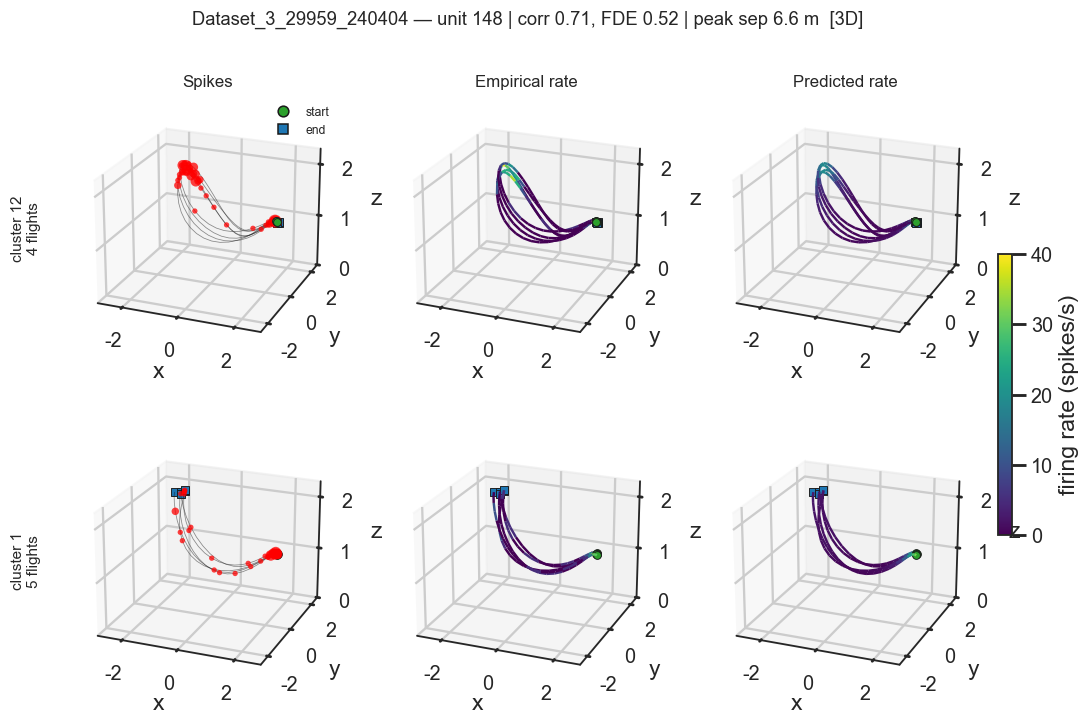

In [29]:
# === Fig 1c: dual-field example units (spikes / empirical rate / predicted rate) ===
# The paper's reference "Dataset_3_26659_240404 unit 148" was a typo for bat 29959;
# we plot ONLY this one unit (Dataset_3_29959_240404 unit 148, peak sep ~6.6 m), and
# ONLY its 3-D maps. Edit FIG1C_PICKS to override.
FIG1C_PICKS = [('Dataset_3_29959_240404', 148)]   # the only unit plotted

from notebook_helpers import (build_flight_records, select_dual_field_cells,
                              plot_dual_field_cell, loc_bin_width_rm)

dt = bin_width
dual_candidates = []
for sn, sd in dataloaders['test'].items():
    Xl, yl, pl, ml, fl = [], [], [], [], []
    with torch.no_grad():
        for batch in sd:
            X = batch.behavior.to(device); m = batch.mask.to(device)
            rate = bat_former(sn, X, m)
            Xl.append(X.cpu().numpy()); yl.append(batch.spike.numpy())
            pl.append(rate.cpu().numpy()); ml.append(m.cpu().numpy())
            fl.append(batch.flight_type_index.numpy())
    Xa, ya, pa = np.vstack(Xl), np.vstack(yl), np.vstack(pl)
    ma, fa = np.vstack(ml), np.hstack(fl)
    yflat, pflat = ya[ma == 1.0], pa[ma == 1.0]
    ncorr = corr(yflat, pflat, axis=0)
    nfde = poisson_fde_population(yflat, pflat)
    r_lim = meta_info_dict['r_lim'][sn]
    flights = build_flight_records(Xa, ya, pa, ma, fa,
                                   meta_info_dict['behavior_mean'][sn],
                                   meta_info_dict['behavior_std'][sn])
    # n_top large so a specifically-requested unit is captured, not just the top 2.
    for c in select_dual_field_cells(flights, ya.shape[2], dt, r_lim,
                                     loc_bin_width=loc_bin_width_rm, n_top=100):
        dual_candidates.append(dict(session=sn, bat=parse_bat(sn), flights=flights,
                                    r_lim=r_lim, corr=float(ncorr[c['neuron']]),
                                    fde=float(nfde[c['neuron']]), **c))

by_key = {(d['session'], d['neuron']): d for d in dual_candidates}
cand_df = pd.DataFrame([{k: d[k] for k in ('session', 'bat', 'neuron', 'sep', 'corr', 'fde')}
                        for d in dual_candidates]).sort_values('sep', ascending=False)
print('Top dual-field candidates:'); print(cand_df.head(12).to_string(index=False))

dual_candidates.sort(key=lambda d: d['sep'], reverse=True)
picks = []
for p in (FIG1C_PICKS or []):
    if tuple(p) in by_key:
        picks.append(by_key[tuple(p)])
    else:
        print(f'WARNING: {p} not a dual-field candidate (thresholds); skipping pin.')
if not picks:                                   # fall back: best-separated cell
    picks = [dual_candidates[0]]

pk = picks[0]   # dual-field example unit; drawn in the merged Fig 1 cell below


In [30]:
# === Fig 1d/e (+ ED Fig 1a/b): per-neuron encoding fit for GLM place, GLM
# trajectory-specific place, and the joint transformer ===
# Train-only Fréchet single-linkage flight clustering (alpha=0.8) supplies the
# trajectory-cluster place fields for the "joint"-conditioned GLM (matches
# model_comparison.ipynb / decode-position-comparison.ipynb).
from collections import Counter
from scipy.interpolate import interp1d
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from digitalbat.utility.utils import frechet_distance
from digitalbat.models.glm import (GLM_3DCosineBasis, GLM_Coupled,
                                   make_log_raised_cosine_basis)

CLUSTER_ALPHA, CLUSTER_DS, MIN_CLUSTER_FLIGHTS = 0.8, 7, 3
CLUSTER_MAX_ALPHA, UNCLUSTERED, N_LAGS = 1.5, -1, 10


def _downsample_traj(pos_xyz, mask, ds=CLUSTER_DS):
    out = np.full((pos_xyz.shape[0], ds, 3), np.nan)
    for i in range(pos_xyz.shape[0]):
        L = int(mask[i].sum())
        if L < 2:
            continue
        traj = pos_xyz[i, mask[i]]
        new_idx = np.linspace(0, L - 1, ds)
        for d in range(3):
            out[i, :, d] = interp1d(np.arange(L), traj[:, d])(new_idx)
    return out


def compute_flight_clusters(loaders, meta, alpha=CLUSTER_ALPHA):
    flight_cluster, cluster_keys = {}, {}
    for sn in loaders['train']:
        # meta is 13-dim (kinematic) under make_joint_dataloaders; take position (first 3).
        bm = np.asarray(meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(meta['behavior_std'][sn]).reshape(-1)[:3]
        trajs, fpis = {}, {}
        for split in ('train', 'valid', 'test'):
            ds = loaders[split][sn].dataset
            pos = (ds.behavior.numpy() * bs + bm)[..., :3]
            trajs[split] = _downsample_traj(pos, ds.mask.numpy().astype(bool))
            fpis[split] = ds.flight_path_index.numpy().astype(int)
        Xtr = trajs['train']
        keep = np.where(~np.isnan(Xtr[:, 0, 0]))[0]
        X, n = Xtr[keep], len(keep)
        mapping = {}
        if n < 2:
            for split in ('train', 'valid', 'test'):
                for f in fpis[split]:
                    mapping[int(f)] = UNCLUSTERED
            flight_cluster[sn], cluster_keys[sn] = mapping, []
            continue
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = frechet_distance(X[i], X[j])
        used_alpha = alpha
        while True:
            Z = linkage(squareform(D, checks=False), method='single')
            labels = fcluster(Z, t=used_alpha, criterion='distance').astype(int)
            if len(np.unique(labels)) > 1 or used_alpha >= CLUSTER_MAX_ALPHA:
                break
            used_alpha += 0.1
        counts = Counter(labels)
        major = sorted(int(c) for c, k in counts.items() if k >= MIN_CLUSTER_FLIGHTS)
        majset = set(major)
        for p, gi in enumerate(keep):
            lab = int(labels[p])
            mapping[int(fpis['train'][gi])] = lab if lab in majset else UNCLUSTERED
        for gi in range(Xtr.shape[0]):
            mapping.setdefault(int(fpis['train'][gi]), UNCLUSTERED)
        for split in ('valid', 'test'):
            t = trajs[split]
            for i in range(t.shape[0]):
                f = int(fpis[split][i])
                if np.isnan(t[i, 0, 0]):
                    mapping[f] = UNCLUSTERED
                    continue
                dists = np.array([frechet_distance(t[i], X[j]) for j in range(n)])
                jm = int(np.argmin(dists))
                lab = int(labels[jm])
                mapping[f] = lab if (dists[jm] <= used_alpha and lab in majset) else UNCLUSTERED
        flight_cluster[sn], cluster_keys[sn] = mapping, major
    return flight_cluster, cluster_keys


def cluster_idx_from_fpi(fpi_array, session, flight_cluster):
    fmap = flight_cluster.get(session, {})
    return torch.tensor([fmap.get(int(f), UNCLUSTERED) for f in fpi_array], dtype=torch.long)


flight_cluster, cluster_keys_by_session = compute_flight_clusters(dataloaders, meta_info_dict)

# --- Build + load the two GLMs and evaluate per-neuron FDE/corr on test.
_glm_common = dict(n_bases_per_dim=16, pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
                   activation='exp', bin_width=bin_width)


@torch.no_grad()
def eval_glm_metrics(model, joint_cond=False):
    model = model.to(device).eval()
    rows = []
    is_coupled = isinstance(model, GLM_Coupled)
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), sn, flight_cluster).to(device)
                  if (is_coupled and joint_cond) else None)
            if is_coupled:
                out = model(sn, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
            else:
                out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u,
                             corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


glm_place = ensure_glm('./out/bat_glm/bat_glm_position_seed_1_optuna_acc50_default17.pth',
                       lambda: GLM_3DCosineBasis(**_glm_common, output_dim_dict=unit_num_dict),
                       cond='position')
glm_traj = ensure_glm('./out/bat_glm/bat_glm_joint_seed_1_optuna_acc50_default17.pth',
                      lambda: GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_common, hist_basis=None,
                                          coup_basis=None, acausal_basis=None, n_lags=N_LAGS,
                                          cluster_keys=cluster_keys_by_session),
                      cond='joint', search_alpha=False)

ENC_LABELS = {'glm_place': 'GLM (place)', 'glm_traj': 'GLM (trajectory)', 'joint': HIPPO_NEDS}
ENC_ORDER = ['glm_place', 'glm_traj', 'joint']
encode_metrics_df = pd.concat([
    eval_glm_metrics(glm_place, joint_cond=False).assign(model='glm_place'),
    eval_glm_metrics(glm_traj, joint_cond=True).assign(model='glm_traj'),
    encode_eval_records(bat_former, dataloaders, device).assign(model='joint'),
], ignore_index=True)
encode_metrics_df['model'] = pd.Categorical(encode_metrics_df['model'], ENC_ORDER, ordered=True)
print('encode metrics rows:', len(encode_metrics_df))

encode metrics rows: 9240


indoor max-pairwise Fréchet (m): {'Dataset_3_29959_240403': np.float64(5.385), 'Dataset_1_32622_231010': np.float64(5.422), 'Dataset_1_32622_231007': np.float64(5.705), 'Dataset_1_32622_231009': np.float64(5.725), 'Dataset_3_00000_240402': np.float64(5.842), 'Dataset_3_29959_240404': np.float64(5.874), 'Dataset_3_00000_240404': np.float64(5.933), 'Dataset_3_00000_240403': np.float64(5.94), 'Dataset_3_00000_240405': np.float64(5.952), 'Dataset_3_14543_240421': np.float64(6.025), 'Dataset_3_14543_240420': np.float64(6.033), 'Dataset_3_29959_240402': np.float64(6.091), 'Dataset_3_29959_240405': np.float64(6.137)}
chosen zoom_session (min of max): Dataset_3_29959_240403


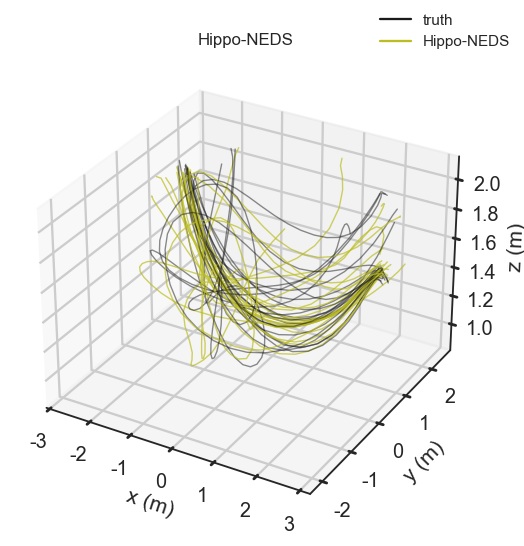

In [32]:
# === Fig 1f: example decoded 3D trajectory (joint decoder only) ===
from digitalbat.decoding import polylines_from_per_timestep_df, plot_trajectory_zoom_3d
from digitalbat.utility.utils import frechet_distance

# Pick the indoor session whose flights are most self-similar for the cleanest
# zoom panel: the smallest worst-case (max pairwise) Fréchet distance among its
# decoded test flights -> argmin_session max_{flight pairs} Fréchet.
def _downsample_xyz(xyz, k=10):
    L = len(xyz)
    if L < 2:
        return None
    grid = np.linspace(0, L - 1, k)
    return np.column_stack([np.interp(grid, np.arange(L), xyz[:, d]) for d in range(3)])


def _session_max_frechet(sdf, k=10):
    trajs = []
    for _, g in sdf.sort_values('t_idx').groupby('flight_id'):
        t = _downsample_xyz(g[['x_true', 'y_true', 'z_true']].to_numpy(), k)
        if t is not None:
            trajs.append(t)
    if len(trajs) < 2:
        return np.inf
    return max(frechet_distance(trajs[i], trajs[j])
               for i in range(len(trajs)) for j in range(i + 1, len(trajs)))


_indoor = [s for s in joint_decode_test['session'].unique() if ph.is_indoor(s)]
_spread = {s: _session_max_frechet(joint_decode_test[joint_decode_test['session'] == s])
           for s in _indoor}
zoom_session = min(_spread, key=_spread.get)
print('indoor max-pairwise Fréchet (m):',
      {s: round(v, 3) for s, v in sorted(_spread.items(), key=lambda kv: kv[1])})
print('chosen zoom_session (min of max):', zoom_session)

# zoom_session drawn in the merged Fig 1 cell below (panel f).


In [33]:
# === Fig 1g/h baseline: naïve-Bayes (place) decoder ===
# Ported from decode-position-comparison.ipynb: per-session NB-2D/3D on the base
# dataloaders, hyperparameters from the cached Optuna studies.
from digitalbat.models.decoder import NaiveBayes_Decoder

# nb_best (NB hyperparameters) is computed below, after make_nb / gather_session_arrays.


def gather_session_arrays(loader, bm, bs):
    spk, beh, msk, fpi = [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool)); fpi.append(batch.flight_path_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T, _ = beh.shape
    fpit = np.broadcast_to(fpi[:, None], (B, T)); tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpit[msk].astype(int), t_idx=tix[msk].astype(int))


def make_nb(ndim, r_lim, p):
    n_bins = (p['n_bins_x'], p['n_bins_y'], p['n_bins_z']) if ndim == 3 else (p['n_bins_x'], p['n_bins_y'])
    return NaiveBayes_Decoder(n_bins=n_bins, lims=[tuple(r_lim[d]) for d in range(ndim)],
                              sigma=p['sigma'], dt=bin_width, min_occupancy=p['min_occupancy'],
                              use_uniform_prior=p['use_uniform_prior'])


def _nb_session_arrays():
    sa = {}
    for s in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][s], meta_info_dict['behavior_std'][s]
        r_lim = meta_info_dict['r_lim'][s]
        tr = gather_session_arrays(dataloaders['train'][s], bm, bs)
        va = gather_session_arrays(dataloaders['valid'][s], bm, bs)
        if tr['spikes'].shape[0] >= 100 and va['spikes'].shape[0] >= 10:
            sa[s] = (tr, va, r_lim)
    return sa


nb_best = {n: ensure_nb_params(f'./out/nb_decoder/nb_decoder_{n}d_seed_{seed}_optuna.pkl',
                               n, _nb_session_arrays) for n in (2, 3)}


def eval_nb_records():
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        te3 = np.column_stack([te['pos_x'], te['pos_y'], te['pos_z']])
        nb3 = make_nb(3, r_lim, nb_best[3]).fit(tr['spikes'], tr3)
        pd3, _ = nb3.predict(te['spikes'])
        err3 = np.sqrt(((te3 - pd3) ** 2).sum(1))
        for i in range(len(err3)):
            recs.append(dict(bat=parse_bat(sn), session=sn, flight_id=int(te['flight_id'][i]),
                             t_idx=int(te['t_idx'][i]), x_true=te3[i, 0], y_true=te3[i, 1],
                             z_true=te3[i, 2], x_pred=pd3[i, 0], y_pred=pd3[i, 1], z_pred=pd3[i, 2],
                             err_3d=float(err3[i])))
    return pd.DataFrame(recs)


nb_decode_test = eval_nb_records()
nb_frechet = frechet_per_flight(nb_decode_test)
print('NB (place) decode: %d points, %d flights' % (len(nb_decode_test), len(nb_frechet)))

NB (place) decode: 8072 points, 278 flights


In [34]:
# === Fig 1g/h baseline: unified CEBRA decoder ===
# Ported from cebra-comparison.ipynb. Guarded: needs the source-only CEBRA repo on
# the path (~/Documents/code/CEBRA) and its cached unified solver; on any failure
# the panel simply omits CEBRA (a message is printed).
import hashlib
from sklearn.neighbors import KNeighborsRegressor

CEBRA_OK = True
try:
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    import cebra, cebra.data, cebra.models, cebra.solver
    from cebra import CEBRA

    OUT_DIR, CEBRA_MAX_ITER, KNN_N, UNI_VARIANT = './out/cebra', 6000, 36, 'cebra_pos'
    CEBRA_HP = dict(model_architecture='offset10-model', learning_rate=3e-4, temperature=1.0,
                    time_offsets=10, output_dimension=3, num_hidden_units=32)
    UNIFIED_MASKS = {'RandomNeuronMask': (0.3, 0.9, 0.05), 'RandomTimestepMask': (0.3, 0.9, 0.05)}
    _sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]

    def _hp_tag():
        a = CEBRA_HP['model_architecture'].replace('-model', '')
        return (f"{a}_lr{CEBRA_HP['learning_rate']:.0e}_t{CEBRA_HP['temperature']:.2g}"
                f"_to{CEBRA_HP['time_offsets']}_d{CEBRA_HP['output_dimension']}_h{CEBRA_HP['num_hidden_units']}")

    def session_flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool)
            spike = batch.spike.numpy(); pos_z = batch.behavior[:, :, :3].numpy()
            fpi = batch.flight_path_index.numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append(dict(spike=spike[b, sel].astype(np.float32),
                                pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                                flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
        return out

    def build_unified_solver(neuron_counts):
        model = cebra.models.init(CEBRA_HP['model_architecture'], num_neurons=int(sum(neuron_counts)),
                                  num_units=CEBRA_HP['num_hidden_units'],
                                  num_output=CEBRA_HP['output_dimension']).to(device)
        crit = cebra.models.FixedCosineInfoNCE(temperature=CEBRA_HP['temperature']).to(device)
        opt = torch.optim.Adam(list(model.parameters()), lr=CEBRA_HP['learning_rate'])
        return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)

    def fit_unified(Xs, Ys, path):
        solver = build_unified_solver([X.shape[1] for X in Xs])
        if os.path.exists(path):
            solver.load_state_dict(torch.load(path, map_location=device, weights_only=False), strict=True)
            return solver
        dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                          continuous=Ys[i].astype(np.float32), device=device)
                 for i in range(len(Xs))]
        dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
        dataset.set_masks(UNIFIED_MASKS); dataset.to(device)
        loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta', num_steps=CEBRA_MAX_ITER,
                                          batch_size=512, time_offset=CEBRA_HP['time_offsets'])
        dataset.configure_for(solver.model)
        set_random_state(seed); solver.fit(loader)
        solver.save(logdir=os.path.dirname(path), filename=os.path.basename(path))
        return solver

    def unified_embed_split(solver, split):
        fb = {s: session_flights(s, split) for s in session_names}
        Xs_all = [np.vstack([f['spike'] for f in fb[s]]).astype(np.float32) for s in session_names]
        Ys_all = [np.vstack([f['pos'] for f in fb[s]]).astype(np.float32) for s in session_names]
        Xt, Yt = [torch.from_numpy(X) for X in Xs_all], [torch.from_numpy(Y) for Y in Ys_all]
        solver = solver.to('cpu'); out = {}
        for i, s in enumerate(session_names):
            bs_ = min(512, max(2, len(Xs_all[i]) // 3))
            emb = solver.transform(Xt, Yt, session_id=i, batch_size=bs_).cpu().numpy()
            pieces, c = [], 0
            for f in fb[s]:
                L = len(f['spike']); pieces.append((emb[c:c + L], f)); c += L
            out[s] = pieces
        solver.to(device)
        return out

    _train_by = {s: session_flights(s, 'train') for s in session_names}
    Xs = [np.vstack([f['spike'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
    Ys = [np.vstack([f['pos'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
    unified_path = f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}__seed{seed}__s{len(session_names)}_{_sess_tag}.pt'
    unified_model = fit_unified(Xs, Ys, unified_path)

    uni_tr, uni_te = unified_embed_split(unified_model, 'train'), unified_embed_split(unified_model, 'test')
    crecs = []
    for s in session_names:
        Etr = np.vstack([e for e, _ in uni_tr[s]]); Ytr = np.vstack([f['pos'] for _, f in uni_tr[s]])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for emb, f in uni_te[s]:
            pred, true = np.asarray(knn.predict(emb)), f['pos']
            e3 = np.sqrt(((true - pred) ** 2).sum(1))
            for i in range(len(true)):
                crecs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                  t_idx=int(f['t_idx'][i]), x_true=true[i, 0], y_true=true[i, 1],
                                  z_true=true[i, 2], x_pred=pred[i, 0], y_pred=pred[i, 1],
                                  z_pred=pred[i, 2], err_3d=float(e3[i])))
    cebra_decode_test = pd.DataFrame(crecs)
    cebra_frechet = frechet_per_flight(cebra_decode_test)
    print('unified CEBRA decode: %d points, %d flights' % (len(cebra_decode_test), len(cebra_frechet)))
except Exception as exc:
    CEBRA_OK = False
    cebra_decode_test = cebra_frechet = None
    print(f'[skip CEBRA] {type(exc).__name__}: {exc}')

unified CEBRA decode: 8072 points, 278 flights


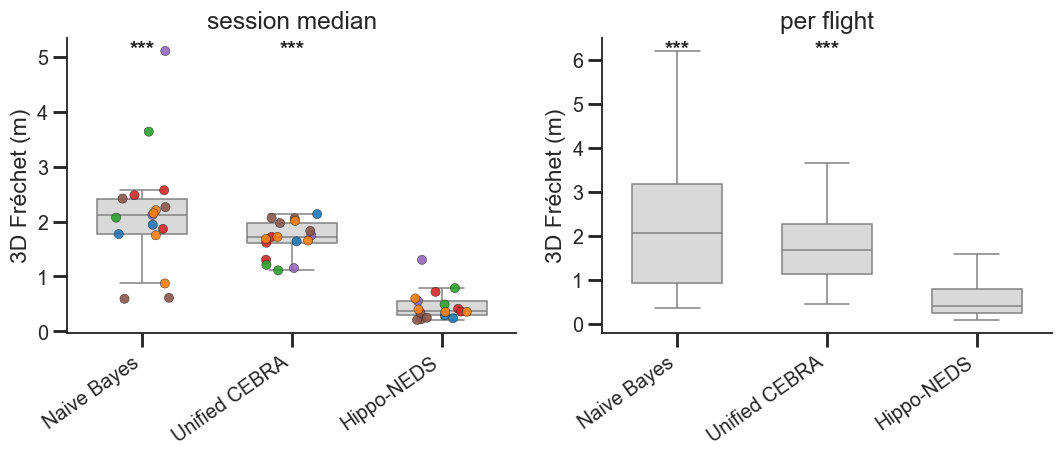

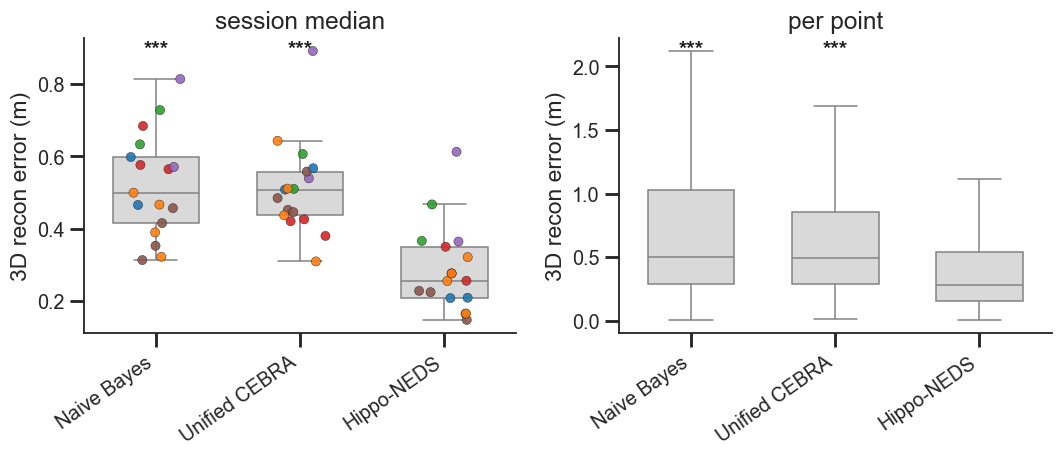


Fig 1g — 3D Fréchet, session-level Wilcoxon vs Hippo-NEDS:
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17        1.607 1.526e-05   *** P < 0.001
      cebra joint 17        1.308 1.526e-05   *** P < 0.001

Fig 1h — 3D recon error, session-level Wilcoxon vs Hippo-NEDS:
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17       0.2051 1.526e-05   *** P < 0.001
      cebra joint 17       0.2407 1.526e-05   *** P < 0.001


,model,vs,n,median_diff,p,stars,P
0,naive_bayes,joint,17,0.205139,0.000015,***,P < 0.001
1,cebra,joint,17,0.240653,0.000015,***,P < 0.001


In [35]:
# === Fig 1g/h: decoding accuracy for NB (place), unified CEBRA, joint ===
DECODE_LABELS = {'naive_bayes': 'Naive Bayes', 'cebra': 'Unified CEBRA', 'joint': HIPPO_NEDS}
DECODE_ORDER = ['naive_bayes', 'cebra', 'joint']

# Assemble per-flight Fréchet (1g) and per-point recon error (1h) across decoders.
_fr = [joint_frechet.assign(decoder='joint'), nb_frechet.assign(decoder='naive_bayes')]
_rc = [joint_decode_test[['bat', 'session', 'flight_id', 'err_3d']].assign(decoder='joint'),
       nb_decode_test[['bat', 'session', 'flight_id', 'err_3d']].assign(decoder='naive_bayes')]
if cebra_frechet is not None:
    _fr.append(cebra_frechet.assign(decoder='cebra'))
    _rc.append(cebra_decode_test[['bat', 'session', 'flight_id', 'err_3d']].assign(decoder='cebra'))

decode_frechet_df = pd.concat(_fr, ignore_index=True)
decode_recon_df = pd.concat(_rc, ignore_index=True)
present = [d for d in DECODE_ORDER if d in set(decode_frechet_df['decoder'])]
for df in (decode_frechet_df, decode_recon_df):
    df['decoder'] = pd.Categorical(df['decoder'], present, ordered=True)

# decode_frechet_df / decode_recon_df drawn in the merged Fig 1 cell below (panels g, h).


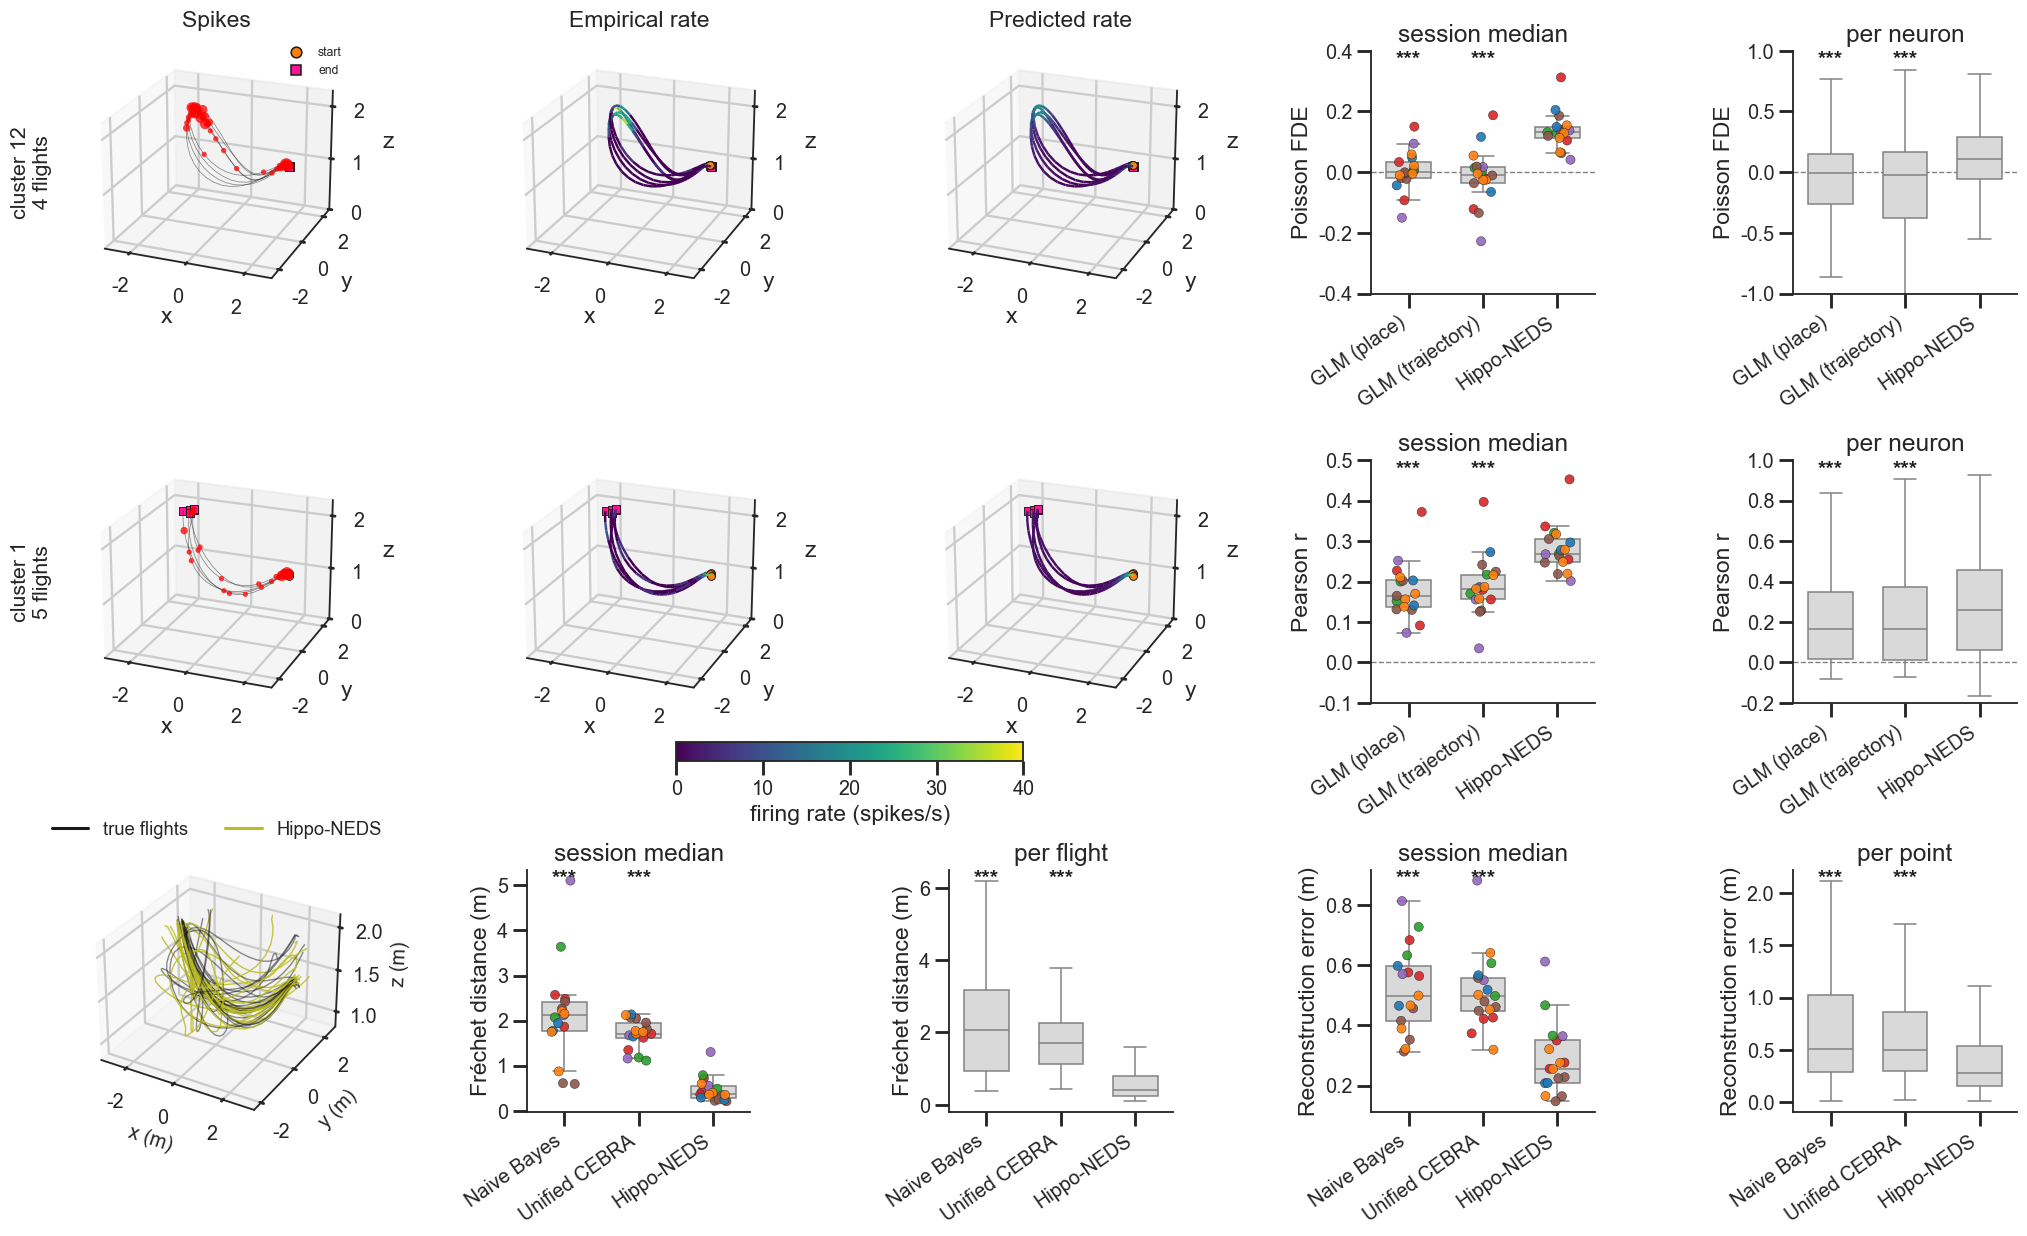


Fig 1d FDE - session-level Wilcoxon vs Hippo-NEDS:
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.1341 1.526e-05   *** P < 0.001
 glm_traj joint 17       0.1248 1.526e-05   *** P < 0.001

Fig 1e corr - session-level Wilcoxon vs Hippo-NEDS:
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.1093 1.526e-05   *** P < 0.001
 glm_traj joint 17      0.09684 1.526e-05   *** P < 0.001

Fig 1g Frechet - session-level Wilcoxon vs Hippo-NEDS:
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17        1.607 1.526e-05   *** P < 0.001
      cebra joint 17        1.391 1.526e-05   *** P < 0.001

Fig 1h recon - session-level Wilcoxon vs Hippo-NEDS:
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17       0.2051 1.526e-05   *** P < 0.001
      cebra joint 17       0.2414 1.526e-05   *** P < 0.001


In [53]:
# === Figure 1 (c-j) on a single canvas ===
# a-b are external schematics. Layout (3 rows x 5 cols):
#   row 1: c | d | e  (spikes | empirical | predicted, route 1) | f(sess) f(neuron)
#   row 2: c | d | e  (spikes | empirical | predicted, route 2) | g(sess) g(neuron)
#   row 3: h (decoded 3D) | i(session) i(flight) | j(session) j(point)
# Panels: c-e = dual-field example (one per map column); f = Poisson FDE;
#   g = Pearson r; h = decoding example; i = Fréchet; j = reconstruction error.
# Font sizes are applied per-panel at the end (see _apply_panel_fonts) so every
# individual title / axis label / tick label / legend is the same size, whether
# or not ph.set_pub_style() was re-run this session.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 17, 17, 15, 15

fig1 = plt.figure(figsize=(23, 13))
gs1 = fig1.add_gridspec(3, 5, hspace=0.45, wspace=0.55)

# c-e: dual-field example unit, 3-D maps (rows 1-2, cols 1-3); columns are the
# c (spikes), d (empirical rate), e (predicted rate) panels. Assumes 2 routes.
ax_c = np.array([[fig1.add_subplot(gs1[r, cc], projection='3d') for cc in range(3)]
                 for r in range(len(pk['clusters']))], dtype=object)
sm_c = plot_dual_field_cell(pk['flights'], pk['neuron'], pk['clusters'], dt, pk['r_lim'],
                            peaks=pk['peaks'], axes3d=ax_c, col_title_fs=FS_TITLE, row_label_fs=FS_LABEL)
# shrink horizontal gaps between the 3 map columns to match the comparison-pair pull:
# pull the outer columns (c spikes, e predicted) toward the fixed centre (d empirical)
_MAP_PULL = 0.03
for _r in range(ax_c.shape[0]):
    for _cc, _sh in ((0, _MAP_PULL), (2, -_MAP_PULL)):
        _pm = ax_c[_r, _cc].get_position()
        ax_c[_r, _cc].set_position([_pm.x0 + _sh, _pm.y0, _pm.width, _pm.height])
# horizontal rate colourbar between rows 1 and 2, below the right two (empirical,
# predicted) map columns
_p0, _p0b = ax_c[0, 1].get_position(), ax_c[0, 2].get_position()
_cbw = (_p0b.x1 - _p0.x0) / 2
_ymid = (_p0.y0 + ax_c[1, 1].get_position().y1) / 2
_cax = fig1.add_axes([_p0.x0 + _cbw / 2, _ymid - 0.013 / 2, _cbw, 0.013])
fig1.colorbar(sm_c, cax=_cax, orientation='horizontal', label='firing rate (spikes/s)')

# f, g: encoding fit (rows 1-2, cols 4-5) -- f = Poisson FDE, g = Pearson r
axd = (fig1.add_subplot(gs1[0, 3]), fig1.add_subplot(gs1[0, 4]))
_, ptab_d = ph.compare_models_fig(
    encode_metrics_df, 'fde', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Poisson FDE', unit_name='neuron', clip=(-1, 1), zero_line=True, sess_ylim=(-0.4, 0.4), axes=axd)
axe = (fig1.add_subplot(gs1[1, 3]), fig1.add_subplot(gs1[1, 4]))
_, ptab_e = ph.compare_models_fig(
    encode_metrics_df, 'corr', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Pearson r', unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.1, 0.5), axes=axe)

# h: example decoded 3-D trajectory (row 3, col 1)
ax_f = fig1.add_subplot(gs1[2, 0], projection='3d')
for _, gfl in (joint_decode_test[joint_decode_test['session'] == zoom_session]
               .sort_values('t_idx').groupby('flight_id')):
    ax_f.plot(gfl['x_true'], gfl['y_true'], gfl['z_true'], color='k', lw=0.9, alpha=0.5)
    ax_f.plot(gfl['x_pred'], gfl['y_pred'], gfl['z_pred'], color='tab:olive', lw=0.9, alpha=0.85)
ax_f.set_xlabel('x (m)', fontsize=FS_LABEL); ax_f.set_ylabel('y (m)', fontsize=FS_LABEL)
ax_f.set_zlabel('z (m)', fontsize=FS_LABEL)
ax_f.set_title('Behavior decoding')
# legend below the axes
ax_f.legend(handles=[plt.Line2D([], [], color='tab:olive', label=f'{HIPPO_NEDS} prediction'),
                     plt.Line2D([], [], color='k', label='true flights')],
            loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=1, fontsize=FS_LEG)

# i, j: decoding accuracy (row 3, cols 2-5) -- i = Fréchet, j = reconstruction error
axg = (fig1.add_subplot(gs1[2, 1]), fig1.add_subplot(gs1[2, 2]))
_, ptab_g = ph.compare_models_fig(
    decode_frechet_df, 'frechet_3d', present, ref='joint', labels=DECODE_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False, axes=axg)
axh = (fig1.add_subplot(gs1[2, 3]), fig1.add_subplot(gs1[2, 4]))
_, ptab_h = ph.compare_models_fig(
    decode_recon_df, 'err_3d', present, ref='joint', labels=DECODE_LABELS,
    model_col='decoder', ylabel='Reconstruction error (m)', unit_name='point', higher_is_better=False, axes=axh)

# shrink the 2-D comparison panels so they match the (margin-padded) 3-D panels and
# their tick labels don't collide with neighbours
def _shrink(ax, fx=0.82, fy=0.86):
    p = ax.get_position()
    ax.set_position([p.x0 + p.width * (1 - fx) / 2, p.y0 + p.height * (1 - fy) / 2,
                     p.width * fx, p.height * fy])
for _pair in (axd, axe, axg, axh):
    for _ax in _pair:
        _shrink(_ax)
# slightly shrink the intra-pair gap (session | per-unit) by pulling each pair's two
# panels toward each other: cols 4-5 (panels f, g, j) and cols 2-3 (panel i)
_GAP_PULL = 0.015
for _sess_ax, _unit_ax in (axd, axe, axg, axh):
    _ps, _pu = _sess_ax.get_position(), _unit_ax.get_position()
    _sess_ax.set_position([_ps.x0 + _GAP_PULL, _ps.y0, _ps.width, _ps.height])
    _unit_ax.set_position([_pu.x0 - _GAP_PULL, _pu.y0, _pu.width, _pu.height])
# slide the right-hand comparison block (cols 4-5: panels f, g, j) left, since pulling
# col 3 left and col 4 right widened the gap between columns 3 and 4
_COL34_PULL = 0.045
for _sess_ax, _unit_ax in (axd, axe, axh):
    for _ax in (_sess_ax, _unit_ax):
        _p = _ax.get_position()
        _ax.set_position([_p.x0 - _COL34_PULL, _p.y0, _p.width, _p.height])

# Enforce a single consistent font size on every panel individually (titles, x/y/z
# axis labels, tick labels, and legend text), so nothing depends on the global
# rcParams having been refreshed by ph.set_pub_style() this session.
def _apply_panel_fonts(ax):
    ax.title.set_fontsize(FS_TITLE)
    ax.xaxis.label.set_fontsize(FS_LABEL)
    ax.yaxis.label.set_fontsize(FS_LABEL)
    if hasattr(ax, 'zaxis'):
        ax.zaxis.label.set_fontsize(FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    _lg = ax.get_legend()
    if _lg is not None:
        for _t in _lg.get_texts():
            _t.set_fontsize(FS_LEG)
        if _lg.get_title() is not None:
            _lg.get_title().set_fontsize(FS_LEG)
for _ax in fig1.get_axes():
    _apply_panel_fonts(_ax)

ph.save_fig(fig1, 'fig1_full'); plt.show()
for _n, _pt in [('1f FDE', ptab_d), ('1g Pearson r', ptab_e), ('1i Frechet', ptab_g), ('1j recon', ptab_h)]:
    print(f'\nFig {_n} - session-level Wilcoxon vs {HIPPO_NEDS}:'); ph.p_table(_pt.to_dict('records'))

**Figure 1 | Transformer-based encoding/decoding models outperform standard approaches on hippocampal data.**
**a–b**, Model schematics (masking scheme; dual-branch architecture), drawn separately.
**c**, An example unit with spatially separated place fields on two different flight routes (3-D views). For each unit and route: observed spikes (red, area ∝ count) on the flight path, the empirical firing-rate map, and the joint model's predicted-rate map (empirical and predicted share a colour scale).
**d–e**, Encoding fit quantified as per-neuron Poisson fraction deviance explained (**d**) and Pearson correlation (**e**) between predicted and observed spike trains on held-out flights, for a place GLM, a trajectory-specific-place GLM, and the joint transformer. Left, session medians (points = sessions, coloured by bat); right, all neurons pooled. Boxes show median and IQR; whiskers 1.5× IQR.
**f**, Representative decoded (olive) versus true (black) 3-D flight trajectories from the joint decoder for one session.
**g–h**, Decoding accuracy as per-flight 3-D discrete Fréchet distance (**g**) and per-point 3-D reconstruction error (**h**) for a naïve-Bayes place decoder, unified CEBRA, and the joint decoder.
Stars denote two-sided Wilcoxon signed-rank tests on paired per-session medians versus the joint model (*P* < 0.05 *, *P* < 0.01 **, *P* < 0.001 ***); n.s. comparisons are unmarked. Exact *P* values are printed in the tables above each panel. FDE axes are clipped to [−1, 1] for display; all statistics use raw values.

---
## Extended Data Figure 1 — full model ladders

**a–b** Per-neuron encoding fit (Poisson FDE, Pearson r) for every model in `model_comparison.ipynb`. **c–d** Per-flight/point decoding accuracy (3-D Fréchet distance, 3-D reconstruction error) for the full decoder ladder in `decode-position-comparison.ipynb`. Stars: session-level Wilcoxon vs the joint model. (`GLM + lags + kin` is omitted — it requires the kinematics-augmented behaviour, incompatible with the position-only single load; re-enable with a separate kinematics loader if needed.)

In [21]:
# === ED Fig 1a/b: all encoding models (per-neuron FDE + corr) ===
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (make_model_config, make_model_name,
                                              DEFAULT_LR, DEFAULT_WEIGHT_DECAY)
from digitalbat.models.glm import make_symmetric_raised_cosine_basis

# Temporal-filter bases (match model_comparison.ipynb).
HIST_N_BASIS, COUP_N_BASIS, ACAUSAL_N_BASIS = 6, 4, 6
hist_basis, _, _ = make_log_raised_cosine_basis(HIST_N_BASIS, N_LAGS, bin_width)
coup_basis, _, _ = make_log_raised_cosine_basis(COUP_N_BASIS, N_LAGS, bin_width, include_zero_lag=True)
acausal_basis, _, _ = make_symmetric_raised_cosine_basis(ACAUSAL_N_BASIS, N_LAGS, bin_width)
glm_lags = np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()
DATA_TAG, GLM_TAG = '_acc50_preln_17_sess', '_acc50_default17'


def build_glm(name, cond):
    ck = cluster_keys_by_session if cond == 'joint' else None
    if name == 'GLM' and cond == 'position':
        return GLM_3DCosineBasis(**_glm_common, output_dim_dict=unit_num_dict)
    if name == 'GLM + lags':
        return GLM_3DCosineBasis(**_glm_common, output_dim_dict=unit_num_dict, lag_seconds=glm_lags)
    return GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_common,
                       hist_basis=hist_basis if 'hist' in name else None,
                       coup_basis=coup_basis if 'coup' in name else None,
                       acausal_basis=acausal_basis if 'acausal' in name else None,
                       n_lags=N_LAGS, cluster_keys=ck)


def glm_ckpt(name, cond):
    tag = name.lower().replace(' + ', '_').replace(' ', '_')
    return f'./out/bat_glm/bat_{tag}_{cond}_seed_{seed}_optuna{GLM_TAG}.pth'


# Full-arch transformer config from the pre-LN Optuna search.
import json as _json
_ep = f'./out/bat_former/former_best_params{DATA_TAG}_seed_{seed}.json'
_arch = ({k: _json.load(open(_ep))[k] for k in ('latent_dim', 'ff_dim', 'num_layers', 'dropout_prob')
          if k in _json.load(open(_ep))} if os.path.exists(_ep) else {})
base_cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict, **_arch)


def build_former(kind):
    if kind == 'transformer':
        return Bat_Transformer(**base_cfg)
    if kind == 'mlp':
        return Bat_Transformer(**{**base_cfg, 'use_attention': False})
    return Bat_Transformer(**{**base_cfg, 'latent_dim': 32, 'ff_dim': 32, 'num_layers': 1})


@torch.no_grad()
def eval_former_metrics(model):
    model = model.to(device).eval()
    rows = []
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


# Registry: (display label, kind, spec). Joint GLMs get a '(joint)' suffix.
ED1_MODELS = [
    ('GLM (place)',                    'glm',    ('GLM', 'position')),
    ('GLM + lags (place)',             'glm',    ('GLM + lags', 'position')),
    ('GLM + hist (place)',             'glm',    ('GLM + hist', 'position')),
    ('GLM + coup (place)',             'glm',    ('GLM + coup', 'position')),
    ('GLM + hist + coup (place)',      'glm',    ('GLM + hist + coup', 'position')),
    ('GLM + acausal (place)',          'glm',    ('GLM + acausal', 'position')),
    ('GLM (trajectory)',               'glm',    ('GLM', 'joint')),
    ('GLM + hist (trajectory)',        'glm',    ('GLM + hist', 'joint')),
    ('GLM + coup (trajectory)',        'glm',    ('GLM + coup', 'joint')),
    ('GLM + hist + coup (trajectory)', 'glm',    ('GLM + hist + coup', 'joint')),
    ('GLM + acausal (trajectory)',     'glm',    ('GLM + acausal', 'joint')),
    ('MLP only',                       'former', 'mlp'),
    (HIPPO_NEDS,                       'joint',  None),
]
ED1_ORDER = [m[0] for m in ED1_MODELS]

_pieces = []
for label, kind, spec in ED1_MODELS:
    try:
        if kind == 'glm':
            name, cond = spec
            gm = ensure_glm(glm_ckpt(name, cond), lambda: build_glm(name, cond),
                            cond=cond, search_alpha=('coup' in name))
            df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
        elif kind == 'former':
            ck = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                                 out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                                          'small': './out/bat_former_small'}[spec], suffix=DATA_TAG)
            fm = ensure_former(ck, lambda: build_former(spec))
            df = eval_former_metrics(fm)
        else:
            df = encode_eval_records(bat_former, dataloaders, device)
        _pieces.append(df.assign(model=label))
        print(f'  ok: {label}')
    except Exception as exc:
        print(f'  [skip {label}] {type(exc).__name__}: {exc}')

ed1_encode_df = pd.concat(_pieces, ignore_index=True)
ed1_present = [m for m in ED1_ORDER if m in set(ed1_encode_df['model'])]
ed1_encode_df['model'] = pd.Categorical(ed1_encode_df['model'], ed1_present, ordered=True)
print('ED1 encode models:', ed1_present)

  ok: GLM (place)
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok: GLM + lags
  ok: GLM + hist
  ok: GLM + coup
  ok: GLM + acausal
  ok: GLM (traj.)
  [stale checkpoint, retraining] bat_glm_hist_joint_seed_1_optuna_acc50_default17.pth: Error(s) in loading state_dict for GLM_Coupled:
  [train GLM] bat_glm_hist_joint_seed_1_optuna_acc50_default17.pth


    [optuna] trial 1 value=-0.0154 best=-0.0154 params={'weight_decay': 0.023801037902772264}


[W 2026-07-08 09:57:53,877] Trial 1 failed with parameters: {'weight_decay': 1.2738188799721928} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_471985/3853689131.py", line 100, in objective
    return train_glm(make_model().to(device), alpha=a, weight_decay=wd, flight_cluster=fc,
                     label=f' t{trial.number + 1}/{GLM_N_TRIALS}')
  File "/tmp/ipykernel_471985/3853689131.py", line 71, in train_glm
    val = _val_fde_glm(model, flight_cluster)
  File "/tmp/ipykernel_471985/3853689131.py", line 40, in _val_fde_glm
    out = model(s, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/torch/nn/modules/module.py", line 1751, in _wrapped_call_impl
    return self._call_impl(*

KeyboardInterrupt: 

In [ ]:
# === ED Fig 1c/d: decoder ladder (9 decoders) ===
# Ladder vs Hippo-NEDS, in the order requested for ED Fig 1c/d:
#   NB (place), NB (place)+continuity, NB (trajectory), NB (trajectory)+continuity,
#   GLM + coup (place), GLM + hist + coup (place), CEBRA (multi), Unified CEBRA,
#   Hippo-NEDS.
# The bespoke decoders (trajectory-cluster NB, GLM-inversion MAP, multi-session
# CEBRA) are ported from decode-position-comparison.ipynb (real-data path, 3D
# only). Each heavy fit runs ONCE, is pickled under ./out/ed1_decoders/, and is
# loaded on re-run (same run-once/save/load pattern as the GLM / NB / CEBRA
# checkpoints elsewhere in this notebook).
import copy as _copy
from digitalbat.models.decoder import (NaiveBayes_Continuity_Decoder, GLM_MAP_Decoder)
from digitalbat.models.glm import GLM_Coupled

ED1_DEC_DIR = './out/ed1_decoders'
os.makedirs(ED1_DEC_DIR, exist_ok=True)


def _cache_records(path, compute):
    """Run ``compute() -> DataFrame`` once, pickle it, and load on later runs."""
    if os.path.exists(path):
        return pd.read_pickle(path)
    df = compute()
    df.to_pickle(path)
    return df


def make_nb_continuity(ndim, r_lim, c_speed, nb_hp):
    n_bins = ((nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z']) if ndim == 3
              else (nb_hp['n_bins_x'], nb_hp['n_bins_y']))
    return NaiveBayes_Continuity_Decoder(
        c_speed=c_speed, sigma_min=0.02, sigma_max=5.0, n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)], sigma=nb_hp['sigma'],
        dt=bin_width, min_occupancy=nb_hp['min_occupancy'],
        use_uniform_prior=nb_hp['use_uniform_prior'])


# Continuity speed factor (shared by NB+continuity and the GLM-inversion warm start).
with open(f'./out/nb_decoder/nb_cont_decoder_3d_seed_{seed}_optuna.pkl', 'rb') as _fh:
    C_SPEED_3D = pickle.load(_fh).best_params['c_speed']


def _records_3d(arr, pred3, session, bat):
    """Per-timestep decode-schema records (x/y/z true+pred, err_3d)."""
    te3 = np.column_stack([arr['pos_x'], arr['pos_y'], arr['pos_z']])
    out = []
    for i in np.flatnonzero(~np.isnan(pred3[:, 0])):
        out.append(dict(bat=bat, session=session, flight_id=int(arr['flight_id'][i]),
                        t_idx=int(arr['t_idx'][i]),
                        x_true=float(te3[i, 0]), y_true=float(te3[i, 1]), z_true=float(te3[i, 2]),
                        x_pred=float(pred3[i, 0]), y_pred=float(pred3[i, 1]), z_pred=float(pred3[i, 2]),
                        err_3d=float(np.sqrt(((te3[i] - pred3[i]) ** 2).sum()))))
    return out


def _compute_nb_cont():
    """NB (place) + continuity, 3D — same c_speed / nb_best as elsewhere."""
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        nbc = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
            tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
        pred3, _ = nbc.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


def _gather_with_cluster(loader, bm, bs):
    """gather_session_arrays + per-timestep train-only ``flight_type_index``."""
    spk, beh, msk, fpi, fti = [], [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool))
        fpi.append(batch.flight_path_index.numpy()); fti.append(batch.flight_type_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi); fti = np.concatenate(fti)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T = msk.shape
    fpi_t = np.broadcast_to(fpi[:, None], (B, T)); fti_t = np.broadcast_to(fti[:, None], (B, T))
    tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpi_t[msk].astype(int),
                flight_type=fti_t[msk].astype(int), t_idx=tix[msk].astype(int))


# ---------------------------------------------------------------------------
# (1) trajectory-cluster NB (naive_bayes_cluster) + continuity variant, 3D.
#     Per flight-cluster rate maps, routed by flight_type at decode time.
# ---------------------------------------------------------------------------
MIN_CLUSTER_FLIGHTS = 3


def _major_clusters(arr):
    seen, counts = set(), {}
    for fid, c in zip(arr['flight_id'], arr['flight_type']):
        if fid in seen:
            continue
        seen.add(fid); counts[int(c)] = counts.get(int(c), 0) + 1
    return {c for c, n in counts.items() if n >= MIN_CLUSTER_FLIGHTS}


def _subset(arr, m):
    return {k: (v[m] if isinstance(v, np.ndarray) else v) for k, v in arr.items()}


def _fit_per_cluster(train, r_lim, continuity):
    major = _major_clusters(train)
    preds = {}
    for c in list(major) + ['other']:
        m = (~np.isin(train['flight_type'], list(major)) if c == 'other'
             else train['flight_type'] == c)
        if m.sum() < 50:
            continue
        sub = _subset(train, m)
        pos3 = np.column_stack([sub['pos_x'], sub['pos_y'], sub['pos_z']])
        try:
            if continuity:
                preds[c] = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                    sub['spikes'], pos3, flight_id=sub['flight_id'], t_idx=sub['t_idx'], dt=bin_width)
            else:
                preds[c] = make_nb(3, r_lim, nb_best[3]).fit(sub['spikes'], pos3)
        except Exception:
            continue
    return preds


def _route_predict(arr, preds, continuity):
    if not preds:
        return None
    pred = np.full((arr['spikes'].shape[0], 3), np.nan)
    for c in np.unique(arr['flight_type']):
        m = arr['flight_type'] == c
        nb_c = preds.get(int(c)) or preds.get('other')
        if nb_c is None:
            continue
        if continuity:
            p, _ = nb_c.predict(arr['spikes'][m], flight_id=arr['flight_id'][m], t_idx=arr['t_idx'][m])
        else:
            p, _ = nb_c.predict(arr['spikes'][m])
        pred[m] = p
    return pred


def _compute_cluster_nb(continuity):
    def _fn():
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = _gather_with_cluster(dataloaders['train'][sn], bm, bs)
            te = _gather_with_cluster(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            preds = _fit_per_cluster(tr, r_lim, continuity)
            pred3 = _route_predict(te, preds, continuity)
            if pred3 is not None:
                recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (2) GLM-inversion MAP decoders (glm_map = GLM+hist+coup, glm_map_coup = coup
#     only), position conditioning, 3D. Invert the fixed real-trained encoders
#     with an NB+continuity warm start (same c_speed as nb_continuity).
# ---------------------------------------------------------------------------
def _load_glm_encoder(ckpt, with_hist):
    kw = dict(output_dim_dict=unit_num_dict, **_glm_common, coup_basis=coup_basis, n_lags=N_LAGS)
    if with_hist:
        kw['hist_basis'] = hist_basis
    glm = GLM_Coupled(**kw)
    miss, _ = glm.load_state_dict(torch.load(ckpt, map_location=device), strict=False)
    assert not miss, f'{ckpt} missing required keys: {miss[:5]}'
    return glm.to(device).eval()


def _compute_glm_map(ckpt, with_hist):
    def _fn():
        enc = _load_glm_encoder(ckpt, with_hist)
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
            te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
            warm_nb = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            dec = GLM_MAP_Decoder(enc, sn, bm, bs, device=device).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            warm, _ = warm_nb.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
            pred3, _ = dec.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'],
                                   warm_start=warm)
            recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (3) multi-session CEBRA (position-informed, kNN read-out). Reuses the cached
#     Optuna-tuned multi-session checkpoint (never retrained here).
# ---------------------------------------------------------------------------
def _compute_cebra_multi():
    import hashlib
    from sklearn.neighbors import KNeighborsRegressor
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    OUT_DIR, MAX_ITER, KNN_N = './out/cebra', 6000, 36
    HP = dict(model_architecture='offset10-model', learning_rate=3e-4, temperature=1.0,
              time_offsets=10, output_dimension=3, num_hidden_units=32)
    study_path = f'{OUT_DIR}/cebra_optuna_cebra_pos_seed{seed}_it2000_6p.pkl'
    if os.path.exists(study_path):
        HP.update(pickle.load(open(study_path, 'rb')).best_params)
    a = HP['model_architecture'].replace('-model', '')
    tag = (f"{a}_lr{HP['learning_rate']:.0e}_t{HP['temperature']:.2g}_to{HP['time_offsets']}"
           f"_d{HP['output_dimension']}_h{HP['num_hidden_units']}")
    _st = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
    path = f'{OUT_DIR}/multisession_cebra_pos__{tag}__it{MAX_ITER}__seed{seed}__s{len(session_names)}_{_st}.pt'

    def flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy(); fpi = batch.flight_path_index.numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append(dict(spike=spike[b, sel].astype(np.float32),
                                pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                                flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
        return out

    train_by = {s: flights(s, 'train') for s in session_names}
    Xs = [np.vstack([f['spike'] for f in train_by[s]]) for s in session_names]
    Ys = [np.vstack([f['pos'] for f in train_by[s]]) for s in session_names]
    if os.path.exists(path):
        model = CEBRA.load(path)
    else:
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MAX_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **HP)
        model.fit(Xs, Ys); model.save(path)
    assert model.num_sessions_ == len(session_names), 'CEBRA session-count mismatch; delete + retrain.'

    def embed(fl, sid):
        req = len(model.offset_)
        out = []
        for f in fl:
            X = f['spike']
            if len(X) < req:
                X = np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(X, session_id=sid)[:len(f['spike'])], f))
        return out

    recs = []
    for sid, s in enumerate(session_names):
        etr, ete = embed(train_by[s], sid), embed(flights(s, 'test'), sid)
        Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([f['pos'] for _, f in etr])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for emb, f in ete:
            recs.extend(_records_3d(dict(pos_x=f['pos'][:, 0], pos_y=f['pos'][:, 1],
                                         pos_z=f['pos'][:, 2], flight_id=np.full(len(f['pos']), f['flight_id']),
                                         t_idx=f['t_idx']), np.asarray(knn.predict(emb)), s, parse_bat(s)))
    return pd.DataFrame(recs)


# --- assemble the ladder (each guarded: a missing decoder is simply skipped) ---
_GLM_HIST_COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_full_v2.pth'
_GLM_COUP_CKPT = './out/bat_glm/bat_glm_coup_position_seed_1_optuna_acc50_full_v2.pth'

ed1_dec_sources = [
    ('naive_bayes',           lambda: nb_decode_test),
    ('nb_continuity',         lambda: _cache_records(f'{ED1_DEC_DIR}/nb_continuity_seed_{seed}.pkl',
                                                     _compute_nb_cont)),
    ('naive_bayes_cluster',   lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(False))),
    ('nb_continuity_cluster', lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cont_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(True))),
    ('glm_map_coup',          lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_coup_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_COUP_CKPT, with_hist=False))),
    ('glm_map',               lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_HIST_COUP_CKPT, with_hist=True))),
    ('cebra_multi',           lambda: _cache_records(f'{ED1_DEC_DIR}/cebra_multi_seed_{seed}.pkl',
                                                     _compute_cebra_multi)),
    ('cebra',                 lambda: cebra_decode_test),
    ('joint',                 lambda: joint_decode_test),
]

ed1_fr, ed1_rc = [], []
for _key, _src in ed1_dec_sources:
    try:
        _df = _src()
        if _df is None or len(_df) == 0:
            print(f'  [skip {_key}] no records'); continue
        ed1_fr.append(frechet_per_flight(_df).assign(decoder=_key))
        ed1_rc.append(_df[['bat', 'session', 'flight_id', 'err_3d']].assign(decoder=_key))
        print(f'  ok: {_key} ({len(_df)} points)')
    except Exception as _exc:
        print(f'  [skip {_key}] {type(_exc).__name__}: {_exc}')

ED1_DEC_LABELS = {
    'naive_bayes': 'NB (place)', 'nb_continuity': 'NB (place) + continuity',
    'naive_bayes_cluster': 'NB (trajectory)', 'nb_continuity_cluster': 'NB (trajectory) + continuity',
    'glm_map_coup': 'GLM + coup (place)', 'glm_map': 'GLM + hist + coup (place)',
    'cebra_multi': 'CEBRA (multi)', 'cebra': 'Unified CEBRA', 'joint': HIPPO_NEDS}
ED1_DEC_ORDER = ['naive_bayes', 'nb_continuity', 'naive_bayes_cluster', 'nb_continuity_cluster',
                 'glm_map_coup', 'glm_map', 'cebra_multi', 'cebra', 'joint']
ed1_frechet = pd.concat(ed1_fr, ignore_index=True)
ed1_recon = pd.concat(ed1_rc, ignore_index=True)
ed1_dec_present = [d for d in ED1_DEC_ORDER if d in set(ed1_frechet['decoder'])]
for df in (ed1_frechet, ed1_recon):
    df['decoder'] = pd.Categorical(df['decoder'], ed1_dec_present, ordered=True)

# (plotting for ED Fig 1a-d assembled on one canvas in the next cell)


In [ ]:
# === Extended Data Figure 1 (a-d) on a single canvas ===
# 4 rows x 2 cols; each row is one panel = a (session, per-unit) pair from
# compare_models_fig, giving each panel the full canvas width.
#   row 1: a = encoding FDE        row 2: b = encoding corr
#   row 3: c = decoding Fréchet    row 4: d = decoding recon error
fig_ed1 = plt.figure(figsize=(14, 22))
gs_ed1 = fig_ed1.add_gridspec(4, 2, hspace=0.8, wspace=0.3)

ax_a = (fig_ed1.add_subplot(gs_ed1[0, 0]), fig_ed1.add_subplot(gs_ed1[0, 1]))
_, ptab_ed1a = ph.compare_models_fig(
    ed1_encode_df, 'fde', ed1_present, ref=HIPPO_NEDS, ylabel='Poisson FDE',
    unit_name='neuron', clip=(-1, 1), zero_line=True, sess_ylim=(-0.4, 0.4), axes=ax_a)

ax_b = (fig_ed1.add_subplot(gs_ed1[1, 0]), fig_ed1.add_subplot(gs_ed1[1, 1]))
_, ptab_ed1b = ph.compare_models_fig(
    ed1_encode_df, 'corr', ed1_present, ref=HIPPO_NEDS, ylabel='Pearson r',
    unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.1, 0.5), axes=ax_b)

ax_c = (fig_ed1.add_subplot(gs_ed1[2, 0]), fig_ed1.add_subplot(gs_ed1[2, 1]))
_, ptab_ed1c = ph.compare_models_fig(
    ed1_frechet, 'frechet_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False, axes=ax_c)

ax_d = (fig_ed1.add_subplot(gs_ed1[3, 0]), fig_ed1.add_subplot(gs_ed1[3, 1]))
_, ptab_ed1d = ph.compare_models_fig(
    ed1_recon, 'err_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Reconstruction error (m)', unit_name='point', higher_is_better=False, axes=ax_d)

ph.save_fig(fig_ed1, 'edfig1_full'); plt.show()
for _n, _pt in [('1a FDE', ptab_ed1a), ('1b corr', ptab_ed1b),
                ('1c Fréchet', ptab_ed1c), ('1d recon', ptab_ed1d)]:
    print(f'\nED Fig {_n} — session-level Wilcoxon vs {HIPPO_NEDS}:'); ph.p_table(_pt.to_dict('records'))


**Extended Data Figure 1 | Full model ladders.** **a–b**, Per-neuron encoding fit (Poisson FDE, Pearson r) on held-out flights for the complete model set: place and temporal-filter GLMs (history, coupling, acausal self-filter) under position and trajectory-cluster conditioning, an attention-free MLP, a small encoder-only transformer, the full transformer, and the joint model. **c–d**, Per-flight 3-D Fréchet distance and per-point 3-D reconstruction error for the decoder ladder (naïve-Bayes place, NB + continuity, transformer decoder, unified CEBRA, joint). Points are session medians coloured by bat (left panels) and pooled neurons/flights (right panels); stars are two-sided Wilcoxon signed-rank tests on paired per-session medians versus the joint model; exact *P* values are printed above. FDE axes clipped to [−1, 1] for display; statistics use raw values. `GLM + lags + kin` (needs kinematics) and the SVM / GLM-inversion decoders (bespoke classes) are omitted here.

---
## Extended Data Figure 2 — synthetic & shuffle controls

**a–b** Per-neuron encoding fit (Poisson FDE, Pearson r) when the *entire* ED Fig 1 model ladder is **retrained on synthetic place-cell spikes** — per-session smoothed 3-D rate maps, same architecture/hyperparameters — and evaluated on the **real** held-out test set. On purely place-driven training data the transformer's edge over place GLMs collapses, isolating the real-neural structure it exploits. **c** Decoder ladder vs `Hippo-NEDS`, 3-D Fréchet (as ED Fig 1c). **d–f** Decoding **cost** = metric(mode) − metric(real) by 3-D Fréchet for trial-shuffle, synthetic place-only, and synthetic place×trajectory training (per-flight Δ; Wilcoxon anchored on the Transformer decoder). **g–j** As c–f for 3-D reconstruction error.

> **Sources.** Panels a–b retrain the ladder on synthetic spikes from `digitalbat.datasets.synthetic.make_synthetic_train_dataloaders` (train-if-missing, `_synth` checkpoints; the joint model via `joint_trainer.train_joint` with the consensus params) and score on real test — mirroring `internals.ipynb` / `preprocess-data-v0j-share.ipynb`. Panels c/g reuse this notebook's ED Fig 1 decoder ladder (`ed1_frechet` / `ed1_recon`). Panels d–f / h–j import the per-flight surrogate-mode tables exported by `decode-position-comparison.ipynb` §5 → `./out/decode_costs/ed2_decode_costs_seed_{seed}.pkl`; run that notebook's export cell once to populate them (they degrade gracefully to placeholders if absent).

In [ ]:
# === ED Fig 2a/b: encode ladder RETRAINED on synthetic place-cell spikes, eval on real ===
# Replace each session's TRAIN spikes with samples from its smoothed 3-D rate map
# (valid/test stay real by reference), retrain the full ED Fig 1a/b ladder with the
# SAME architecture/hyperparameters (train-if-missing, `_synth` checkpoints), then
# score per-neuron FDE/corr on the REAL held-out test set. Mirrors internals.ipynb /
# preprocess-data-v0j-share.ipynb, extended from the transformer to the whole ladder.
from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders
from digitalbat.training.joint_trainer import train_joint, scheme_weights
import re as _re

SYNTH_MODE = 'empirical'   # matches decode-position-comparison SYNTH_SAMPLING ('empirical' resample)
SYNTH_TAG = f'_synth_{SYNTH_MODE}'

# The joint universe's meta stats are 13-D (kinematic); the position-only view is
# 3-D. Slice behaviour mean/std to xyz for the synthetic rate-map fit (matches how
# gather_session_arrays / joint_decode un-z-score position elsewhere).
_meta_pos3 = dict(meta_info_dict)
_meta_pos3['behavior_mean'] = {s: np.asarray(v).reshape(-1)[:3]
                               for s, v in meta_info_dict['behavior_mean'].items()}
_meta_pos3['behavior_std'] = {s: np.asarray(v).reshape(-1)[:3]
                              for s, v in meta_info_dict['behavior_std'].items()}
syn_loaders, syn_simulators = make_synthetic_train_dataloaders(
    dataloaders, _meta_pos3, dt=bin_width, mode=SYNTH_MODE, seed=seed)
assert syn_loaders['valid'] is dataloaders['valid'] and syn_loaders['test'] is dataloaders['test']


def _synth_ckpt(path):
    root, ext = os.path.splitext(path)
    return f'{root}{SYNTH_TAG}{ext}'


def _joint_synth_params():
    """Consensus joint hyperparameters (parsed from JOINT_CKPT + cached study)."""
    p = dict(num_layers=JOINT_PARAMS['num_layers'], latent_dim=JOINT_PARAMS['latent_dim'],
             ff_dim=JOINT_PARAMS['ff_dim'], dropout=JOINT_PARAMS['dropout'],
             lr=3e-3, weight_decay=1e-2, w_encode=1.0, w_decode=1.0, w_aux=1.0,
             lam=1.0, pos_weight=1.0)
    base = os.path.basename(JOINT_CKPT)
    for k, rgx in dict(lam=r'_lam([0-9.]+)', pos_weight=r'_pw([0-9.]+)', w_encode=r'_we([0-9.]+)',
                       w_decode=r'_wd([0-9.]+)', w_aux=r'_wa([0-9.]+)').items():
        mm = _re.search(rgx, base)
        if mm:
            p[k] = float(mm.group(1))
    study_path = './out/joint/joint_optuna_v2_kin0.pkl'
    if os.path.exists(study_path):
        try:
            p.update(pickle.load(open(study_path, 'rb')).best_params)
        except Exception as _e:
            print(f'  [joint-synth] could not read study ({_e}); using parsed/default params')
    return p


def _ensure_joint_synth(loaders):
    """Retrain the joint transformer on synthetic train spikes (same params)."""
    p = _joint_synth_params()
    ckpt = _synth_ckpt(JOINT_CKPT.replace('_infillft', ''))
    set_random_state(seed)
    jm = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, latent_dim=p['latent_dim'], num_heads=4,
        ff_dim=p['ff_dim'], num_layers=p['num_layers'], dropout=p['dropout'],
        input_transform=INPUT_TRANSFORM, session_to_room=session_to_room).to(device)
    if os.path.exists(ckpt):
        jm.load_state_dict(torch.load(ckpt, map_location=device))
    else:
        print(f'  [train joint-synth] {os.path.basename(ckpt)}')
        jm, _b, _ = train_joint(jm, loaders, device, meta_info_dict, seed=seed, n_epochs=1000,
                                lr=p['lr'], weight_decay=p['weight_decay'], lam=p['lam'],
                                pos_weight=p['pos_weight'], scheme_p=scheme_weights(p),
                                select='joint', fde_weight=0.5, err_ref=0.3, fde_ref=0.1)
        torch.save(jm.state_dict(), ckpt)
    return jm.eval()


# Retrain the ladder on synthetic train (rebind the notebook's global `dataloaders`
# so the ED Fig 1 ensure_*/train_glm helpers train on synthetic + validate on real),
# then evaluate on the REAL test set. syn_loaders['test'] is the real test by reference.
_real_loaders = dataloaders
_syn_pieces = []
try:
    dataloaders = syn_loaders
    for label, kind, spec in ED1_MODELS:
        try:
            if kind == 'glm':
                name, cond = spec
                gm = ensure_glm(_synth_ckpt(glm_ckpt(name, cond)),
                                lambda: build_glm(name, cond), cond=cond,
                                search_alpha=('coup' in name))
                df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
            elif kind == 'former':
                ck = _synth_ckpt(make_model_name(
                    seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                    out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                             'small': './out/bat_former_small'}[spec], suffix=DATA_TAG))
                fm = ensure_former(ck, lambda: build_former(spec), loaders=syn_loaders)
                df = eval_former_metrics(fm)
            else:  # joint / Hippo-NEDS
                jm = _ensure_joint_synth(syn_loaders)
                df = encode_eval_records(JointEncoderAdapter(jm, unit_num_dict).to(device).eval(),
                                         _real_loaders, device)
            _syn_pieces.append(df.assign(model=label))
            print(f'  ok (synthetic): {label}')
        except Exception as exc:
            print(f'  [skip synthetic {label}] {type(exc).__name__}: {exc}')
finally:
    dataloaders = _real_loaders

ed2_encode_df = pd.concat(_syn_pieces, ignore_index=True)
ed2_enc_present = [m for m in ED1_ORDER if m in set(ed2_encode_df['model'])]
ed2_encode_df['model'] = pd.Categorical(ed2_encode_df['model'], ed2_enc_present, ordered=True)
print('ED2 synthetic-encode models:', ed2_enc_present)

In [ ]:
# === ED Fig 2c-j data: decoding cost (mode - real) from decode-position-comparison ===
# Panels c/g reuse THIS notebook's ED Fig 1 decoder ladder (ed1_frechet / ed1_recon,
# real data, includes Hippo-NEDS). Panels d-f / h-j load the per-flight surrogate-mode
# tables exported by decode-position-comparison.ipynb (§5 export cell) and form paired
# per-flight costs. Run that export once to populate ./out/decode_costs/.
ED2_COST_PATH = f'./out/decode_costs/ed2_decode_costs_seed_{seed}.pkl'

# Surrogate modes shown as cost panels, and the decoder subset compared in each.
ED2_COST_MODES = [('trial_shuffled', 'Trial-shuffle'),
                  ('synthetic', 'Synthetic (place)'),
                  ('synthetic_traj', 'Synthetic (place x traj)')]
ED2_COST_MODELS = ['glm_map', 'glm_map_coup', 'glm_map_joint', 'transformer']
ED2_COST_LABELS = {'glm_map': 'GLM-inv (place)', 'glm_map_coup': 'GLM-inv (coup)',
                   'glm_map_joint': 'GLM-inv (joint)', 'transformer': 'Transformer'}


def _mode_cost(flightdf, value_col, mode):
    """Per-flight paired cost = value(mode) - value(real), matched on flight+model.
    Test flights are the real held-out flights (by reference) in every asymmetric
    mode, so the join is 1:1."""
    keys = ['bat', 'session', 'flight_id', 'model']
    real = flightdf[flightdf['data'] == 'real'][keys + [value_col]]
    surr = flightdf[flightdf['data'] == mode][keys + [value_col]]
    m = surr.merge(real, on=keys, suffixes=('_surr', '_real'))
    m['value'] = m[f'{value_col}_surr'] - m[f'{value_col}_real']
    m = m[m['model'].isin(ED2_COST_MODELS)].copy()
    m['model'] = pd.Categorical(m['model'], ED2_COST_MODELS, ordered=True)
    return m


ed2_cost = None
if os.path.exists(ED2_COST_PATH):
    _exp = pd.read_pickle(ED2_COST_PATH)
    _fr, _er = _exp['frechet_by_mode'], _exp['errflight_by_mode']
    ed2_cost = {}
    for mode, _lab in ED2_COST_MODES:
        ed2_cost[('frechet_3d', mode)] = _mode_cost(_fr, 'frechet_3d', mode)
        ed2_cost[('err_3d', mode)] = _mode_cost(_er, 'err_3d', mode)
    print('ED2 cost tables (rows):', {f'{k[0]}|{k[1]}': len(v) for k, v in ed2_cost.items()})
else:
    print(f'[ED2 c-j] missing {ED2_COST_PATH}; run decode-position-comparison.ipynb §5 export cell.')

In [ ]:
# === Extended Data Figure 2 (a-j) on a single canvas ===
# rows: a encode FDE | b encode corr | c Fréchet ladder | d-f Fréchet cost
#       (trial-shuffle / synthetic / synthetic-traj) | g recon ladder | h-j recon cost.
# Cost panels: per-flight Δ = metric(mode) − metric(real); Wilcoxon anchors on the
# Transformer decoder (does it degrade more than GLM-inversion under each surrogate?).
_ED2_ROWS = 10
fig_ed2 = plt.figure(figsize=(14, _ED2_ROWS * 5.4))
gs_ed2 = fig_ed2.add_gridspec(_ED2_ROWS, 2, hspace=0.85, wspace=0.3)


def _row(r):
    return (fig_ed2.add_subplot(gs_ed2[r, 0]), fig_ed2.add_subplot(gs_ed2[r, 1]))


def _cost_panel(row, metric, mode, mlabel, unit_ylab):
    ax = _row(row)
    tab = ed2_cost.get((metric, mode)) if ed2_cost else None
    if tab is not None and len(tab):
        _, pt = ph.compare_models_fig(
            tab, 'value', ED2_COST_MODELS, ref='transformer', labels=ED2_COST_LABELS,
            model_col='model', ylabel=f'{unit_ylab}\n{mlabel} - real', unit_name='flight',
            higher_is_better=False, zero_line=True, axes=ax)
        return pt
    for a in ax:
        a.set_axis_off()
    ax[0].text(0.5, 0.5, f'{mlabel} {metric} cost:\nrun decode export cell',
               ha='center', va='center', transform=ax[0].transAxes)
    return None


ptabs_ed2 = {}
# a-b: synthetic-trained encode ladder scored on real test
_, ptabs_ed2['2a FDE'] = ph.compare_models_fig(
    ed2_encode_df, 'fde', ed2_enc_present, ref=HIPPO_NEDS, ylabel='Poisson FDE (synthetic-trained)',
    unit_name='neuron', clip=(-1, 1), zero_line=True, sess_ylim=(-0.4, 0.4), axes=_row(0))
_, ptabs_ed2['2b corr'] = ph.compare_models_fig(
    ed2_encode_df, 'corr', ed2_enc_present, ref=HIPPO_NEDS, ylabel='Pearson r (synthetic-trained)',
    unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.1, 0.5), axes=_row(1))

# c: real decoder ladder vs Hippo-NEDS, 3-D Fréchet (reuse ED Fig 1c)
_, ptabs_ed2['2c Frechet'] = ph.compare_models_fig(
    ed1_frechet, 'frechet_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight',
    higher_is_better=False, axes=_row(2))

# d-f: 3-D Fréchet cost for each surrogate mode
for k, (mode, mlabel) in enumerate(ED2_COST_MODES):
    pt = _cost_panel(3 + k, 'frechet_3d', mode, mlabel, 'Δ Fréchet (m)')
    if pt is not None:
        ptabs_ed2[f'2{"def"[k]} Fréchet cost ({mode})'] = pt

# g: real decoder ladder vs Hippo-NEDS, 3-D reconstruction error (reuse ED Fig 1d)
_, ptabs_ed2['2g recon'] = ph.compare_models_fig(
    ed1_recon, 'err_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Reconstruction error (m)', unit_name='point',
    higher_is_better=False, axes=_row(6))

# h-j: 3-D reconstruction-error cost for each surrogate mode
for k, (mode, mlabel) in enumerate(ED2_COST_MODES):
    pt = _cost_panel(7 + k, 'err_3d', mode, mlabel, 'Δ recon error (m)')
    if pt is not None:
        ptabs_ed2[f'2{"hij"[k]} recon cost ({mode})'] = pt

ph.save_fig(fig_ed2, 'edfig2_full')
plt.show()
for _n, _pt in ptabs_ed2.items():
    print(f'\nED Fig {_n} — session-level Wilcoxon:')
    ph.p_table(_pt.to_dict('records'))

---
## Figure 2 — Transformer latents warp physical space to emphasise route identity

Physical XYZ, the 64-d transformer latent (PCA→3D), and the unified-CEBRA latent, each coloured by **x-coordinate** (top row) and by **flight route** (bottom row). Restricted to the indoor lab room (Datasets 1 & 3). The latent-extraction cell below is reused by Figure 4.

In [114]:
# --- Shared latent extraction (encode pass): per-timepoint neural latent h_n,
# predicted rate, true position, and per-flight route label. Reused by Fig 4.
from notebook_helpers import DIST_THRESH, get_target_locs


@torch.no_grad()
def extract_latents(split='test'):
    """Concatenate encode-pass latents + metadata across all sessions.

    Returns a dict with arrays aligned per valid timepoint: `latent` (N, d),
    `pred` (N, K_session — ragged, so returned per-session too), `xyz` (N, 3),
    `session`, `bat`, `flight_id`, `rel_t`, and per-point `route`/`origin`/`dest`.
    """
    lat, xyz, sess, batv, fid, relt = [], [], [], [], [], []
    per_session_latent = {}
    for sn in session_names:
        bm = meta_info_dict['behavior_mean'][sn][0, 0, :3]
        bs = meta_info_dict['behavior_std'][sn][0, 0, :3]
        sl = []
        for batch in dataloaders[split][sn]:
            X = batch.behavior.to(device)
            m = batch.mask.to(device)
            B, T, _ = X.shape
            spike0 = X.new_zeros(B, T, unit_num_dict[sn])
            _, _, xf = joint_model(sn, spike0, X, m, m, torch.zeros_like(m))
            h_n = xf[:, :T].cpu().numpy()
            Xn = batch.behavior.numpy()
            mn = batch.mask.numpy() == 1.0
            fpi = batch.flight_path_index.numpy()
            for b in range(B):
                v = mn[b]
                nv = int(v.sum())
                if nv == 0:
                    continue
                lat.append(h_n[b, v]); sl.append(h_n[b, v])
                pos = Xn[b, :, :3] * bs + bm
                xyz.append(pos[v])
                sess.append(np.full(nv, sn)); batv.append(np.full(nv, parse_bat(sn)))
                fid.append(np.full(nv, int(fpi[b])))
                relt.append(np.arange(nv) / max(nv - 1, 1))
        per_session_latent[sn] = np.concatenate(sl) if sl else np.empty((0, joint_model.latent_dim))
    out = dict(latent=np.concatenate(lat), xyz=np.vstack(xyz),
               session=np.concatenate(sess), bat=np.concatenate(batv),
               flight_id=np.concatenate(fid), rel_t=np.concatenate(relt),
               per_session_latent=per_session_latent)

    # Per-(session, flight) origin/destination endpoint classes -> route id.
    origin = np.zeros(len(out['session']), int)
    dest = np.zeros_like(origin)
    key = np.char.add(np.char.add(out['session'], '|'), out['flight_id'].astype(str))
    for k in np.unique(key):
        m = key == k
        sn = out['session'][m][0]
        rew, perch = get_target_locs(sn)
        order = np.argsort(out['rel_t'][m])
        pos = out['xyz'][m][order]
        o = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
        d = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
        origin[m] = o; dest[m] = d
    out['origin'] = origin
    out['dest'] = dest
    out['route'] = np.array([ph.route_id(o, d) for o, d in zip(origin, dest)])
    return out


emb = extract_latents('test')
print('latent points:', len(emb['session']), '| latent dim:', emb['latent'].shape[1])

latent points: 8072 | latent dim: 64


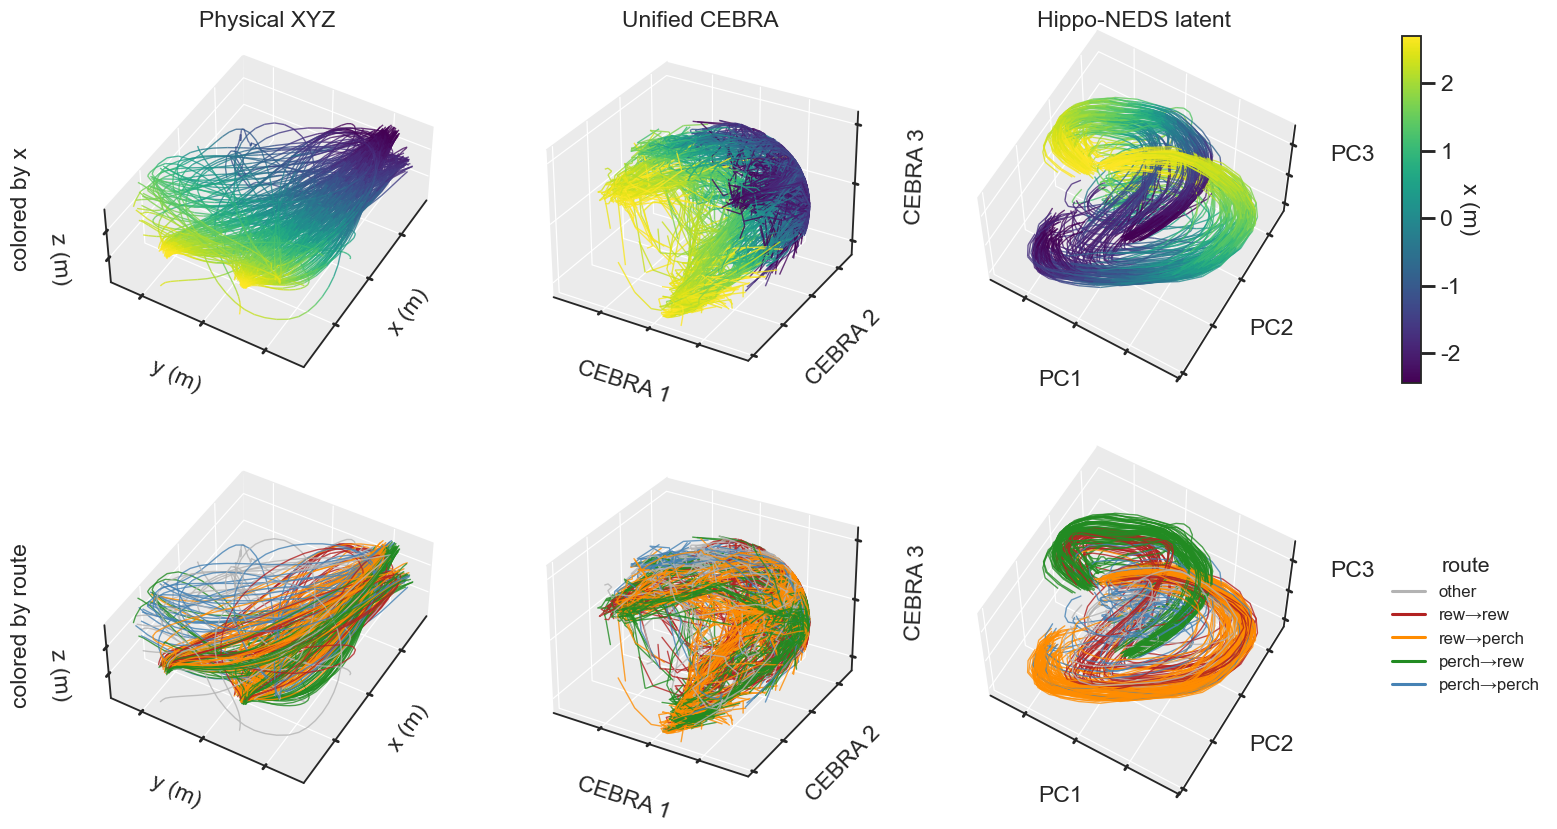

In [115]:
# === Figure 2: physical / CEBRA / Hippo-NEDS embeddings as 3-D trajectories ===
# internals.ipynb style: every flight is one connected 3-D polyline (no bare
# points). Columns: Physical XYZ, Unified CEBRA (3-D), Hippo-NEDS latent (PCA-3
# of the 64-d latent). Top row colours each trajectory by the animal's
# x-coordinate (continuous); bottom row by flight route (categorical).
from sklearn.decomposition import PCA

MAX_FLIGHTS = 250
_rng = np.random.default_rng(0)

# --- Physical XYZ + Hippo-NEDS latent: per-flight trajectories from `emb` (indoor) ---
_ind_pt = np.array([ph.is_indoor(s) for s in emb['session']])
_pca3 = PCA(n_components=3).fit(emb['latent'][_ind_pt])
_lat3 = _pca3.transform(emb['latent'])
_colx = emb['xyz'][:, 0]  # raw metres, matching the physical x-axis
_key = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))

phys_trajs, lat_trajs, xcol, routes = [], [], [], []
for k in np.unique(_key[_ind_pt]):
    m = np.where(_key == k)[0]
    o = m[np.argsort(emb['rel_t'][m])]
    phys_trajs.append(emb['xyz'][o]); lat_trajs.append(_lat3[o])
    xcol.append(_colx[o]); routes.append(int(emb['route'][o[0]]))

# --- Unified CEBRA: per-flight 3-D embeddings from uni_te (guarded on CEBRA) ---
cebra_trajs, cebra_xcol, cebra_routes = [], [], []
if cebra_frechet is not None:
    _tmp, _cx, _cs = [], [], []
    for s in session_names:
        if not ph.is_indoor(s):
            continue
        rew, perch = get_target_locs(s)
        for embp, f in uni_te[s]:
            pos = f['pos']
            oc = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
            dc = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
            _tmp.append((np.asarray(embp), ph.route_id(oc, dc)))
            _cx.append(pos[:, 0]); _cs.append(np.full(len(pos), s))
    _zx = np.concatenate(_cx)  # raw metres
    _parts = np.split(_zx, np.cumsum([len(x) for x in _cx])[:-1])
    for (embp, r), zxi in zip(_tmp, _parts):
        cebra_trajs.append(embp); cebra_xcol.append(zxi); cebra_routes.append(r)


def _subsample(*lists, n=MAX_FLIGHTS):
    L = len(lists[0])
    if L <= n:
        return lists
    sel = np.sort(_rng.choice(L, n, replace=False))
    return tuple([lst[i] for i in sel] for lst in lists)


phys_trajs, lat_trajs, xcol, routes = _subsample(phys_trajs, lat_trajs, xcol, routes)
if cebra_trajs:
    cebra_trajs, cebra_xcol, cebra_routes = _subsample(cebra_trajs, cebra_xcol, cebra_routes)

# --- Columns in the requested order (CEBRA in the middle when available) ---
columns = [('Physical XYZ', phys_trajs, xcol, routes, ('x (m)', 'y (m)', 'z (m)'))]
if cebra_trajs:
    columns.append(('Unified CEBRA', cebra_trajs, cebra_xcol, cebra_routes,
                    ('CEBRA 1', 'CEBRA 2', 'CEBRA 3')))
columns.append(('Hippo-NEDS latent', lat_trajs, xcol, routes, ('PC1', 'PC2', 'PC3')))

ncol = len(columns)
xvlim = tuple(np.nanpercentile(np.concatenate(xcol), [2, 98]))
fig2 = plt.figure(figsize=(4.8 * ncol, 9))
top_axes, bot_axes, sm, LBL = [], [], None, 15


# Per-column 3-D view orientation (both rows of a column share one view):
#   Physical XYZ  -> 90 deg about z (y to front, x right) + slight top-down tilt
#   Unified CEBRA -> default view (no rotation)
#   Hippo-NEDS    -> 180 deg about z, then tilt back to expose the figure-8
def _set_view(ax, col):
    if col == 'Physical XYZ':
        ax.view_init(elev=ax.elev + 15, azim=ax.azim + 90)   # y front, x right, more top-down
    elif col.startswith('Hippo-NEDS'):
        ax.view_init(elev=ax.elev + 30, azim=ax.azim + 180)


def _ref_grid(ax):
    """White reference gridlines on grey panes (applied to every 3-D panel)."""
    from matplotlib.ticker import MaxNLocator
    ax.xaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.zaxis.set_major_locator(MaxNLocator(3))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)
    ax.grid(True)


for j, (title, trajs, xc, rt, axl) in enumerate(columns):
    ax0 = fig2.add_subplot(2, ncol, j + 1, projection='3d'); top_axes.append(ax0)
    sm = ph.plot_trajectories_3d(ax0, trajs, xc, cmap='viridis', vlim=xvlim, lw=0.9, show_endpoints=False)
    _set_view(ax0, title); _ref_grid(ax0)
    ax0.set_title(title, fontsize=LBL)
    ax0.set_xlabel(axl[0], fontsize=LBL); ax0.set_ylabel(axl[1], fontsize=LBL); ax0.set_zlabel(axl[2], fontsize=LBL)
    ax1 = fig2.add_subplot(2, ncol, ncol + j + 1, projection='3d'); bot_axes.append(ax1)
    ph.plot_trajectories_3d(ax1, trajs, rt, categorical=True, cat_colors=ph.ROUTE_COLORS, lw=0.9, show_endpoints=False)
    _set_view(ax1, title); _ref_grid(ax1)
    ax1.set_xlabel(axl[0], fontsize=LBL); ax1.set_ylabel(axl[1], fontsize=LBL); ax1.set_zlabel(axl[2], fontsize=LBL)
    if title == 'Physical XYZ':
        _box = tuple(np.vstack([np.asarray(t) for t in trajs]).max(0)
                     - np.vstack([np.asarray(t) for t in trajs]).min(0))
        ax0.set_box_aspect(_box); ax1.set_box_aspect(_box)
    if j == 0:
        # tuck the z-axis label inward; the row label sits outside (left of) it
        ax0.set_zlabel('z (m)', fontsize=LBL, labelpad=-4)
        ax1.set_zlabel('z (m)', fontsize=LBL, labelpad=-4)
        ax0.text2D(-0.24, 0.5, 'colored by x', transform=ax0.transAxes,
                   rotation=90, va='center', fontsize=LBL)
        ax1.text2D(-0.24, 0.5, 'colored by route', transform=ax1.transAxes,
                   rotation=90, va='center', fontsize=LBL)

# Dedicated colorbar axes to the right of the top row: unlike colorbar(ax=top_axes),
# this steals no width from the panels, so the three columns stay aligned on both rows.
_ptr = top_axes[-1].get_position()
_cax = fig2.add_axes([_ptr.x1 + 0.06, _ptr.y0, 0.012, _ptr.height])
cb = fig2.colorbar(sm, cax=_cax)
cb.set_label('x (m)', fontsize=LBL, rotation=270, labelpad=12)
handles = [plt.Line2D([], [], color=ph.ROUTE_COLORS[k], lw=2, label=ph.ROUTE_LABELS[k])
           for k in range(len(ph.ROUTE_LABELS))]
# offset right (past the PC3 z-axis label) so the legend doesn't overlap it
bot_axes[-1].legend(handles=handles, title='route', loc='center left',
                     bbox_to_anchor=(1.2, 0.5), frameon=False, fontsize=11)
ph.save_fig(fig2, 'fig2_embeddings'); plt.show()


**Figure 2 | The transformer latent embedding warps physical space to emphasise flight-route identity and align across animals.** Each point is one held-out flight time-bin from the indoor lab sessions (Datasets 1 & 3). Columns: true 3-D position (top-down x–y), the 64-dimensional transformer latent projected to 2-D (PCA followed by a rotation that separates the two dominant route lobes horizontally), and the unified-CEBRA latent (same rotation procedure). **a–c**, coloured by (per-session z-scored) x-coordinate. **d–f**, coloured by flight route (origin→destination endpoint class). Unlike physical space and the CEBRA embedding, the transformer latent segregates flights primarily by route identity rather than by instantaneous position.

---
## Figure 3 — Same route, different paths: route-progress vs absolute-space sequences

Two flight clusters that share **origin and destination** but take geometrically
different 3-D paths between them (large Fréchet distance, small endpoint gaps).
The common coordinate is each path's own cumulative arc length ("route progress").
If place cells fire at the same *fraction* of the route on both detours, the
population sequence is preserved (schematic/topological coding); if they fire at
absolute 3-D positions, the alternate-path sequence is scrambled. Example index 0.

Data are loaded from raw spike times (native `Fs`) via `Data_Prep_for_Raw`, a
separate pipeline from the binned dataloaders (ported from
`investigate_similar_trajectories.ipynb`).

In [24]:
# === Figure 3 data: raw-spike cache + same-route different-path pairs ===
from scipy.interpolate import interp1d as _interp1d
from scipy.io import loadmat as _loadmat
from itertools import combinations as _combinations
import glob as _glob
from digitalbat.utility.utils import frechet_distance as _frechet_d
from digitalbat.datasets.data import Data_Prep_for_Raw as _DPR
from notebook_helpers import get_target_locs as _get_target_locs

AP_PARENT = data_config['parent_folder']
N_DS_AP, MIN_DUR_AP, MIN_CLU_AP, MAX_ACC_AP = 100, 1.0, 3, 50.0


def _ap_load_session(sn):
    """Raw behaviour + spike times (native Fs) for one session, via Data_Prep_for_Raw."""
    folder = AP_PARENT + sn
    su = AP_PARENT + 'To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    prep = _DPR(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
                use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
                use_ripple_flag=False, only_flight_flag=True, spike_count_flag=True,
                bin_width=0.10, max_acceleration=MAX_ACC_AP)
    prep.get_all_behavior(); prep.get_all_spike(); prep.get_flight_cluster()
    fc = prep.flight_cluster_results
    bhv = _loadmat(_glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    t_bhv = bhv['t'][:, 0] if 'Dataset_2' in sn else bhv['t'][0, :]
    Fs = float(bhv['Fs'][0, 0])
    # raw spike times + merge (mirrors Data_Prep_for_Raw.get_all_spike)
    su_paths = sorted(_glob.glob(su))
    times, cids, ptypes = [], [], []
    for p in su_paths:
        gu = _loadmat(p)['out_Gunits']
        cids.append(np.array([x[0][0, 0] for x in gu['cluster_id']]))
        times.append([x[0][:, 0] / 1e6 for x in gu['spikeTimes_usec']])
        ptypes.append(list(np.array([np.squeeze(x[0]).item() if np.squeeze(x[0]).ndim == 0
                       else np.squeeze(x[0]) for x in gu['pType']], dtype=object)))
    mg = _loadmat(_glob.glob(folder + '/merges_Dataset_*.mat')[0])['merges']
    refractory = 0.001
    for ii in range(len(su_paths)):
        if len(mg[ii][0]):
            to_merge = mg[ii][0][0][0][0]
            cl, tl = cids[ii], times[ii]
            midx = [np.where(cl == cid)[0][0] for cid in to_merge]
            merged = np.sort(np.concatenate([tl[k] for k in midx]))
            clean = [merged[0]]
            for s_ in merged[1:]:
                if s_ - clean[-1] > refractory:
                    clean.append(s_)
            tl[midx[0]] = np.array(clean)
            for k in midx[1:]:
                tl[k] = np.array([])
            valid = [i for i, st in enumerate(tl) if len(st) > 0]
            times[ii] = [tl[i] for i in valid]; cids[ii] = cl[valid]
            ptypes[ii] = [ptypes[ii][i] for i in valid]
    spike_times = [st for probe in times for st in probe]
    pType = np.array([pt for probe in ptypes for pt in probe], dtype=object)
    return dict(r=bhv['r'], t=t_bhv, Fs=Fs, v=bhv['v'], spike_times=spike_times,
                pType=pType, fc_results=fc)


def _ds_traj(r, fs, fe, n=N_DS_AP):
    fs, fe = int(fs), int(fe); traj = r[fs:fe + 1]
    to = np.linspace(0, 1, traj.shape[0]); td = np.linspace(0, 1, n)
    return np.column_stack([_interp1d(to, traj[:, d])(td) for d in range(3)])


session_data_cache = {}
for sn in session_names:
    try:
        d = _ap_load_session(sn)
    except Exception as exc:
        print(f'  [Fig3 skip {sn}] {type(exc).__name__}: {exc}'); continue
    fc, Fs = d['fc_results'], d['Fs']
    recs = []
    for i in range(fc['N']):
        dur = (fc['stop_frame'][i] - fc['start_frame'][i]) / Fs
        if dur < MIN_DUR_AP:
            continue
        pos = d['r'][fc['start_frame'][i]:fc['stop_frame'][i] + 1]
        acc = np.gradient(np.gradient(pos, 1.0 / Fs, axis=0), 1.0 / Fs, axis=0)
        if np.linalg.norm(acc, axis=1).max() > MAX_ACC_AP:
            continue
        recs.append(dict(cluster_id=int(fc['id'][i]), f_start=int(fc['start_frame'][i]),
                         f_stop=int(fc['stop_frame'][i]), duration=dur))
    dff = pd.DataFrame(recs)
    ci = {}
    for cid, grp in dff.groupby('cluster_id'):
        if len(grp) < MIN_CLU_AP:
            continue
        trajs = np.stack([_ds_traj(d['r'], row.f_start, row.f_stop) for _, row in grp.iterrows()])
        ci[int(cid)] = dict(n_flights=len(grp), mean_traj=np.nanmean(trajs, 0))
    session_data_cache[sn] = dict(data=d, df_flights=dff, cluster_info=ci)
    print(f'  {sn}: {len(dff)} flights, {len(ci)} clusters')

# --- same-route, different-path candidate pairs (shared endpoints, high Fréchet) ---
AP_ENDPOINT_THRESH, AP_MIN_FRECHET, AP_MIN_FLIGHTS, AP_LABEL_THRESH = 0.6, 1.0, 5, 1.0


def _endpoint_label(sess, xyz):
    rew, perch = _get_target_locs(sess)
    dr = float(np.min(np.linalg.norm(rew - xyz, axis=1)))
    dp = float(np.min(np.linalg.norm(perch - xyz, axis=1)))
    if min(dr, dp) > AP_LABEL_THRESH:
        return 'other'
    return 'reward' if dr <= dp else 'perch'


_apc = []
for sess, cached in session_data_cache.items():
    big = {c: i for c, i in cached['cluster_info'].items() if i['n_flights'] >= AP_MIN_FLIGHTS}
    for a, b in _combinations(big, 2):
        ta, tb = big[a]['mean_traj'], big[b]['mean_traj']
        sg, eg = float(np.linalg.norm(ta[0] - tb[0])), float(np.linalg.norm(ta[-1] - tb[-1]))
        if max(sg, eg) > AP_ENDPOINT_THRESH:
            continue
        fr = float(_frechet_d(ta, tb))
        if fr < AP_MIN_FRECHET:
            continue
        _apc.append(dict(session=sess, bat=parse_bat(sess), cluster_a=a, cluster_b=b,
                         n_flights_a=big[a]['n_flights'], n_flights_b=big[b]['n_flights'],
                         start_gap=sg, end_gap=eg, frechet=fr,
                         score=min(big[a]['n_flights'], big[b]['n_flights']) * fr))
df_altpath = pd.DataFrame(_apc)
if len(df_altpath):
    df_altpath['route_type'] = [
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][0]) + '→' +
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][-1])
        for s, a in zip(df_altpath.session, df_altpath.cluster_a)]
    df_altpath = df_altpath.sort_values('score', ascending=False).reset_index(drop=True)
print(f'\n{len(df_altpath)} same-route different-path pairs')
df_altpath.head(8)


  Acceleration filter: removed 1/136 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_14543_240420: 130 flights, 4 clusters
  Dataset_3_14543_240421: 113 flights, 5 clusters
  Acceleration filter: removed 9/154 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240402: 137 flights, 6 clusters
  Acceleration filter: removed 4/131 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240403: 124 flights, 5 clusters
  Acceleration filter: removed 1/79 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240404: 77 flights, 3 clusters
  Acceleration filter: removed 1/78 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231208: 76 flights, 4 clusters
  Acceleration filter: removed 1/77 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231209: 75 flights, 4 clusters
  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Dataset_1_32622_231009: 78 flights, 7 clusters
  Dataset_1_32622_231010: 94 flights, 5 clusters
  Acceleration filter: removed 1/98 flights (peak |acc| > 50.0 m/s²)


,session,bat,cluster_a,cluster_b,n_flights_a,n_flights_b,start_gap,end_gap,frechet,score,route_type
0,Dataset_1_32622_231010,32622,10,11,43,13,0.126042,0.103677,1.974863,25.673225,reward→reward
1,Dataset_1_32622_231009,32622,15,16,10,19,0.025309,0.042311,1.740129,17.401289,reward→reward
2,Dataset_2_14445_231209,14445,2,3,6,28,0.210797,0.056653,2.357523,14.145136,reward→perch
3,Dataset_2_14445_231209,14445,1,3,5,28,0.208222,0.175107,2.334816,11.674081,reward→perch
4,Dataset_3_00000_240405,00000,28,31,5,29,0.254355,0.196951,1.823405,9.117027,reward→perch


In [46]:
# === Figure 3 analysis + composite plot for one route pair (reused by ED Fig 7) ===
from scipy.stats import wilcoxon as _wilcoxon, spearmanr as _spearmanr

AP_N_PROG, AP_N_TIME, AP_ACTIVE_HZ = 40, 40, 1.0
AP_N_SHUF_PC, AP_N_SHUF_SEQ = 100, 2000
_pe = np.linspace(0, 1, AP_N_PROG + 1); _pc = (_pe[:-1] + _pe[1:]) / 2
_te = np.linspace(0, 1, AP_N_TIME + 1); _tc = (_te[:-1] + _te[1:]) / 2


def _prog(pos):
    s = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(pos, axis=0), axis=1))])
    return s / max(s[-1], 1e-9)


def _route_example(idx, seed_=0):
    """Compute maps, cross-validated place cells, PV correlation + lag, and the three
    sequence-preservation tests for df_altpath row `idx`. Returns a results dict."""
    rng = np.random.default_rng(seed_)
    row = df_altpath.iloc[idx]
    sess, a, b = row.session, int(row.cluster_a), int(row.cluster_b)
    d = session_data_cache[sess]['data']; dff = session_data_cache[sess]['df_flights']
    ci = session_data_cache[sess]['cluster_info']
    REF, ALT = (a, b) if ci[a]['n_flights'] >= ci[b]['n_flights'] else (b, a)
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    ref_len = float(np.sum(np.linalg.norm(np.diff(ci[REF]['mean_traj'], axis=0), axis=1)))

    def maps(fldf, offsets=None, space_only=False):
        occ = np.zeros(AP_N_PROG); sp = np.zeros((nu, AP_N_PROG)); rt = np.zeros((nu, AP_N_TIME)); nfl = 0
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            prog = _prog(d['r'][fs:fe + 1]); rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]; tbin = dur / AP_N_TIME
            occ += np.histogram(prog, bins=_pe)[0] * dt; nfl += 1
            for u in range(nu):
                st = d['spike_times'][u]; st = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(st) == 0:
                    continue
                rel = (st - ft[0] + off) % dur
                sp[u] += np.histogram(np.interp(rel, rel_t, prog), bins=_pe)[0]
                if not space_only:
                    rt[u] += np.histogram((st - ft[0]) / dur, bins=_te)[0] / tbin
        return dict(rate_prog=sp / np.maximum(occ, 1e-9), occ=occ, rate_time=rt / max(nfl, 1), n=nfl)

    def _si(rate, occ):
        p = occ / occ.sum(); lam = (p * rate).sum()
        if lam <= 0:
            return 0.0
        nz = rate > 0
        return float((p[nz] * rate[nz] * np.log2(rate[nz] / lam)).sum() / lam)

    def _rowcorr(M1, M2):
        A = M1 - M1.mean(1, keepdims=True); B = M2 - M2.mean(1, keepdims=True)
        den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
        return np.where(den > 0, (A * B).sum(1) / np.maximum(den, 1e-12), np.nan)

    # cross-validated place cells on the reference route-progress map
    ref_all = dff[dff.cluster_id == REF].sample(frac=1.0, random_state=0).reset_index(drop=True)
    nR = len(ref_all); j1, j2 = int(round(0.5 * nR)), int(round(0.75 * nR))
    tr, va, te = ref_all.iloc[:j1], ref_all.iloc[j1:j2], ref_all.iloc[j2:]
    tr_m = maps(tr); held = maps(pd.concat([va, te]), space_only=True)
    si = np.array([_si(tr_m['rate_prog'][u], tr_m['occ']) for u in range(nu)])
    r_obs = _rowcorr(tr_m['rate_prog'], held['rate_prog'])
    hd = [d['t'][int(fr.f_stop)] - d['t'][int(fr.f_start)] for _, fr in pd.concat([va, te]).iterrows()]
    r_null = np.empty((AP_N_SHUF_PC, nu))
    for s_ in range(AP_N_SHUF_PC):
        hm = maps(pd.concat([va, te]), offsets=[rng.uniform(0, x) for x in hd], space_only=True)
        r_null[s_] = _rowcorr(tr_m['rate_prog'], hm['rate_prog'])
    pcv = np.nanmean(r_null >= r_obs[None, :], axis=0)
    peak_tr = tr_m['rate_prog'].max(1)
    place = (pcv < 0.05) & (peak_tr >= AP_ACTIVE_HZ) & (si > 0) & np.isfinite(r_obs)
    pc = np.where(place)[0]

    ref_vt = maps(pd.concat([va, te])); alt = maps(dff[dff.cluster_id == ALT])
    order = pc[np.argsort(tr_m['rate_time'][pc].argmax(1))] if len(pc) else pc

    # PV corr (ref x alt, normalized time) + mean PV corr vs lag
    def _norm(M):
        return M / np.maximum(M.max(1, keepdims=True), 1e-9)
    Rr, Ra = _norm(ref_vt['rate_time']), _norm(alt['rate_time'])
    A = Rr[pc] - Rr[pc].mean(0); B = Ra[pc] - Ra[pc].mean(0)
    PV = (A.T @ B) / (np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(B, axis=0)) + 1e-9)
    nlag = PV.shape[0]; lags = np.arange(-nlag + 1, nlag)
    pv_lag = np.array([np.nanmean(np.diagonal(PV, offset=k)) for k in lags])
    peak_lag = lags[np.nanargmax(pv_lag)] / nlag

    # three preservation tests (normalized time, place cells), one-sided shuffle p
    def _pv(A_, B_):
        Az, Bz = A_ - A_.mean(0), B_ - B_.mean(0)
        den = np.sqrt((Az ** 2).sum(0) * (Bz ** 2).sum(0))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(0) / den, np.nan)))

    def _mc(A_, B_):
        Az, Bz = A_ - A_.mean(1, keepdims=True), B_ - B_.mean(1, keepdims=True)
        den = np.sqrt((Az ** 2).sum(1) * (Bz ** 2).sum(1))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))

    def _roll(M):
        return np.array([np.roll(M[i], rng.integers(M.shape[1])) for i in range(len(M))])

    def _p(obs, null):
        return float((1 + np.sum(np.asarray(null) >= obs)) / (len(null) + 1))

    rr, ra = ref_vt['rate_time'][pc], alt['rate_time'][pc]
    tests = None
    if len(pc) >= 4:
        po, pa = rr.argmax(1), ra.argmax(1)
        rho = float(_spearmanr(po, pa)[0])
        p1 = _p(rho, [float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)])
        Rrn, Ran = _norm(rr), _norm(ra)
        pv = _pv(Rrn, Ran); p2 = _p(pv, [_pv(Rrn, _roll(Ran)) for _ in range(AP_N_SHUF_SEQ)])
        mc = _mc(rr, ra); p3 = _p(mc, [_mc(rr, _roll(ra)) for _ in range(AP_N_SHUF_SEQ)])
        tests = dict(rho=rho, p_order=p1, pv=pv, p_pv=p2, mc=mc, p_mapcorr=p3,
                     null1=[float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)],
                     null2=[_pv(Rrn, _roll(Ran)) for _ in range(500)],
                     null3=[_mc(rr, _roll(ra)) for _ in range(500)])
    return dict(idx=idx, session=sess, bat=parse_bat(sess), REF=REF, ALT=ALT,
                route=row.get('route_type', '?'), frechet=row.frechet,
                traj_ref=ci[REF]['mean_traj'], traj_alt=ci[ALT]['mean_traj'],
                ref_time=ref_vt['rate_time'], alt_time=alt['rate_time'], order=order,
                n_place=len(pc), PV=PV, lags=lags / nlag, pv_lag=pv_lag, peak_lag=peak_lag,
                ref_len=ref_len, tests=tests)


def plot_route_example(res, save_name):
    """Two-row composite arranged [[a, b, b], [d, e, f]]:
    a = top-down view, b = Path 1/Path 2 sequence heatmaps, d = PV-corr matrix,
    e = mean PV corr vs lag (asterisks = PV zero-lag test), f = Spearman-order test."""
    pal = sns.color_palette()  # deep: [2]=green, [5]=brown
    ta, tb = res['traj_ref'], res['traj_alt']
    t = res['tests']
    _stars = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1], hspace=0.4, wspace=0.45)
    # --- (a) top-down trajectories ---
    ax_a = fig.add_subplot(gs[0, 0])
    for tt, c, lab in [(ta, pal[2], 'Path 1'), (tb, pal[5], 'Path 2')]:
        ax_a.plot(tt[:, 0], tt[:, 1], '-', color=c, lw=2.5, label=lab)
        m = len(tt) // 2
        ax_a.annotate('', xy=tt[m + 3, :2], xytext=tt[m - 3, :2],
                      arrowprops=dict(arrowstyle='->', color=c, lw=2))
    ax_a.scatter(*ta[0, :2], marker='^', s=70, facecolors='#ff7f0e', edgecolors='k', linewidths=0.6, zorder=5)
    ax_a.scatter(*ta[-1, :2], marker='s', s=70, facecolors='deeppink', edgecolors='k', linewidths=0.6, zorder=5)
    ax_a.set_aspect('equal'); ax_a.set(xlabel='x (m)', ylabel='y (m)')
    ax_a.set_title('Top-down view', pad=12)
    ax_a.legend(loc='upper right', bbox_to_anchor=(1.02, -0.42), ncol=2, fontsize=15, frameon=False)
    # --- (b) two sequence heatmaps spanning the right two columns, shared colorbar ---
    order = res['order']  # order chosen from TRAIN; heatmaps plot held-out val+test
    hm_gs = gs[0, 1:].subgridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.1)
    hm_axes = [fig.add_subplot(hm_gs[0, 0]), fig.add_subplot(hm_gs[0, 1])]
    cax = fig.add_subplot(hm_gs[0, 2])
    for k, (M, name) in enumerate([(res['ref_time'], 'Path 1 (val + test)'), (res['alt_time'], 'Path 2')]):
        ax = hm_axes[k]
        H = M[order] / np.maximum(M[order].max(1, keepdims=True), 1e-9) if len(order) else M[:0]
        sns.heatmap(H, ax=ax, cmap='magma', vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=False)
        ax.set(xlabel='normalized time', title=name)
        nt = H.shape[1]
        ax.set_xticks([0, nt / 2, nt]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        if k == 0 and len(order):
            ax.set_ylabel('Place cells,\nsorted by Path 1 (train)')
            ax.set_yticks([0.5, len(order) - 0.5]); ax.set_yticklabels(['1', str(len(order))], rotation=0)
        else:
            ax.set_ylabel('')
    if len(order):
        cb = fig.colorbar(hm_axes[1].collections[0], cax=cax)
        cb.set_label('normalized firing', rotation=270, labelpad=12, va='bottom')
    else:
        cax.axis('off')
    # --- (d) PV-corr matrix ---
    ax_d = fig.add_subplot(gs[1, 0])
    sns.heatmap(res['PV'], ax=ax_d, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False, cbar_kws=dict(label='PV corr'))
    ax_d.collections[0].colorbar.set_label('PV corr', rotation=270, labelpad=4, va='bottom')
    ax_d.set(xlabel='Path 2 (norm time)', ylabel='Path 1 (norm time)')
    ax_d.set_title('Population vector correlation across paths', pad=18)
    _npv = res['PV'].shape[0]
    ax_d.set_xticks([0, _npv / 2, _npv]); ax_d.set_xticklabels(['0', '0.5', '1'], rotation=0)
    ax_d.set_yticks([0, _npv / 2, _npv]); ax_d.set_yticklabels(['0', '0.5', '1'], rotation=0)
    ax_d.set_box_aspect(1)
    # --- (e) mean PV corr vs lag; asterisks from the PV zero-lag permutation test ---
    recs = []
    ax_e = fig.add_subplot(gs[1, 1])
    ax_e.plot(res['lags'], res['pv_lag'], color='k')
    ax_e.axvline(0, color='black', ls='--', zorder=4)  # tau=0 reference
    ax_e.set(xlabel='lag (\u03c4)', ylabel='mean PV corr')
    if t is not None:
        ax_e.text(0.5, 1.02, _stars(t['p_pv']), transform=ax_e.transAxes, ha='center', va='bottom',
                  color='black', fontsize=ax_e.xaxis.label.get_fontsize())
        recs.append(dict(session=res['session'], test='PV zero-lag corr', obs=round(t['pv'], 3), p=t['p_pv'], n_place=res['n_place']))
    # --- (f) Spearman rho (order) shuffle test ---
    ax_f = fig.add_subplot(gs[1, 2])
    if t is not None:
        sns.histplot(t['null1'], bins=30, ax=ax_f, color='lightgray', stat='density')
        ax_f.axvline(t['rho'], color='red', lw=2)
        ax_f.set(xlabel='Spearman \u03c1 (order)')
        ax_f.text(0.5, 1.02, _stars(t['p_order']), transform=ax_f.transAxes, ha='center', va='bottom',
                  color='black', fontsize=ax_f.xaxis.label.get_fontsize())
        recs.append(dict(session=res['session'], test='Spearman \u03c1 (order)', obs=round(t['rho'], 3), p=t['p_order'], n_place=res['n_place']))
    else:
        ax_f.axis('off')
    ph.save_fig(fig, save_name); plt.show()
    return recs


/tmp/ipykernel_1248728/1235750612.py:95: RuntimeWarning: invalid value encountered in divide
  return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))


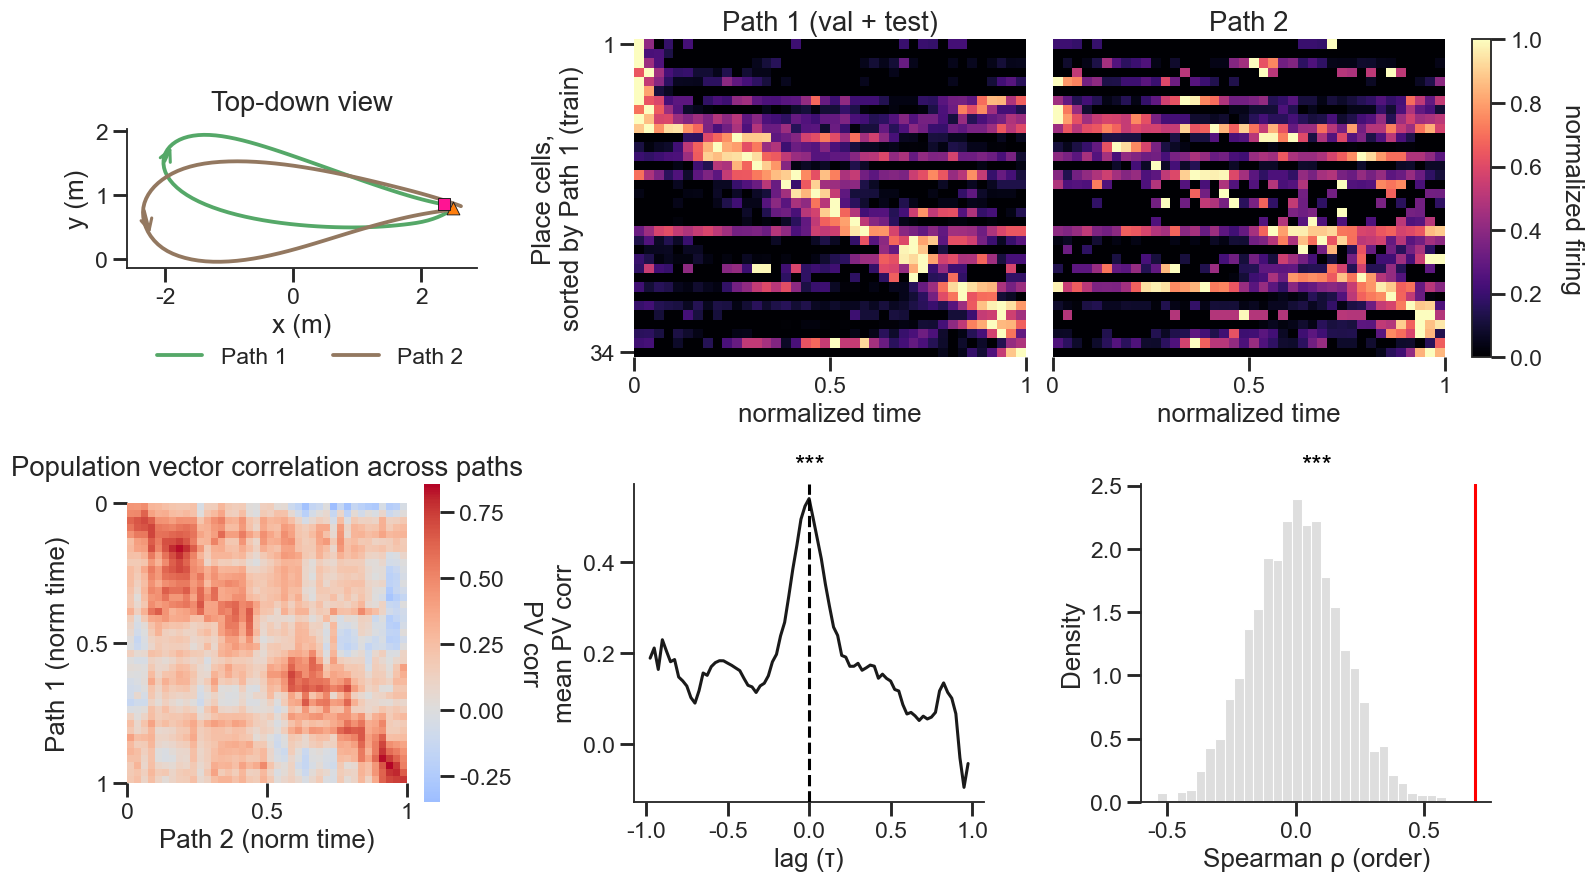

Figure 3 — Dataset_1_32622_231010 (bat 32622): Path 1 = cl 10 vs Path 2 = cl 11 [reward→reward], Fréchet 2.0 m, 34 place cells. Bottom row: observed statistic (red) vs shuffle null (grey).
Sequence-preservation tests (one-sided shuffle p):
               session               test   obs         p  n_place stars         P
Dataset_1_32622_231010   PV zero-lag corr 0.539 0.0004998       34   *** P < 0.001
Dataset_1_32622_231010 Spearman ρ (order) 0.699 0.0004998       34   *** P < 0.001


,session,test,obs,p,n_place,stars,P
0,Dataset_1_32622_231010,PV zero-lag corr,0.539,0.0005,34,***,P < 0.001
1,Dataset_1_32622_231010,Spearman ρ (order),0.699,0.0005,34,***,P < 0.001


In [47]:
# Figure 3: example index 0
res0 = _route_example(0)
p3 = plot_route_example(res0, 'fig3_route_example0')
print(f'Figure 3 — {res0["session"]} (bat {res0["bat"]}): Path 1 = cl {res0["REF"]} vs '
      f'Path 2 = cl {res0["ALT"]} [{res0["route"]}], Fréchet {res0["frechet"]:.1f} m, '
      f'{res0["n_place"]} place cells. Bottom row: observed statistic (red) vs shuffle null (grey).')
print('Sequence-preservation tests (one-sided shuffle p):')
ph.p_table(p3)

**Figure 3 | Same route, different paths — the population sequence follows route progress.** Two flight clusters (ref = more flights, alt) share origin (green) and destination (red) but take geometrically different 3-D paths. **a**, Mean 3-D trajectories. **b**, Top-down projection. **c**, Place-cell firing-rate sequences in normalized flight time on the reference (held-out) and alternate paths, sorted by reference-path peak time; a preserved diagonal on the alternate path indicates route-progress coding. **d**, Population-vector correlation between reference and alternate paths across normalized time. **e**, Mean PV correlation vs lag, peaking near zero when the sequence is preserved. **f–h**, Three sequence-preservation tests against shuffle nulls (grey): Spearman rank correlation of firing-time order, zero-lag population-vector correlation (per-cell circular-roll null), and mean per-cell tuning-curve correlation (roll null). Place cells are identified by significant cross-validated route-progress spatial information on the reference path. Exact *P* values are printed above.

---
## Extended Data Figure 7 — same route, different paths (other examples)

The other four same-route different-path pairs, each arranged identically to
Figure 3 and labelled by bat.

In [ ]:
# ED Fig 7: the other four route examples (indices 1-4), identical layout, bat-labelled.
ed6_records = []
for _i in range(1, min(5, len(df_altpath))):
    _res = _route_example(_i)
    ed6_records.extend(plot_route_example(_res, f'edfig7_route_example{_i}'))
if ed6_records:
    print('ED Fig 7 — sequence-preservation tests (one-sided shuffle p):')
    ph.p_table(ed6_records)


**Extended Data Figure 7 | Same route, different paths — additional examples.** Panels as in Figure 3, for the remaining four same-route different-path cluster pairs (one composite per pair, titled with session and bat id). Each shows the two 3-D paths, top-down projection, reference/alternate sequence heatmaps, population-vector correlation and lag, and the three sequence-preservation tests with shuffle nulls.

---
## Figure 4 — Readout weights surface correlations in spatial and non-spatial activity

**a** PC1 of the readout-weight correlation vs mean firing rate, per session. **b** Residual-readout hierarchical clustering (dendrogram, similarity matrix, residual-readout matrix). **c–f, h, i** Mantel comparisons of the residual readout against non-flight rest, sleep, rate-map and coupling similarity. **g** Residual readouts predict CA1 vs CA3 membership (SVM). **j–k** Attribution matrices (example; future−past by cluster).

> Panels **c–f, h, i** build the rate-map, non-flight-rest and coupling similarity streams directly (rate maps from flight spikes; non-flight from a per-session `Data_Prep` load; coupling from the GLM+history+coupling checkpoint). The **sleep** matrix (5th panel of **c**) matches flight units to Dataset_0 sleep units via UnitMatch `MatchTable.csv` files (guarded — skipped if those / the Dataset_0 spike files are absent).

In [ ]:
# === Figure 4 foundation: per-neuron readout weights + metadata + subregion ===
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# Per-neuron table: unit-normed readout rows, pType, probe, position, mean FR.
_rows, _W = [], []
for sn in dataloaders['test']:
    W = bat_former.readouts[sn][0].weight.detach().cpu().numpy()   # (K, D)
    pos = np.asarray(meta_info_dict['neuron_position'][sn])
    ptype = np.asarray(meta_info_dict['pType'][sn])
    probe = np.asarray(meta_info_dict['probe_id'][sn])
    # mean FR from test spikes
    yl, ml = [], []
    for b in dataloaders['test'][sn]:
        yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    ya, ma = np.vstack(yl), np.vstack(ml)
    mfr = ya[ma == 1.0].mean(0) / bin_width
    for u in range(W.shape[0]):
        pt = ptype[u] if not isinstance(ptype[u], np.ndarray) else 'filtered'
        _rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, pType=str(pt),
                          probe_id=int(probe[u]), lateral=float(pos[u, 0]),
                          depth=float(pos[u, 1]), mean_fr=float(mfr[u])))
    _W.append(W)
readout_df = pd.DataFrame(_rows)
W_all = np.vstack(_W)
readout_df['readout_weight'] = list(W_all / np.linalg.norm(W_all, axis=1, keepdims=True))

# Attach joint per-neuron corr/FDE (computed for Fig 1d/e).
_jm = encode_metrics_df[encode_metrics_df['model'] == 'joint'][['session', 'unit', 'corr', 'fde']]
readout_df = readout_df.merge(_jm.rename(columns={'corr': 'corr_all', 'fde': 'fde_all'}),
                              on=['session', 'unit'], how='left')


# --- Subregion (CA1/CA3) from per-(bat,probe) depth clumps (internals recipe) ---
CLUMP_HW, PEAK_DIST, HBIN, SM_SIGMA, PROM = 300, 450, 25, 200, 0.04


def detect_clumps(depths):
    if len(depths) < 5:
        return np.array([])
    lo = np.floor(depths.min() / HBIN) * HBIN
    hi = np.ceil(depths.max() / HBIN) * HBIN + HBIN
    counts, edges = np.histogram(depths, bins=np.arange(lo, hi, HBIN))
    centers = 0.5 * (edges[:-1] + edges[1:])
    sm = gaussian_filter1d(counts.astype(float), sigma=SM_SIGMA / HBIN)
    if sm.max() == 0:
        return np.array([])
    padded = np.concatenate([[0.0], sm, [0.0]])
    pk, _ = find_peaks(padded, distance=max(1, PEAK_DIST // HBIN), prominence=PROM * sm.max())
    pk = pk - 1
    pk = pk[(pk >= 0) & (pk < len(sm))]
    if len(pk) == 0:
        pk = np.array([int(np.argmax(sm))])
    if len(pk) > 2:
        pk = pk[np.argsort(sm[pk])[::-1][:2]]
    return np.sort(centers[pk])


def _window(peak, lo, hi):
    a, b = peak - CLUMP_HW, peak + CLUMP_HW
    if b > hi:
        b, a = hi, hi - 2 * CLUMP_HW
    elif a < lo:
        a, b = lo, lo + 2 * CLUMP_HW
    return a, b


readout_df['subregion'] = None
for (bat, probe), grp in readout_df.groupby(['bat', 'probe_id']):
    d = grp['depth'].values
    peaks = detect_clumps(d)
    if len(d) == 0 or len(peaks) == 0:
        continue
    dlo, dhi = float(np.nanmin(d)), float(np.nanmax(d))
    labels = np.array([None] * len(d), dtype=object)
    if len(peaks) == 1:
        a, b = _window(peaks[0], dlo, dhi)
        labels[(d >= a) & (d <= b)] = 'CA1'
    else:
        ventral, dorsal = peaks[0], peaks[-1]
        la, lb = _window(dorsal, dlo, dhi)
        va, vb = _window(ventral, dlo, dhi)
        if vb > la:
            vb, va = la, la - 2 * CLUMP_HW
        labels[(d >= la) & (d <= lb)] = 'CA1'
        labels[(d >= va) & (d <= vb)] = 'CA3'
    readout_df.loc[grp.index, 'subregion'] = labels


def residual_readout(W, fr):
    """Project centered mean-FR axis out of unit-normed rows W, renormalise."""
    ax = W.T @ (fr - fr.mean())
    n = np.linalg.norm(ax)
    Wr = W - np.outer(W @ (ax / n), ax / n) if n > 0 else W.copy()
    rn = np.linalg.norm(Wr, axis=1, keepdims=True); rn[rn == 0] = 1.0
    return Wr / rn


# Well-fit cells (corr_all > 0.2), residual readout per session.
clu_df = readout_df[readout_df['corr_all'] > 0.2].copy().reset_index(drop=True)
clu_df['readout_weight_residual'] = clu_df['readout_weight']
for _, grp in clu_df.groupby('session'):
    Wr = residual_readout(np.stack(grp['readout_weight'].values), grp['mean_fr'].values)
    for j, ix in zip(range(len(grp)), grp.index):
        clu_df.at[ix, 'readout_weight_residual'] = Wr[j]
print('readout_df:', len(readout_df), 'neurons |', readout_df['subregion'].notna().sum(),
      'with subregion | clu_df well-fit:', len(clu_df))

In [ ]:
# === Fig 4c-f/h/i data streams: rate maps, non-flight rest corr, coupling ===
# Ported from internals.ipynb (rate maps, non-flight Data_Prep load, coupling GLM).
from digitalbat.datasets.data import Data_Prep_for_Raw
from notebook_helpers import loc_bin_width_rm

# (1) Per-neuron 2D rate maps (observed spikes / occupancy) per session.
session_rate_maps, session_occ = {}, {}
for sn, sd in dataloaders['test'].items():
    Xl, yl, ml = [], [], []
    for b in sd:
        Xl.append(b.behavior.numpy()); yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    Xa, ya, ma = np.vstack(Xl), np.vstack(yl), np.vstack(ml)
    bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
    xlim, ylim = meta_info_dict['r_lim'][sn][0], meta_info_dict['r_lim'][sn][1]
    xe = np.arange(xlim[0], xlim[1] + loc_bin_width_rm, loc_bin_width_rm)
    ye = np.arange(ylim[0], ylim[1] + loc_bin_width_rm, loc_bin_width_rm)
    v = ma == 1.0
    lx = Xa[:, :, 0][v] * bs[0, 0, 0] + bm[0, 0, 0]
    ly = Xa[:, :, 1][v] * bs[0, 0, 1] + bm[0, 0, 1]
    spk = ya[v]
    occ, _, _ = np.histogram2d(lx, ly, bins=[xe, ye])
    under = occ < 3
    maps = np.full((spk.shape[1], (len(xe) - 1) * (len(ye) - 1)), np.nan)
    for u in range(spk.shape[1]):
        sm, _, _ = np.histogram2d(lx, ly, bins=[xe, ye], weights=spk[:, u])
        with np.errstate(divide='ignore', invalid='ignore'):
            rm = sm / (occ * bin_width)
        rm[under] = np.nan
        maps[u] = rm.ravel()
    session_rate_maps[sn] = maps
    session_occ[sn] = occ.ravel()

# (2) Non-flight rest correlation matrices (sqrt counts) per session.
nonflight_corr = {}
for sn in session_names:
    folder = data_config['parent_folder'] + sn
    su = data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    kw = dict(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
              use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
              use_ripple_flag=False, spike_count_flag=True, bin_width=bin_width)
    try:
        dpf = Data_Prep_for_Raw(only_flight_flag=True, **kw)
        dpf.get_all_behavior(); dpf.get_all_spike()
        dpa = Data_Prep_for_Raw(only_flight_flag=False, **kw)
        dpa.get_all_behavior(); allspk = dpa.get_all_spike()
        nf = np.setdiff1d(np.arange(allspk.shape[1]), dpf.flight_ind)
        nonflight_corr[sn] = np.corrcoef(np.sqrt(allspk[:, nf]))
    except Exception as exc:
        print(f'  [nonflight skip {sn}] {type(exc).__name__}: {exc}')

# (3) Pairwise coupling similarity from the GLM+hist+coupling checkpoint.
session_coupling_sim = {}
COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_full_v2.pth'
if os.path.exists(COUP_CKPT):
    cs = torch.load(COUP_CKPT, map_location='cpu', weights_only=False)
    kint = cs['coup_basis'].numpy().sum(0) * bin_width
    for k, v in cs.items():
        if k.startswith('coup_weights.'):
            K = v.numpy() @ kint
            np.fill_diagonal(K, 0.0)
            Csym = 0.5 * (K + K.T); np.fill_diagonal(Csym, 0.0)
            session_coupling_sim[k.split('coup_weights.', 1)[1]] = Csym
print(f'streams: {len(session_rate_maps)} rate-map, {len(nonflight_corr)} non-flight, '
      f'{len(session_coupling_sim)} coupling sessions')


def ratemap_corr_matrix(maps):
    """Pairwise Pearson r between neurons' rate maps over jointly-valid bins."""
    n = maps.shape[0]
    C = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i, n):
            m = np.isfinite(maps[i]) & np.isfinite(maps[j])
            if m.sum() >= 5 and maps[i, m].std() > 0 and maps[j, m].std() > 0:
                C[i, j] = C[j, i] = np.corrcoef(maps[i, m], maps[j, m])[0, 1]
    return C


session_sleep_corr = {}   # populated by the sleep-matching cell below


def session_matrices(sn):
    """Well-fit-neuron submatrices (nonflight, residual readout, rate map, coupling)
    for one session, all ordered by the session's clu_df units. Missing streams -> None."""
    grp = clu_df[clu_df['session'] == sn]
    units = grp['unit'].to_numpy()
    if len(units) < 6 or sn not in nonflight_corr:
        return None
    Wr = np.stack(grp['readout_weight_residual'].values)
    out = dict(units=units, grp=grp,
               nonflight=nonflight_corr[sn][np.ix_(units, units)],
               residual=Wr @ Wr.T,
               ratemap=ratemap_corr_matrix(session_rate_maps[sn][units]),
               coupling=(session_coupling_sim[sn][np.ix_(units, units)]
                         if sn in session_coupling_sim else None),
               sleep=session_sleep_corr.get(sn))
    return out


In [ ]:
# === Fig 4c sleep matrix: match flight units to Dataset_0 sleep units (UnitMatch) ===
# Ported from internals.ipynb. For each flight session with a sleep pair, map its
# Kilosort cluster ids to the sleep-session (Dataset_0) cluster ids via UnitMatch
# MatchTables, bin the sleep spikes, and build a per-session sleep FR-correlation
# matrix over the well-fit (clu_df) neurons (NaN where unmatched / silent). Guarded:
# sessions without MatchTable / Dataset_0 SU files are skipped.
from pathlib import Path

UM_ROOT = Path('/mnt/s5adam/Angelo/NP_datasets/UnitMatch')
SLEEP_PAIRS = {
    'Dataset_3_00000_240403': 'Dataset_0_00000_240403',
    'Dataset_3_00000_240404': 'Dataset_0_00000_240404',
    'Dataset_3_14543_240420': 'Dataset_0_14543_240420',
    'Dataset_3_29959_240403': 'Dataset_0_29959_240403',
    'Dataset_3_29959_240404': 'Dataset_0_29959_240404',
}


def _load_match_table(animal, date, probe):
    p = UM_ROOT / 'matches' / f'{animal}_{date}' / f'probe{probe}' / 'MatchTable.csv'
    return pd.read_csv(p) if p.is_file() else None


def _build_flight_to_sleep_map(animal, date):
    mapping = {}
    for probe in (1, 2, 3):
        df = _load_match_table(animal, date, probe)
        if df is None:
            continue
        cross = df[(df['RecSes 1'] != df['RecSes 2']) & (df['Matches'] == 1) & (df['RecSes 1'] == 1)]
        best = cross.sort_values('UM Probabilities', ascending=False).drop_duplicates('ID2', keep='first')
        for _, r in best.iterrows():
            mapping[(probe, int(r['ID2']))] = int(r['ID1'])
    return mapping


def _flight_cluster_ids(sn):
    dp = Data_Prep_for_Raw(
        parent_folder=data_config['parent_folder'] + '/' + sn,
        su_file_path=data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat',
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=bin_width, only_flight_flag=True)
    dp.get_all_behavior(); dp.get_all_spike()
    return dp.cluster_id, dp.probe_id + 1   # data.py 0-indexed; UnitMatch uses probe 1..3


def _bin_ds0_spikes(ds0_session, sleep_clu_per_probe):
    binned = {}
    for probe in (1, 2, 3):
        wanted = sleep_clu_per_probe.get(probe)
        if not wanted:
            continue
        path = f"{data_config['parent_folder']}/To_transfer/out_Gunits_probe{probe}_{ds0_session}.mat"
        if not Path(path).is_file():
            continue
        ou = loadmat(path)['out_Gunits']
        all_cids = np.array([int(x[0][0, 0]) for x in ou['cluster_id']])
        all_times_s = [x[0][:, 0] / 1e6 for x in ou['spikeTimes_usec']]
        t_end = max((t.max() for t in all_times_s if len(t)), default=0.0) + bin_width
        edges = np.arange(0, t_end + bin_width, bin_width)
        out = np.zeros((len(wanted), len(edges) - 1), dtype=np.int32)
        for i, cid in enumerate(wanted):
            idx = np.where(all_cids == cid)[0]
            if len(idx):
                out[i] = np.histogram(all_times_s[idx[0]], bins=edges)[0]
        binned[probe] = out
    if not binned:
        return {}
    common = min(a.shape[1] for a in binned.values())
    return {p: a[:, :common] for p, a in binned.items()}


for sn, ds0 in SLEEP_PAIRS.items():
    grp = clu_df[clu_df['session'] == sn]
    if len(grp) < 3:
        continue
    animal, date = sn.split('_')[2], sn.split('_')[3]
    try:
        cid_full, pid_full = _flight_cluster_ids(sn)
        units = grp['unit'].to_numpy()
        if units.max() >= len(cid_full):
            continue
        fcid, fpid = cid_full[units], pid_full[units]
        fts = _build_flight_to_sleep_map(animal, date)
        if not fts:
            print(f'  [sleep skip {sn}] no MatchTable'); continue
        matched = [fts.get((int(fpid[i]), int(fcid[i]))) for i in range(len(units))]
        pos = [i for i, m in enumerate(matched) if m is not None]
        if len(pos) < 3:
            print(f'  [sleep {sn}] only {len(pos)} matched'); continue
        per_probe = {p: [] for p in (1, 2, 3)}
        for i in pos:
            per_probe[int(fpid[i])].append(int(matched[i]))
        binned = _bin_ds0_spikes(ds0, {p: l for p, l in per_probe.items() if l})
        if not binned:
            print(f'  [sleep skip {sn}] no Dataset_0 SU mats'); continue
        rows, cur = [], {p: 0 for p in (1, 2, 3)}
        for i in pos:
            p = int(fpid[i]); rows.append(binned[p][cur[p]]); cur[p] += 1
        sleep_mat = np.vstack(rows)
        C = np.full((len(units), len(units)), np.nan)
        var = sleep_mat.var(1); nz = var > 0
        idx_pos = np.array(pos)[nz]
        if len(idx_pos) >= 2:
            C[np.ix_(idx_pos, idx_pos)] = np.corrcoef(np.sqrt(sleep_mat[nz]))
        session_sleep_corr[sn] = C
        print(f'  sleep {sn}: {len(pos)} matched, {sleep_mat.shape[1] * bin_width / 60:.1f} min')
    except Exception as exc:
        print(f'  [sleep skip {sn}] {type(exc).__name__}: {exc}')
print(f'sleep matrices for {len(session_sleep_corr)} sessions')


In [ ]:
# === Figure 4 (a-k) on a single canvas ===
# Layout (6 rows x 6 cols), per the requested arrangement:
#   row 0        : [a | c c c c c]            a = PC1/FR strip; c = 5 similarity matrices
#   rows 1-3     : [b b b b b b]              b = dendrogram + cosine-sim + residual-weight maps
#   row 4        : [d d | e | . | f | g]      d/e/f = Mantel + partial Mantels; g = CA1/CA3 SVM
#   row 5        : [h h h | i | j | k]        h = subregion Mantel; i = spatial info; j/k = attribution
from sklearn.decomposition import PCA as _PCA
from scipy.cluster.hierarchy import fcluster, set_link_color_palette
from scipy.spatial.distance import pdist, squareform
from scipy.stats import kruskal as _kw
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
import matplotlib.colors as mcolors

fig4 = plt.figure(figsize=(30, 34))
gs4 = fig4.add_gridspec(6, 6, height_ratios=[1.1, 1.0, 1.0, 1.0, 1.25, 1.25],
                        hspace=0.6, wspace=0.55)
ax_a = fig4.add_subplot(gs4[0, 0])
gs_c = gs4[0, 1:6].subgridspec(1, 5, wspace=0.35)
ax_c = [fig4.add_subplot(gs_c[0, i]) for i in range(5)]
gs_b = gs4[1:4, 0:6].subgridspec(1, 3, width_ratios=[1.1, 1.4, 1.4], wspace=0.25)
axb0, axb1, axb2 = (fig4.add_subplot(gs_b[0, i]) for i in range(3))
ax_d = fig4.add_subplot(gs4[4, 0:2])
ax_e = fig4.add_subplot(gs4[4, 2])
fig4.add_subplot(gs4[4, 3]).axis('off')                       # deliberate spacer
ax_f = fig4.add_subplot(gs4[4, 4])
ax_g = fig4.add_subplot(gs4[4, 5])
ax_h = fig4.add_subplot(gs4[5, 0:3])
ax_i = fig4.add_subplot(gs4[5, 3])
ax_j = fig4.add_subplot(gs4[5, 4])
ax_k = fig4.add_subplot(gs4[5, 5])

# --- a: PC1 of readout weights correlates with mean firing rate ---
_rec = []
for sn, grp in readout_df.groupby('session'):
    W = np.stack(grp['readout_weight'].values)
    if len(grp) < 4:
        continue
    pc1 = _PCA(n_components=1).fit_transform(W).ravel()
    r = np.corrcoef(pc1, grp['mean_fr'].values)[0, 1]
    _rec.append(dict(session=sn, bat=parse_bat(sn), r=abs(r)))
pc1_fr_df = pd.DataFrame(_rec)
_res = ph.onesample_session_test(pc1_fr_df, 'r', session_col='session', popmean=0.0)
sns.stripplot(data=pc1_fr_df, y='r', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(pc1_fr_df['bat'])],
              size=9, jitter=0.15, edgecolor='k', linewidth=0.4, ax=ax_a, legend=False)
ax_a.axhline(0, color='0.5', ls='--', lw=1)
ax_a.set(xlabel='', ylabel='|corr(PC1, mean FR)|', xticks=[], title='PC1 vs FR')
ph.sig_bracket(ax_a, -0.3, 0.3, _res['p'], base=0.96)
ph.bat_legend(ax_a, loc='lower right')

# --- b: residual-readout hierarchical clustering (dendrogram + matrices) ---
Wr = np.stack(clu_df['readout_weight_residual'].values)       # (N, D), unit-normed
dist = pdist(Wr, metric='cosine')
Z = linkage(dist, method='average')
N_CLUSTERS = 5
clu_df['cluster'] = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
CLUSTER_ORDER = sorted(clu_df['cluster'].unique())
CLUSTER_PALETTE = {c: col for c, col in zip(
    CLUSTER_ORDER, sns.color_palette('Set2', len(CLUSTER_ORDER)))}
order = dendrogram(Z, no_plot=True)['leaves']
sim_ord = (Wr @ Wr.T)[np.ix_(order, order)]
Wr_ord = Wr[order]
clus_ord = clu_df['cluster'].values[order]
set_link_color_palette([mcolors.to_hex(CLUSTER_PALETTE[c]) for c in CLUSTER_ORDER])
dendrogram(Z, ax=axb0, color_threshold=Z[-(N_CLUSTERS - 1), 2], no_labels=True,
           above_threshold_color='0.6')
axb0.set(title='dendrogram', xlabel='neurons', ylabel='cosine distance')
set_link_color_palette(None)
im = axb1.imshow(sim_ord, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto', interpolation='nearest')
axb1.set(title='residual-readout cosine similarity', xlabel='neuron', ylabel='neuron')
fig4.colorbar(im, ax=axb1, fraction=0.046, pad=0.04)
strip = np.array([CLUSTER_PALETTE[c] for c in clus_ord])
axb1.imshow(strip[None, :, :], extent=(-0.5, len(order) - 0.5, len(order) + 0.5, len(order) + 6.5),
            aspect='auto')
axb1.set_ylim(len(order) + 6.5, -0.5)
vlim = np.percentile(np.abs(Wr_ord), 98)
imw = axb2.imshow(Wr_ord, cmap='RdBu_r', vmin=-vlim, vmax=vlim, aspect='auto', interpolation='nearest')
axb2.set(title='residual readout weights', xlabel='latent dim', ylabel='neuron (clustered)')
fig4.colorbar(imw, ax=axb2, fraction=0.046, pad=0.04)
print('cluster sizes:', clu_df['cluster'].value_counts().sort_index().to_dict())

# --- c: example session — 5 similarity matrices sorted by non-flight rest ---
_cand = [s for s in nonflight_corr if session_matrices(s) is not None]
_with_sleep = [s for s in _cand if session_matrices(s)['sleep'] is not None]
ex_session = max(_with_sleep or _cand, key=lambda s: len(clu_df[clu_df['session'] == s]))
M = session_matrices(ex_session)
nf = np.nan_to_num(M['nonflight'], nan=0.0)
dmat = 1 - np.abs(nf); np.fill_diagonal(dmat, 0.0)
Zex = linkage(squareform(dmat, checks=False), method='average')
order_c = dendrogram(Zex, no_plot=True)['leaves']
mats = [('non-flight rest', M['nonflight']), ('residual readout', M['residual']),
        ('rate map', M['ratemap']), ('coupling', M['coupling']), ('sleep', M['sleep'])]
for ax, (name, mat) in zip(ax_c, mats):
    if mat is None:
        ax.axis('off'); ax.set_title(f'{name}\n(unavailable)'); continue
    Mo = mat[np.ix_(order_c, order_c)]
    vlim = np.nanpercentile(np.abs(Mo), 98)
    im = ax.imshow(Mo, cmap='RdBu_r', vmin=-vlim, vmax=vlim, aspect='auto', interpolation='nearest')
    ax.set(title=name, xlabel='neuron', ylabel='neuron')
    fig4.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# --- d/e/f: Mantel (non-flight rest) + partial Mantels controlling rate map / coupling ---
N_MANTEL = 1000
rng_m = np.random.default_rng(42)


def _triu(m):
    n = m.shape[0]; iu, ju = np.triu_indices(n, 1); return m[iu, ju]


mantel_rows, partial_rows = [], []
for sn in nonflight_corr:
    M = session_matrices(sn)
    if M is None:
        continue
    nf_vec = _triu(M['nonflight'])
    preds = {'residual readout': M['residual'], 'rate map': M['ratemap'], 'coupling': M['coupling']}
    for name, pmat in preds.items():
        if pmat is None:
            continue
        r, p, perm = nh.mantel(pmat, nf_vec, rng_m, N_MANTEL)
        mantel_rows.append(dict(comparison=name, session=sn, bat=parse_bat(sn), r=r, p=p, perm_rs=perm))
    res_vec, rm_vec = _triu(M['residual']), _triu(M['ratemap'])
    for ctrl_name, ctrl_mat in [('rate map', M['ratemap']), ('coupling', M['coupling'])]:
        if ctrl_mat is None:
            continue
        c_vec = _triu(ctrl_mat)
        r1, p1, pm1 = nh.partial_mantel(M['residual'], nf_vec, c_vec, rng_m, N_MANTEL)
        r2, p2, pm2 = nh.partial_mantel(ctrl_mat, nf_vec, res_vec, rng_m, N_MANTEL)
        partial_rows.append(dict(comparison=f'residual | {ctrl_name}', session=sn,
                                 bat=parse_bat(sn), r=r1, p=p1, perm_rs=pm1))
        partial_rows.append(dict(comparison=f'{ctrl_name} | residual', session=sn,
                                 bat=parse_bat(sn), r=r2, p=p2, perm_rs=pm2))
mantel_df = pd.DataFrame(mantel_rows)
mantel_df['comparison'] = pd.Categorical(mantel_df['comparison'],
                                         ['residual readout', 'rate map', 'coupling'], ordered=True)
nh.plot_mantel_boxplots(mantel_df, ylabel='Mantel $\\rho$ (vs non-flight rest)',
                        ax=ax_d, palette=BAT_PALETTE)
ax_d.set_title('Mantel')
partial_df = pd.DataFrame(partial_rows)
for ax, panel, ctrl in [(ax_e, 'Fig 4e', 'rate map'), (ax_f, 'Fig 4f', 'coupling')]:
    sub = partial_df[partial_df['comparison'].str.contains(ctrl)].copy()
    if sub.empty:
        ax.axis('off'); continue
    nh.plot_mantel_boxplots(sub, ylabel='partial Mantel $\\rho$', ax=ax, palette=BAT_PALETTE)
    ax.set_title(f'| {ctrl}')

# --- g: residual readouts predict CA1 vs CA3 membership (SVM) ---
_sub = clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].copy()
Xsub = np.stack(_sub['readout_weight_residual'].values)
ysub = (_sub['subregion'] == 'CA1').astype(int).values
clf = make_pipeline(StandardScaler(), LinearSVC(C=1.0, dual=False, max_iter=5000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
obs_bacc = cross_val_score(clf, Xsub, ysub, cv=cv, scoring='balanced_accuracy').mean()
rng = np.random.default_rng(seed)
null_bacc = np.array([
    cross_val_score(clf, Xsub, rng.permutation(ysub), cv=cv, scoring='balanced_accuracy').mean()
    for _ in range(200)])
lo, hi = ph.null_ci(null_bacc)
p_perm = (np.sum(null_bacc >= obs_bacc) + 1) / (len(null_bacc) + 1)
ax_g.axhspan(lo, hi, color='0.85', label='chance 95% CI')
ax_g.axhline(np.median(null_bacc), color='0.5', ls='--', lw=1)
ax_g.bar([0], [obs_bacc], width=0.5, color='tab:purple', edgecolor='k')
ax_g.set(xticks=[], ylabel='balanced accuracy', ylim=(0.3, 1.0), title='CA1 vs CA3')
ph.sig_bracket(ax_g, -0.25, 0.25, p_perm, base=0.9)
ax_g.legend(frameon=False, fontsize=12)

# --- h: Mantel by subregion (CA1 vs CA3) ---
sub_rows = []
for sn in nonflight_corr:
    grp = clu_df[clu_df['session'] == sn]
    for sr in ('CA1', 'CA3'):
        g = grp[grp['subregion'] == sr]
        if len(g) < 6:
            continue
        units = g['unit'].to_numpy()
        nf = nonflight_corr[sn][np.ix_(units, units)]
        iu, ju = np.triu_indices(len(units), 1)
        Wr = np.stack(g['readout_weight_residual'].values)
        preds = {'residual readout': Wr @ Wr.T,
                 'rate map': ratemap_corr_matrix(session_rate_maps[sn][units]),
                 'coupling': (session_coupling_sim[sn][np.ix_(units, units)]
                              if sn in session_coupling_sim else None)}
        for name, pmat in preds.items():
            if pmat is None:
                continue
            r, p, _ = nh.mantel(pmat, nf[iu, ju], np.random.default_rng(1), 500)
            sub_rows.append(dict(comparison=name, subregion=sr, session=sn, bat=parse_bat(sn), r=r))
sub_mantel = pd.DataFrame(sub_rows)
sns.boxplot(data=sub_mantel, x='comparison', y='r', hue='subregion',
            order=['residual readout', 'rate map', 'coupling'],
            hue_order=['CA1', 'CA3'], palette=nh.SUBREGION_COLORS, showfliers=False, ax=ax_h)
ax_h.axhline(0, color='0.5', ls='--', lw=1)
ax_h.set(xlabel='', ylabel='Mantel $\\rho$ (vs non-flight)', title='by subregion')

# --- i: spatial information (bits/spike) per neuron, by readout cluster ---
def spatial_info(rmap, occ):
    p = occ / occ.sum()
    valid = np.isfinite(rmap) & (occ > 0)
    r = rmap[valid]; pv = p[valid]
    mr = np.nansum(pv * r)
    if mr <= 0:
        return np.nan
    ratio = r / mr
    with np.errstate(divide='ignore', invalid='ignore'):
        return float(np.nansum(pv * ratio * np.log2(ratio, where=ratio > 0)))


si_rows = []
for sn, grp in clu_df.groupby('session'):
    maps, occ = session_rate_maps[sn], session_occ[sn]
    for _, row in grp.iterrows():
        si_rows.append(dict(cluster=row['cluster'], bat=row['bat'],
                            si=spatial_info(maps[row['unit']], occ)))
si_df = pd.DataFrame(si_rows).dropna(subset=['si'])
sns.boxplot(data=si_df, x='cluster', y='si', order=CLUSTER_ORDER, palette=CLUSTER_PALETTE,
            showfliers=False, ax=ax_i)
groups = [si_df.loc[si_df['cluster'] == c, 'si'].values for c in CLUSTER_ORDER]
groups = [g for g in groups if len(g) > 1]
p_si = _kw(*groups).pvalue if len(groups) >= 2 else np.nan
ax_i.set(xlabel='cluster', ylabel='spatial info (bits/spike)', title='spatial info')

# --- j/k: attribution (neural->behaviour attention over time) ---
example_attr, fp_records = None, []
with torch.no_grad():
    for sn, sd in dataloaders['test'].items():
        for b in sd:
            X = b.behavior.to(device); m = b.mask.to(device)
            _, attn = bat_former(sn, X, m, return_attn_weights=True)
            A = torch.stack([a.mean(1) for a in attn], 0).mean(0).cpu().numpy()  # (B, T, T)
            mn = b.mask.numpy().astype(bool)
            fti = b.flight_type_index.numpy()
            for i in range(A.shape[0]):
                v = mn[i]
                if v.sum() < 4:
                    continue
                Ai = A[i][np.ix_(v, v)]
                Ai = Ai / (Ai.sum(1, keepdims=True) + 1e-9)
                T = Ai.shape[0]
                iu = np.triu_indices(T, k=1); il = np.tril_indices(T, k=-1)
                future = Ai[iu].sum(); past = Ai[il].sum()
                fp_records.append(dict(session=sn, bat=parse_bat(sn), cluster=int(fti[i]),
                                       fp_index=float((future - past) / (future + past + 1e-9))))
                if example_attr is None and T >= 10:
                    example_attr = (sn, int(fti[i]), Ai)
fp_df = pd.DataFrame(fp_records)
if example_attr is not None:
    sn_e, cl_e, Ae = example_attr
    imj = ax_j.imshow(Ae, cmap='magma', aspect='auto', origin='lower')
    ax_j.set(title=f'attribution\n{sn_e} cluster {cl_e}',
             xlabel='input time (behaviour)', ylabel='output time (neural)')
    fig4.colorbar(imj, ax=ax_j, fraction=0.046, pad=0.04)
top_clusters = fp_df['cluster'].value_counts().head(8).index.tolist()
sub = fp_df[fp_df['cluster'].isin(top_clusters)].copy()
sub['cluster'] = pd.Categorical(sub['cluster'], sorted(top_clusters), ordered=True)
sns.boxplot(data=sub, x='cluster', y='fp_index', color='0.85', showfliers=False, ax=ax_k)
sns.stripplot(data=sub, x='cluster', y='fp_index', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(sub['bat'])], size=3, alpha=0.5,
              ax=ax_k, legend=False)
ax_k.axhline(0, color='0.5', ls='--', lw=1)
ax_k.set(xlabel='flight cluster', ylabel='future − past attribution')

ph.save_fig(fig4, 'fig4_full'); plt.show()
print('\nFig 4a — |corr(PC1, mean FR)| vs 0 (one-sample Wilcoxon):')
ph.p_table([dict(comparison='PC1-FR corr vs 0', n=_res['n'], median=_res['med'], p=_res['p'])])
print('\nFig 4d — Mantel (non-flight rest, per session):')
ph.p_table([dict(comparison=c, n=int((mantel_df['comparison'] == c).sum()),
                 median_r=float(mantel_df.loc[mantel_df['comparison'] == c, 'r'].median()),
                 frac_sig=float((mantel_df.loc[mantel_df['comparison'] == c, 'p'] < 0.05).mean()))
             for c in mantel_df['comparison'].cat.categories])
print('\nFig 4g — CA1/CA3 SVM balanced accuracy vs permutation null:')
ph.p_table([dict(comparison='SVM CA1 vs CA3', n_neurons=len(ysub), bal_acc=obs_bacc,
                 chance_lo=lo, chance_hi=hi, p=p_perm)])
print('\nFig 4i — spatial info by cluster (Kruskal-Wallis):')
ph.p_table([dict(comparison='spatial info ~ cluster', p=p_si)])
print('\nFig 4k — future−past index, one-sample Wilcoxon vs 0 (per session):')
ph.p_table([dict(comparison='future-past vs 0', **ph.onesample_session_test(fp_df, 'fp_index'))])


**Figure 4 | Readout weights surface correlations in spatial and non-spatial activity.** **a**, First principal component of each session's readout-weight matrix is correlated with mean firing rate (|Pearson r| per session, coloured by bat; star: one-sample Wilcoxon vs 0). **b**, Hierarchical clustering (average linkage, cosine distance) of the firing-rate-residual readout weights across well-fit neurons: dendrogram, neuron×neuron cosine-similarity matrix (cluster colour strip), and the residual readout-weight matrix, all in cluster order. The cluster colour scheme is reused below. **c**, Example session: non-flight-rest, residual-readout, rate-map, coupling and sleep FR-correlation similarity matrices in a common (non-flight-rest clustered) order. **d**, Mantel correlations of non-flight-rest similarity with residual-readout, rate-map and coupling similarity (per session; grey = merged permutation null). **e–f**, Partial Mantel isolating the residual-readout↔non-flight relation controlling for rate map (**e**) and coupling (**f**), vs the reverse. **h**, The same Mantel comparisons split by CA1 vs CA3. **i**, Spatial information per readout cluster (Kruskal–Wallis). **g**, A linear SVM classifies CA1 vs CA3 membership from residual readouts above the permutation chance band (grey, 95%). **j**, Example neural→behaviour attention attribution matrix over time for one flight. **k**, Future−past attribution index by flight cluster (points = flights, coloured by bat). Exact *P* values are printed above each panel.

---
## Extended Data Figure 8 — cell-type and cluster comparisons

**a** pPYR fit better than pINT (FDE, corr). **b** Residual readouts less orthogonal than chance. **c** Orthogonality does not differ CA1 vs CA3. **d–i** Per readout-cluster: mean FR, FDE, corr, fraction CA1, rate-map correlation (within vs across clusters), and physical distance along the shank (within vs across). All other panels are self-contained on the joint model.

In [ ]:
# === Extended Data Figure 8 (a-i) on a single canvas ===
# 2 rows x 5 cols (reading order):
#   row 1: a FDE | a corr | b orthogonality | c CA1/CA3 orthogonality | d mean FR
#   row 2: e FDE by cluster | f corr by cluster | g frac CA1 | h rate-map corr | i shank distance
from scipy.stats import kruskal, mannwhitneyu

fig_ed8 = plt.figure(figsize=(26, 9))
gs_ed8 = fig_ed8.add_gridspec(2, 5, hspace=0.55, wspace=0.4)
A = np.array([[fig_ed8.add_subplot(gs_ed8[r, c]) for c in range(5)] for r in range(2)], dtype=object)
ed8_p = []

# --- a: pPYR vs pINT, FDE and corr (per-session medians, paired Wilcoxon) ---
ct = readout_df[readout_df['pType'].isin(['pPYR', 'pINT'])]
for ax, (col, lab) in zip([A[0, 0], A[0, 1]], [('fde', 'FDE'), ('corr', 'corr')]):
    src = col + '_all'
    ph.paired_lines(ax, ct.rename(columns={src: 'v'}), 'v', 'pType', ['pINT', 'pPYR'])
    r = ph.paired_session_test(ct.rename(columns={src: 'v'}), 'v', 'pType', 'pPYR', 'pINT')
    ph.sig_bracket(ax, 0, 1, r['p'])
    ax.set(ylabel=lab)
    if col == 'fde':
        ax.set_ylim(-1, 1)
    ed8_p.append(dict(panel=f'a:{lab}', comparison='pPYR vs pINT', **r))

# --- b: residual-readout orthogonality (mean |cos|) vs chance ---
rng = np.random.default_rng(seed)
orth = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    obs = np.abs((Wr @ Wr.T)[iu]).mean()
    R = rng.standard_normal((len(grp), Wr.shape[1]))
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    cha = np.abs((R @ R.T)[iu]).mean()
    orth.append(dict(session=sn, bat=parse_bat(sn), observed=obs, chance=cha))
orth_df = pd.DataFrame(orth)
orth_long = orth_df.melt(['session', 'bat'], ['chance', 'observed'], 'kind', 'v')
ph.paired_lines(A[0, 2], orth_long, 'v', 'kind', ['chance', 'observed'])
rb = ph.paired_session_test(orth_long, 'v', 'kind', 'observed', 'chance')
ph.sig_bracket(A[0, 2], 0, 1, rb['p'])
A[0, 2].set(ylabel='mean |cos sim|', title='orthogonality vs chance')
ed8_p.append(dict(panel='b', comparison='observed vs chance', **rb))

# --- c: within-subregion orthogonality, CA1 vs CA3 (paired by session) ---
subo = []
for (sn, sr), grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby(['session', 'subregion']):
    if len(grp) < 3:
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    subo.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                     morth=np.abs((Wr @ Wr.T)[iu]).mean()))
subo_df = pd.DataFrame(subo)
ph.paired_lines(A[0, 3], subo_df, 'morth', 'subregion', ['CA1', 'CA3'])
rc = ph.paired_session_test(subo_df, 'morth', 'subregion', 'CA3', 'CA1')
ph.sig_bracket(A[0, 3], 0, 1, rc['p'])
A[0, 3].set(ylabel='mean |cos sim|', title='CA1 vs CA3 orthogonality')
ed8_p.append(dict(panel='c', comparison='CA3 vs CA1', **rc))

# --- d, e, f: per-cluster mean FR / FDE / corr (Kruskal-Wallis) ---
clu_df['is_ca1'] = (clu_df['subregion'] == 'CA1').astype(float)
clu_df.loc[~clu_df['subregion'].isin(['CA1', 'CA3']), 'is_ca1'] = np.nan
cats = CLUSTER_ORDER
for ax, (col, title) in zip([A[0, 4], A[1, 0], A[1, 1]],
                            [('mean_fr', 'mean FR (Hz)'), ('fde_all', 'FDE'),
                             ('corr_all', 'corr')]):
    sns.boxplot(data=clu_df, x='cluster', y=col, order=cats, palette=CLUSTER_PALETTE,
                showfliers=False, ax=ax)
    groups = [clu_df.loc[clu_df['cluster'] == c, col].dropna().values for c in cats]
    groups = [g for g in groups if len(g) > 1]
    p = kruskal(*groups).pvalue if len(groups) >= 2 else np.nan
    ax.set(xlabel='cluster', title=title)
    if col == 'fde_all':
        ax.set_ylim(-1, 1)
    ed8_p.append(dict(panel=title.split('—')[0].strip(), test='Kruskal-Wallis', p=p))

# --- g: fraction CA1 per cluster ---
frac = clu_df.groupby('cluster')['is_ca1'].mean().reindex(cats)
A[1, 2].bar(range(len(cats)), frac.values, color=[CLUSTER_PALETTE[c] for c in cats], edgecolor='k')
A[1, 2].set(xticks=range(len(cats)), xticklabels=cats, xlabel='cluster',
            ylabel='fraction CA1', title='frac CA1')

# --- h: rate-map correlation within vs across readout cluster ---
rm_within, rm_across = [], []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 2:
        continue
    units = grp['unit'].to_numpy(); cl = grp['cluster'].to_numpy()
    Cm = ratemap_corr_matrix(session_rate_maps[sn][units])
    iu, ju = np.triu_indices(len(units), 1)
    same = cl[iu] == cl[ju]
    vals = Cm[iu, ju]
    rm_within.extend(vals[same & np.isfinite(vals)])
    rm_across.extend(vals[~same & np.isfinite(vals)])
rmc_df = pd.DataFrame({'r': rm_within + rm_across,
                       'kind': ['within'] * len(rm_within) + ['across'] * len(rm_across)})
sns.boxplot(data=rmc_df, x='kind', y='r', order=['within', 'across'], color='0.85',
            showfliers=False, ax=A[1, 3])
p_h = mannwhitneyu(rm_within, rm_across, alternative='two-sided').pvalue if rm_within and rm_across else np.nan
ph.sig_bracket(A[1, 3], 0, 1, p_h)
A[1, 3].set(xlabel='', ylabel='rate-map correlation')
ed8_p.append(dict(panel='ED 8h', test='Mann-Whitney within vs across', p=p_h))

# --- i: physical distance along shank, within vs across cluster ---
within, across = [], []
for (sn, pr), grp in clu_df.groupby(['session', 'probe_id']):
    if len(grp) < 2:
        continue
    xy = grp[['lateral', 'depth']].to_numpy()
    cl = grp['cluster'].to_numpy()
    iu, ju = np.triu_indices(len(grp), k=1)
    d = np.linalg.norm(xy[iu] - xy[ju], axis=1)
    same = cl[iu] == cl[ju]
    within.extend(d[same]); across.extend(d[~same])
dist_df = pd.DataFrame({'d': within + across,
                        'kind': ['within'] * len(within) + ['across'] * len(across)})
sns.boxplot(data=dist_df, x='kind', y='d', order=['within', 'across'],
            color='0.85', showfliers=False, ax=A[1, 4])
p_i = mannwhitneyu(within, across, alternative='two-sided').pvalue if within and across else np.nan
ph.sig_bracket(A[1, 4], 0, 1, p_i)
A[1, 4].set(xlabel='', ylabel='shank distance (µm)')
ed8_p.append(dict(panel='ED 8i', test='Mann-Whitney within vs across', p=p_i))

ph.save_fig(fig_ed8, 'edfig8_full'); plt.show()
print('ED Fig 8 — panel statistics:'); ph.p_table(ed8_p)


**Extended Data Figure 8 | Cell-type and readout-cluster comparisons.** **a**, Putative pyramidal cells (pPYR) are better fit than putative interneurons (pINT) by FDE and correlation (per-session medians, paired Wilcoxon). **b**, Residual readout weights are less orthogonal (higher within-session mean |cosine similarity|) than random unit vectors of matched dimension. **c**, Orthogonality does not differ between CA1 and CA3 (paired by session). **d–f**, Mean firing rate, FDE and correlation per readout cluster (Kruskal–Wallis across clusters). **g**, Fraction of CA1 neurons per cluster. **h**, Rate-map correlation is higher within than across clusters (Mann–Whitney). **i**, Physical distance along the shank is smaller within than across clusters (Mann–Whitney). Exact *P* values printed above; FDE axes clipped to [−1, 1] for display.

---
## Figure 5 — SWRs are associated with greater flight novelty and less predictable hippocampal activity

**a** SWRs elevated in a 3 s window before takeoff and after landing. **b** SWR rate around non-perch/non-reward ("other") flight edges vs perch and reward. **c** Rarer (unique) flight types are preceded/followed by more SWRs. **d** SWR rate vs cluster size (per-session slopes). **e** Overall SWR rate is stable across the session while peri-flight SWRs decline. **f–g** Increased peri-flight SWRs predict worse encoding (lower FDE) and decoding (higher log Fréchet), beyond session-time and flight-novelty effects (mixed model).

> SWR events are loaded directly from `RPL_converted/RPL_probe*.mat` and flight bouts from `Extracted_Behavior_*.mat` (raw data on the mount) — independent of the shared dataloaders. Restricted to the 17 `DEFAULT_SESSIONS` (`Dataset_3_14543_240419` is excluded for consistency even though it has ripple data).

In [ ]:
def edge_class(at_perch, at_rew):
    """Flight-endpoint class from proximity masks: perch / reward / other."""
    return np.where(at_perch, 'perch', np.where(at_rew, 'reward', 'other'))

In [ ]:
# === Figure 5 foundation: SWR events + reconstructed per-flight table (w/ clusters) ===
import glob, io, contextlib
from scipy.io import loadmat
import digitalbat.datasets.data as _ddata
from digitalbat.datasets.defaults import DEFAULT_PARENT_FOLDER
from notebook_helpers import compute_target_proximity

PARENT = DEFAULT_PARENT_FOLDER.rstrip('/')
PSTH_WIN, W_PERI = 30.0, 3.0


def load_flight_bouts(sess):
    bhv = loadmat(glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat')[0])
    fly = bhv['bflying'][:, 0] > 0
    t = bhv['t'][:, 0] if 'Dataset_2' in sess else bhv['t'][0, :]
    d = np.diff(fly.astype(np.int8))
    starts = np.where(d == 1)[0] + 1
    stops = np.where(d == -1)[0] + 1
    if fly[0]:
        starts = np.r_[0, starts]
    if fly[-1]:
        stops = np.r_[stops, len(fly)]
    return t[starts], t[stops - 1]


def load_swr_events(sess):
    """Merged (across-probe) ripple event times (s)."""
    t_all, dur_all = [], []
    for f in sorted(glob.glob(f'{PARENT}/RPL_converted/{sess}/RPL_probe*.mat')):
        tbl = np.atleast_1d(loadmat(f, squeeze_me=True, struct_as_record=True)['RPL_out']['table'].item())
        if tbl.size == 0:
            continue
        t_all.append(np.asarray(tbl['t'], dtype=float).ravel())
        dur_all.append(np.asarray(tbl['dur'], dtype=float).ravel())
    if not t_all:
        return np.zeros(0)
    t, dur = np.concatenate(t_all), np.concatenate(dur_all)
    order = np.argsort(t)
    s, e = t[order], (t + dur)[order]
    ms, me = [s[0]], [e[0]]
    for i in range(1, len(s)):
        if s[i] <= me[-1]:
            me[-1] = max(me[-1], e[i])
        else:
            ms.append(s[i]); me.append(e[i])
    return (np.array(ms) + np.array(me)) / 2


def peri_event_diffs(edges, swr_t, window):
    out = [swr_t[np.abs(swr_t - et) <= window] - et for et in edges]
    return np.concatenate(out) if out else np.zeros(0)


def reconstruct_flights(sess):
    """Re-run Data_Prep to recover per-flight cluster id + start/stop times +
    takeoff/landing positions (aligned to the joint model's flight ordering)."""
    folder = f'{PARENT}/{sess}'
    su = f'{PARENT}/To_transfer/out_Gunits_probe*_{sess}_with_metrics.mat'
    dp = _ddata.Data_Prep_for_Raw(
        parent_folder=folder, su_file_path=su, only_flight_flag=True,
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=bin_width, max_acceleration=50)
    with contextlib.redirect_stdout(io.StringIO()):
        dp.get_all_behavior(); dp.get_all_spike(); dp.get_flight_cluster()
    bhv = loadmat(glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    bt = bhv['t'][:, 0] if 'Dataset_2' in sess else bhv['t'][0, :]
    fcr, atf = dp.flight_cluster_results, dp.all_time_flight
    pre = []
    for cid in np.unique(fcr['id']):
        sel = np.where(fcr['id'] == cid)[0]
        st, sp = bt[fcr['start_frame'][sel]], bt[fcr['stop_frame'][sel]]
        for ii in range(len(st)):
            ind = np.where((atf >= st[ii]) & (atf <= sp[ii]))[0]
            if len(ind):
                pos = dp.all_behavior[:3, ind].T
                acc = np.gradient(np.gradient(pos, bin_width, axis=0), bin_width, axis=0)
                pre.append((int(cid), float(st[ii]), float(sp[ii]), pos[0], pos[-1],
                            float(np.linalg.norm(acc, axis=1).max())))
    kept = [r for r in pre if r[5] <= 50]
    rows = []
    for fpi, (cid, st, sp, toff, land, _) in enumerate(kept):
        rows.append(dict(session=sess, bat=parse_bat(sess), flight_path_index=fpi,
                         flight_type_index=cid, start_t=st, stop_t=sp, dur=sp - st,
                         toff=toff, land=land))
    return pd.DataFrame(rows)


swr_times_by_session, peri_rows, flight_parts = {}, [], []
for sess in session_names:                       # 17 DEFAULT_SESSIONS
    if not (glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat')
            and os.path.isdir(f'{PARENT}/RPL_converted/{sess}')):
        print(f'skip {sess}: missing behaviour/ripple'); continue
    swr_t = np.sort(load_swr_events(sess))
    if len(swr_t) == 0:
        continue
    swr_times_by_session[sess] = swr_t
    start_t, stop_t = load_flight_bouts(sess)
    for align, edges in (('onset', start_t), ('offset', stop_t)):
        peri_rows.append(pd.DataFrame(dict(session=sess, bat=parse_bat(sess), align=align,
                                           dt=peri_event_diffs(edges, swr_t, PSTH_WIN))))
    fdf = reconstruct_flights(sess)
    for kind in ('toff', 'land'):
        prox = compute_target_proximity(np.vstack(fdf[kind].values), session_name=sess)
        fdf[f'{kind}_class'] = edge_class(prox['at_perch'], prox['at_rew'])
    fdf['pre_takeoff'] = np.searchsorted(swr_t, fdf['start_t']) - np.searchsorted(swr_t, fdf['start_t'] - W_PERI)
    fdf['post_landing'] = np.searchsorted(swr_t, fdf['stop_t'] + W_PERI) - np.searchsorted(swr_t, fdf['stop_t'])
    flight_parts.append(fdf)
    print(f'{sess}: {len(fdf)} flights, {len(swr_t)} SWR')

peri_df = pd.concat(peri_rows, ignore_index=True)
flights = pd.concat(flight_parts, ignore_index=True)
flights['pre_rate'] = flights['pre_takeoff'] / W_PERI
flights['post_rate'] = flights['post_landing'] / W_PERI
flights['cluster_size'] = flights.groupby(['session', 'flight_type_index'])['flight_path_index'].transform('size')
flights['repeated'] = np.where(flights['cluster_size'] > 1, 'repeated', 'unique')
flights = flights.sort_values(['session', 'start_t'])
flights['flight_num'] = flights.groupby('session').cumcount()
flights['flight_frac'] = flights.groupby('session')['flight_num'].transform(lambda s: s / max(s.max(), 1))
print(f'\n{len(flights)} flights, {flights.session.nunique()} sessions, {flights.bat.nunique()} bats')

In [ ]:
# === Fig 5f/g: peri-flight SWRs predict worse encoding (FDE) + decoding (log Fréchet) ===
# Mixed model holding session, flight cluster and normalized session-time fixed.
import statsmodels.formula.api as smf
import statsmodels.api as sm
import warnings
from digitalbat.utility.utils import poisson_fraction_deviance_explained


@torch.no_grad()
def joint_encode_perflight():
    rows = []
    for sn, sd in joint_loaders['test'].items():
        for b in sd:
            m = b.mask.to(device)
            rate, _, _ = joint_model(sn, b.spike.to(device), b.behavior.to(device),
                                     m, m, torch.zeros_like(m))
            rate = rate.cpu().numpy(); yt = b.spike.numpy(); mn = b.mask.numpy().astype(bool)
            fpi = b.flight_path_index.numpy()
            for i in range(rate.shape[0]):
                v = mn[i]
                if v.sum() < 2:
                    continue
                rows.append(dict(session=sn, flight_path_index=int(fpi[i]),
                                 fde=float(poisson_fraction_deviance_explained(yt[i, v], rate[i, v]))))
    return pd.DataFrame(rows)


perflight_fde = joint_encode_perflight()
perflight_fr = joint_frechet.rename(columns={'flight_id': 'flight_path_index'})[
    ['session', 'flight_path_index', 'frechet_3d']]
mf = (flights.merge(perflight_fde, on=['session', 'flight_path_index'], how='inner')
             .merge(perflight_fr, on=['session', 'flight_path_index'], how='inner'))
mf['log_frechet'] = np.log(mf['frechet_3d'].clip(lower=1e-3))
print(f'Fig 5f/g merged flights: {len(mf)} (of {len(flights)})')

# (added_variable_panel + all Fig 5 plotting live in the assembly cell below)


In [ ]:
# === Figure 5 (a-g) on a single canvas ===
# 3 rows x 3 cols:
#   row 1: a takeoff PSTH | a landing PSTH | b endpoint-class rates
#   row 2: c novelty | d cluster-size slope | e overall SWR rate (stable)
#   row 3: e peri-flight rate (declines) | f encoding vs #SWRs | g decoding vs #SWRs
from scipy.stats import friedmanchisquare

fig5 = plt.figure(figsize=(18, 14))
gs5 = fig5.add_gridspec(3, 3, hspace=0.5, wspace=0.35)

# --- a: peri-flight SWR PSTH around takeoff / landing ---
n_flights_total = len(flights)
BW = 1.0
bins = np.arange(-PSTH_WIN, PSTH_WIN + BW, BW); ctr = bins[:-1] + BW / 2
for k, (align, lab) in enumerate([('onset', 'takeoff'), ('offset', 'landing')]):
    ax = fig5.add_subplot(gs5[0, k])
    dt = peri_df.loc[peri_df['align'] == align, 'dt'].values
    rate = np.histogram(dt, bins=bins)[0] / (n_flights_total * BW)
    ax.bar(ctr, rate, width=BW, color='steelblue', alpha=0.85)
    ax.axvline(0, color='crimson', ls='--', lw=1.5)
    ax.set(xlabel=f'time from {lab} (s)', title=f'{lab}',
           ylabel='SWR rate (events/flight/s)' if k == 0 else '')

# --- b: per-session mean peri-flight SWR rate by endpoint class ---
edges = pd.concat([
    flights[['session', 'bat', 'pre_rate', 'toff_class']].rename(
        columns={'pre_rate': 'rate', 'toff_class': 'cls'}),
    flights[['session', 'bat', 'post_rate', 'land_class']].rename(
        columns={'post_rate': 'rate', 'land_class': 'cls'})], ignore_index=True)
CLS3 = ['perch', 'reward', 'other']
ps = edges.groupby(['session', 'bat', 'cls'])['rate'].mean().reset_index()
ps['cls'] = pd.Categorical(ps['cls'], CLS3, ordered=True)
axb = fig5.add_subplot(gs5[0, 2])
sns.boxplot(data=ps, x='cls', y='rate', order=CLS3, color='0.85', showfliers=False, ax=axb)
sns.stripplot(data=ps, x='cls', y='rate', order=CLS3, hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(ps['bat'])], size=7, jitter=0.12,
              edgecolor='k', linewidth=0.4, ax=axb, legend=False)
wide = ps.pivot_table(index='session', columns='cls', values='rate', observed=False).dropna()
p_omni = friedmanchisquare(*[wide[c].values for c in CLS3])[1] if len(wide) >= 3 else np.nan
b5_p = [dict(comparison='Friedman perch/reward/other', n=len(wide), p=p_omni)]
lvl = 0
for a, b in [(0, 2), (1, 2), (0, 1)]:
    r = ph.paired_session_test(ps.rename(columns={'rate': 'v', 'cls': 'c'}), 'v', 'c', CLS3[a], CLS3[b])
    ph.sig_bracket(axb, a, b, r['p'], level=lvl); lvl += 1
    b5_p.append(dict(comparison=f'{CLS3[a]} vs {CLS3[b]}', **r))
axb.set(xlabel='', ylabel='SWR rate (Hz)', title='by endpoint class')

# --- c: repeated vs unique flights, pre-takeoff SWR rate ---
c5_p = []
axc = fig5.add_subplot(gs5[1, 0])
psc = flights.groupby(['session', 'bat', 'repeated'])['pre_rate'].mean().reset_index()
ph.paired_lines(axc, psc.rename(columns={'pre_rate': 'v'}), 'v', 'repeated', ['unique', 'repeated'])
rc = ph.paired_session_test(psc.rename(columns={'pre_rate': 'v'}), 'v', 'repeated', 'unique', 'repeated')
ph.sig_bracket(axc, 0, 1, rc['p'])
axc.set(ylabel='pre-takeoff SWR rate (Hz)', title='flight novelty')
c5_p.append(dict(comparison='unique vs repeated (pre)', **rc))

# --- d: per-session slope of pre-takeoff SWR rate vs cluster size ---
axd = fig5.add_subplot(gs5[1, 1])
slopes = []
for sn, d in flights.groupby('session'):
    if d['cluster_size'].nunique() < 2 or len(d) < 8:
        continue
    b = np.polyfit(d['cluster_size'].values, d['pre_rate'].values, 1)[0]
    slopes.append(dict(session=sn, bat=parse_bat(sn), slope=b))
slope_df = pd.DataFrame(slopes)
sns.stripplot(data=slope_df, y='slope', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(slope_df['bat'])], size=8, jitter=0.15,
              edgecolor='k', linewidth=0.4, ax=axd, legend=False)
axd.axhline(0, color='0.5', ls='--', lw=1)
rd = ph.onesample_session_test(slope_df, 'slope', popmean=0.0)
ph.sig_bracket(axd, -0.3, 0.3, rd['p'])
axd.set(xticks=[], ylabel='slope: SWR rate vs cluster size', title='cluster-size slope')
c5_p.append(dict(comparison='cluster-size slope vs 0', **rd))

# --- e (overall): SWR rate over session deciles ---
axe = fig5.add_subplot(gs5[1, 2])
NBIN = 10
curves = []
for sn, t in swr_times_by_session.items():
    if len(t) < 3 * NBIN:
        continue
    e = np.linspace(t.min(), t.max(), NBIN + 1)
    r = np.histogram(t, bins=e)[0] / ((t.max() - t.min()) / NBIN)
    curves.append((parse_bat(sn), r / r.mean()))
xb = (np.arange(NBIN) + 0.5) / NBIN
for bt, c in curves:
    axe.plot(xb, c, color=BAT_PALETTE.get(bt, '0.6'), lw=0.8, alpha=0.35)
C = np.array([c for _, c in curves])
mu = C.mean(0); ci = 1.96 * C.std(0) / np.sqrt(len(C))
axe.plot(xb, mu, color='k', lw=2.5)
axe.fill_between(xb, mu - ci, mu + ci, color='k', alpha=0.2)
axe.axhline(1, color='0.5', ls=':', lw=1)
axe.set(xlabel='normalized session time', ylabel='SWR rate (/ session mean)',
        title='overall rate (stable)')

# --- e (peri-flight): peri-flight SWR rate vs normalized flight number ---
axep = fig5.add_subplot(gs5[2, 0])
fb = np.linspace(0, 1, 9)
idx = np.clip(np.digitize(flights['flight_frac'].values, fb) - 1, 0, len(fb) - 2)
for col, lab, cc in [('pre_rate', 'before takeoff', 'tab:blue'), ('post_rate', 'after landing', 'tab:orange')]:
    v = flights[col].values
    mu = [v[idx == k].mean() for k in range(len(fb) - 1)]
    se = [v[idx == k].std() / np.sqrt(max((idx == k).sum(), 1)) for k in range(len(fb) - 1)]
    axep.errorbar((fb[:-1] + fb[1:]) / 2, mu, yerr=1.96 * np.array(se), fmt='o-', color=cc, label=lab, capsize=3)
axep.legend(frameon=False, fontsize=12)
axep.set(xlabel='normalized flight number', ylabel='peri-flight SWR rate (Hz)',
         title='peri-flight (declines)')


# --- f, g: added-variable panels (mixed model, computed in the compute cell as `mf`) ---
def added_variable_panel(ax, df, outcome, ylabel, title):
    """Mixed model outcome ~ pre_takeoff + flight_frac + (1|session) + cluster FE;
    plot the added-variable (partial-residual) relationship vs residual #SWRs."""
    d = df.dropna(subset=[outcome, 'pre_takeoff', 'flight_frac']).copy()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lme = smf.mixedlm(f'{outcome} ~ pre_takeoff + flight_frac',
                          d, groups=d['session'],
                          vc_formula={'cluster': '0 + C(flight_type_index)'}).fit(method='lbfgs', maxiter=400)
    beta, p = lme.params['pre_takeoff'], lme.pvalues['pre_takeoff']
    Xc = sm.add_constant(pd.get_dummies(d['session'], drop_first=True).astype(float)
                         .assign(flight_frac=d['flight_frac'].values))
    ry = sm.OLS(d[outcome].values, Xc).fit().resid
    rx = sm.OLS(d['pre_takeoff'].values, Xc).fit().resid
    ax.scatter(rx, ry, s=8, alpha=0.25, color='0.5', rasterized=True)
    coef = np.polyfit(rx, ry, 1)
    xs = np.linspace(rx.min(), rx.max(), 50)
    ax.plot(xs, np.polyval(coef, xs), color='firebrick', lw=2.5)
    ax.set(xlabel='residual # peri-flight SWRs', ylabel=ylabel, title=title)
    return dict(comparison=title, beta=float(beta), p=float(p), n=len(d))


r_f = added_variable_panel(fig5.add_subplot(gs5[2, 1]), mf, 'fde', 'residual FDE', 'encoding')
r_g = added_variable_panel(fig5.add_subplot(gs5[2, 2]), mf, 'log_frechet', 'residual log Fréchet', 'decoding')

ph.save_fig(fig5, 'fig5_full'); plt.show()
print('Fig 5b — endpoint class comparisons:'); ph.p_table(b5_p)
print('Fig 5c/d:'); ph.p_table(c5_p)
print('Fig 5f/g — mixed model (# peri-flight SWRs | session, cluster, session-time):')
ph.p_table([r_f, r_g])


**Figure 5 | SWRs are associated with greater flight novelty and less predictable hippocampal activity.** **a**, Peri-flight SWR rate (events per flight per second, pooled) rises in the seconds before takeoff and after landing. **b**, Peri-flight SWR rate by flight-endpoint class: elevated around non-perch, non-reward ("other") edges relative to perch and reward (per-session means, coloured by bat; Friedman omnibus + pairwise Wilcoxon). **c**, Rarer (unique) flight clusters are preceded by more SWRs than repeated clusters (paired by session). **d**, Per-session slope of pre-takeoff SWR rate against cluster size is negative (one-sample Wilcoxon vs 0). **e**, Overall SWR rate is stable across the session (thin lines = sessions coloured by bat; black = mean ± 95% CI) while peri-flight SWR rate declines with flight number. **f–g**, Added-variable plots from a linear mixed model (`outcome ~ #peri-flight SWRs + normalized session time`, random intercepts for session, cluster fixed effects): more peri-flight SWRs predict lower encoding FDE (**f**) and higher log Fréchet decoding error (**g**). Exact *P* values (mixed-model coefficient for #SWRs) printed above.

---
## Extended Data Figure 3 — foundation-model transfer

**a** 17-fold leave-one-session-out CV: fine-tuning the foundation model (core at 0.1× learning rate) vs training the same architecture entirely on the held-out session (scratch). **b** As **a**, for 6-fold leave-one-bat-out CV. Loaded from the cached transfer-CV result tables (`out/transfer/*/results_*.pkl`).

In [ ]:
# === ED Fig 3: foundation-transfer CV (fine-tune vs scratch), FDE ===
TRANSFER_ROOT = './out/transfer'


def load_transfer_group(g):
    parts = []
    for suffix in ('', '_lowlr'):
        p = f'{TRANSFER_ROOT}/{g}/results_{g}{suffix}.pkl'
        if os.path.exists(p):
            parts.append(pd.read_pickle(p))
    if not parts:
        return pd.DataFrame()
    df = pd.concat(parts, ignore_index=True)
    df['mode'] = df['mode'].replace({'finetune': 'frozen'})
    return df


# Fine-tune mode: prefer 'lowlr' (core at 0.1x LR); fall back to 'frozen'.
GROUPS = [('session', '17-fold (leave-one-session-out)'),
          ('bat', '6-fold (leave-one-bat-out)')]
fig_ed3, axes = plt.subplots(1, 2, figsize=(11, ph.PANEL_H + 1.5))
ed3_p = []
for ax, (grp, title) in zip(axes, GROUPS):
    df = load_transfer_group(grp)
    if df.empty:
        ax.set_visible(False); continue
    ft_mode = 'lowlr' if 'lowlr' in set(df['mode']) else 'frozen'
    sub = df[df['mode'].isin([ft_mode, 'scratch'])].copy()
    # per-fold (target session) median FDE, paired fine-tune vs scratch.
    per = (sub.groupby(['target_session', 'mode'])['fde'].median().unstack('mode')
              .dropna(subset=[ft_mode, 'scratch']).reset_index())
    per['bat'] = per['target_session'].map(parse_bat)
    long = per.melt(['target_session', 'bat'], [ft_mode, 'scratch'], 'mode', 'fde')
    long['mode'] = long['mode'].replace({ft_mode: 'fine-tune'})
    piv = ph.paired_lines(ax, long, 'fde', 'mode', ['scratch', 'fine-tune'],
                          session_col='target_session')
    res = ph.paired_session_test(long, 'fde', 'mode', 'fine-tune', 'scratch',
                                 session_col='target_session')
    ph.sig_bracket(ax, 0, 1, res['p'])
    ax.set(ylabel='held-out FDE', title=title, ylim=(-1, 1))
    ed3_p.append(dict(panel=title.split('—')[0].strip(), comparison='fine-tune vs scratch', **res))
ph.bat_legend(axes[0], loc='lower right')
ph.save_fig(fig_ed3, 'edfig3_transfer'); plt.show()
print('ED Fig 3 — fine-tune vs scratch (paired per fold, Wilcoxon):'); ph.p_table(ed3_p)

## Extended Data Figure 4 — encode/decode latent and read-out subspace geometry


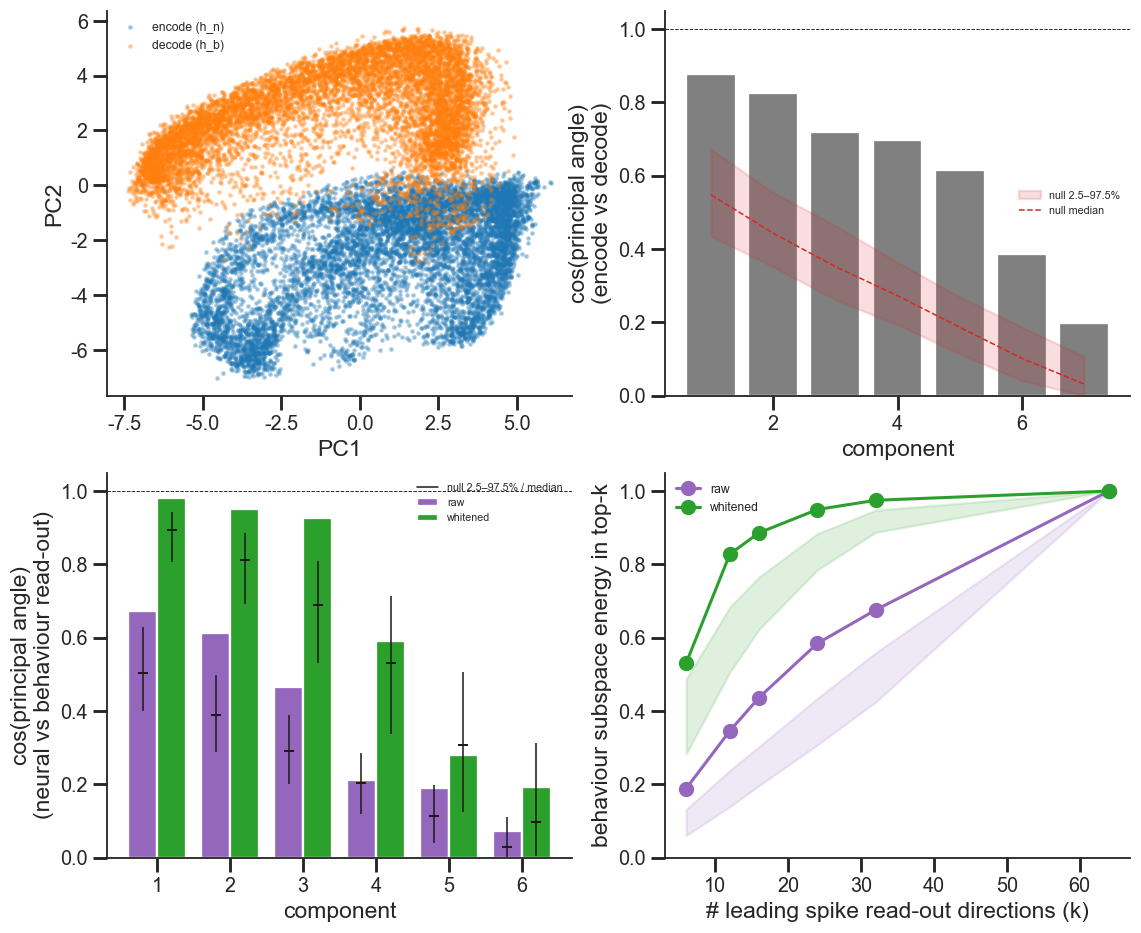

participation ratio: encode=19.3 decode=7.1 (d_sub=7); behaviour read-out rank d_ro=6
encode/decode mean cos²=0.431 (chance 0.109)
read-out mean cos²: raw=0.189  whitened=0.531


In [27]:
# === ED Fig 4: encode/decode latent + read-out subspace geometry ===
# a) PC1 vs PC2 of the pre-read-out latent (encode h_n vs decode h_b);
# b) cos(principal angle) between encode/decode activation subspaces vs component;
# c) cos(principal angle) between the dominant spike vs behaviour read-out
#    directions, raw and whitened, with random-read-out null CIs;
# d) behaviour-subspace energy captured by the top-k spike read-out directions,
#    raw and whitened, with null CIs. (Ports joint-encode-decode.ipynb §9.)
from sklearn.decomposition import PCA


@torch.no_grad()
def _collect_enc_dec_latents(model, loaders, device):
    """Row-aligned pre-read-out encode (h_n) and decode (h_b) latents over a split.
    encode: spikes masked, behaviour seen -> xfull[:, :T]; decode: behaviour masked,
    spikes seen -> xfull[:, T:]."""
    model.eval(); Le, Ld = [], []
    for s, sd in loaders.items():
        for b in sd:
            m = b.mask.to(device); T = b.spike.shape[1]
            sp, bh = b.spike.to(device), b.behavior.to(device)
            nt = b.mask.clone().to(device)
            _, _, xe = model(s, sp, bh, m, nt, torch.zeros_like(nt))
            bt = b.mask.clone().to(device)
            _, _, xd = model(s, sp, bh, m, torch.zeros_like(bt), bt)
            mk = b.mask.numpy().astype(bool)
            Le.append(xe[:, :T].cpu().numpy()[mk]); Ld.append(xd[:, T:].cpu().numpy()[mk])
    return np.vstack(Le), np.vstack(Ld)


L_enc, L_dec = _collect_enc_dec_latents(joint_model, joint_loaders['test'], device)
_D = L_enc.shape[1]


def _pca_basis(L, d):
    _, _, Vt = np.linalg.svd(L - L.mean(0), full_matrices=False); return Vt[:d].T


def participation_ratio(L):
    s = np.linalg.svd(L - L.mean(0), compute_uv=False) ** 2
    return float(s.sum() ** 2 / (s ** 2).sum())


def principal_angles_cos(A, B):
    return np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0)


def _svd_basis(W, d):
    _, _, Vt = np.linalg.svd(W, full_matrices=False); return Vt[:d].T


def _energy_in(Q, V):
    return float(np.trace(Q.T @ V @ V.T @ Q) / Q.shape[1])


def _null_pa_cos(d1, d2, D, n=300, seed_=0):
    rng = np.random.default_rng(seed_); out = []
    for _ in range(n):
        A = np.linalg.qr(rng.standard_normal((D, d1)))[0]
        B = np.linalg.qr(rng.standard_normal((D, d2)))[0]
        out.append(np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0))
    return np.array(out)


# encode/decode activation subspaces, matched to the participation ratio
pr_enc, pr_dec = participation_ratio(L_enc), participation_ratio(L_dec)
d_sub = max(2, int(round(min(pr_enc, pr_dec))))
Venc, Vdec = _pca_basis(L_enc, d_sub), _pca_basis(L_dec, d_sub)
ang_ed = principal_angles_cos(Venc, Vdec)


def _readout_rows(mod):
    mods = mod.values() if isinstance(mod, nn.ModuleDict) else [mod]
    return np.vstack([m.weight.detach().cpu().numpy() for m in mods])


W_spk = _readout_rows(joint_model.spike_readout)     # (sum_K, D)
W_beh = _readout_rows(joint_model.beh_readout)       # (3*n_rooms, D)
d_ro = int(np.linalg.matrix_rank(W_beh))             # behaviour read-out rank (<= 3*n_rooms)
Qb, Qs = _svd_basis(W_beh, d_ro), _svd_basis(W_spk, d_ro)
ang_ro = principal_angles_cos(Qs, Qb)

# whitened (functional) read-out directions: W @ C^{1/2}, C = pooled latent covariance
Cz = np.cov(np.vstack([L_enc, L_dec]), rowvar=False)
_ev, _evec = np.linalg.eigh(Cz)
C_half = (_evec * np.sqrt(np.clip(_ev, 0.0, None))) @ _evec.T


def _whiten_basis(W, d):
    return np.linalg.svd(W @ C_half, full_matrices=False)[2][:d].T


Qs_w, Qb_w = _whiten_basis(W_spk, d_ro), _whiten_basis(W_beh, d_ro)
ang_w = principal_angles_cos(Qs_w, Qb_w)

ks = sorted({min(k, _D) for k in [d_ro, 2 * d_ro, 4 * d_ro, 16, 32, 64, _D]})
spk_top_raw = {k: _svd_basis(W_spk, k) for k in ks}
spk_top_w = {k: _whiten_basis(W_spk, k) for k in ks}
curve_raw = [_energy_in(Qb, spk_top_raw[k]) for k in ks]
curve_w = [_energy_in(Qb_w, spk_top_w[k]) for k in ks]

# empirical null: random behaviour read-out of matched Frobenius norm, same pipeline
_rng4 = np.random.default_rng(seed); N_NULL = 300
null_pa = {'raw': [], 'whitened': []}; null_curve = {'raw': [], 'whitened': []}
for _ in range(N_NULL):
    R = _rng4.standard_normal(W_beh.shape); Wb = R * (np.linalg.norm(W_beh) / np.linalg.norm(R))
    for tag, whiten, Qsx, tops in [('raw', False, Qs, spk_top_raw),
                                   ('whitened', True, Qs_w, spk_top_w)]:
        M = Wb @ C_half if whiten else Wb
        Qbx = np.linalg.svd(M, full_matrices=False)[2][:d_ro].T
        null_pa[tag].append(principal_angles_cos(Qsx, Qbx))
        null_curve[tag].append([_energy_in(Qbx, tops[k]) for k in ks])

# --- figure ---
Z = np.vstack([L_enc, L_dec]); task = np.array([0] * len(L_enc) + [1] * len(L_dec))
_sub = np.sort(_rng4.choice(len(Z), min(len(Z), 40000), replace=False))
Z2 = PCA(n_components=2, random_state=seed).fit_transform(Z - Z.mean(0))[_sub]
tsub = task[_sub]

fig_ed4, axes = plt.subplots(2, 2, figsize=(12, 10))
# a) PC1 vs PC2, encode vs decode
for tk, col, lab in [(0, 'tab:blue', 'encode (h_n)'), (1, 'tab:orange', 'decode (h_b)')]:
    mk = tsub == tk
    axes[0, 0].scatter(Z2[mk, 0], Z2[mk, 1], s=3, alpha=0.3, color=col, label=lab, rasterized=True)
axes[0, 0].set(xlabel='PC1', ylabel='PC2'); axes[0, 0].legend(fontsize=8)
# b) encode vs decode subspace principal angles
null_ed = _null_pa_cos(d_sub, d_sub, _D, seed_=seed)
_lo, _med, _hi = np.percentile(null_ed, [2.5, 50, 97.5], axis=0); xr = np.arange(1, d_sub + 1)
axes[0, 1].bar(xr, ang_ed, color='0.5')
axes[0, 1].fill_between(xr, _lo, _hi, color='tab:red', alpha=0.15, label='null 2.5–97.5%')
axes[0, 1].plot(xr, _med, color='tab:red', lw=1, ls='--', label='null median')
axes[0, 1].axhline(1, ls='--', color='k', lw=0.6)
axes[0, 1].set(xlabel='component', ylabel='cos(principal angle)\n(encode vs decode)', ylim=(0, 1.05))
axes[0, 1].legend(fontsize=7)
# c) spike vs behaviour read-out angles, raw + whitened, with null CIs
xp, wbar = np.arange(1, d_ro + 1), 0.4
for ang_v, col, off, tag in [(ang_ro, 'tab:purple', -wbar / 2, 'raw'),
                             (ang_w, 'tab:green', wbar / 2, 'whitened')]:
    axes[1, 0].bar(xp + off, ang_v, width=wbar, color=col, label=tag)
    nlo, nmed, nhi = np.percentile(np.array(null_pa[tag]), [2.5, 50, 97.5], axis=0)
    axes[1, 0].vlines(xp + off, nlo, nhi, color='k', lw=1)
    axes[1, 0].plot(xp + off, nmed, '_', color='k', ms=7, mew=1.3)
axes[1, 0].axhline(1, ls='--', color='k', lw=0.6)
axes[1, 0].plot([], [], color='k', lw=1, label='null 2.5–97.5% / median')
axes[1, 0].set(xlabel='component', ylabel='cos(principal angle)\n(neural vs behaviour read-out)', ylim=(0, 1.05))
axes[1, 0].legend(fontsize=7)
# d) behaviour subspace energy in top-k spike read-out dirs, raw + whitened, with CIs
for tag, cv, col in [('raw', curve_raw, 'tab:purple'), ('whitened', curve_w, 'tab:green')]:
    lo, hi = np.percentile(np.array(null_curve[tag]), [2.5, 97.5], axis=0)
    axes[1, 1].plot(ks, cv, 'o-', color=col, label=tag)
    axes[1, 1].fill_between(ks, lo, hi, color=col, alpha=0.15)
axes[1, 1].set(xlabel='# leading spike read-out directions (k)',
               ylabel='behaviour subspace energy in top-k', ylim=(0, 1.05))
axes[1, 1].legend(fontsize=8)
ph.save_fig(fig_ed4, 'edfig4_subspaces'); plt.show()
print(f'participation ratio: encode={pr_enc:.1f} decode={pr_dec:.1f} (d_sub={d_sub}); '
      f'behaviour read-out rank d_ro={d_ro}')
print(f'encode/decode mean cos²={np.mean(ang_ed ** 2):.3f} (chance {d_sub / _D:.3f})')
print(f'read-out mean cos²: raw={np.mean(ang_ro ** 2):.3f}  whitened={np.mean(ang_w ** 2):.3f}')


**Extended Data Figure 4 | Encode/decode latent and read-out subspace geometry.** **a**, First two principal components of the pre-read-out latent for the encode (neural, h_n) and decode (behaviour, h_b) tasks. **b**, Cosine of the principal angles between the encode and decode activation subspaces (matched to the participation ratio d_sub) versus component, with a random-subspace null (2.5–97.5%). **c**, Cosine of the principal angles between the dominant spike and behaviour read-out directions (matched to the behaviour read-out rank d_ro), for raw and covariance-whitened weights, each against a norm-matched random-read-out null. **d**, Fraction of the behaviour output subspace captured by the top-k spike read-out directions (raw and whitened), shaded bands are the 2.5–97.5% random-read-out null. Note d_ro (=6, the 3-coordinate × 2-room output count) is the read-out rank, distinct from the ~32-dim activation participation ratio in b.


---
## Extended Data Figure 6 — neural PCA vs latent projection

**a** PCA applied directly to neural activity fails to reveal route structure (single session). **b** Neural activity projected into the 3-D transformer-latent embedding via ridge regression (leave-one-flight-out CV) recovers the route structure (same session).

In [ ]:
# === ED Fig 6: neural PCA vs ridge-projection into latent space (one session) ===
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import silhouette_score

# Pick the indoor session with the most test flights.
ed5_session = max((s for s in session_names if ph.is_indoor(s)),
                  key=lambda s: len(np.unique(emb['flight_id'][emb['session'] == s])))
sel = emb['session'] == ed5_session
lat_s, route_s, fid_s = emb['latent'][sel], emb['route'][sel], emb['flight_id'][sel]

# Neural activity (spike counts) for the same session/timepoints, in dataloader order.
spk_rows = []
for b in dataloaders['test'][ed5_session]:
    mn = b.mask.numpy().astype(bool)
    spk = b.spike.numpy()
    for i in range(spk.shape[0]):
        if mn[i].sum() > 0:
            spk_rows.append(spk[i, mn[i]])
spk_s = np.vstack(spk_rows)
assert len(spk_s) == len(lat_s), (len(spk_s), len(lat_s))

# a: direct 3D PCA of neural activity (sqrt-transformed counts).
neural_pca = PCA(n_components=3, random_state=seed).fit_transform(np.sqrt(spk_s))
# b: ridge (leave-one-flight-out CV) predicting the 3D latent-PCA from neural activity.
lat_pca = PCA(n_components=3, random_state=seed).fit_transform(lat_s)
pred = np.zeros_like(lat_pca)
for tr, te in LeaveOneGroupOut().split(spk_s, groups=fid_s):
    pred[te] = Ridge(alpha=10.0).fit(np.sqrt(spk_s[tr]), lat_pca[tr]).predict(np.sqrt(spk_s[te]))

fig_ed5, (axa, axb) = plt.subplots(1, 2, figsize=(11, 5))
ph.plot_embedding(axa, neural_pca[:, :2], route_s, categorical=True, s=5)
axa.set_title('neural PCA (direct)')
ph.plot_embedding(axb, pred[:, :2], route_s, categorical=True, s=5)
axb.set_title('ridge → latent (LOFO CV)')
handles = [plt.Line2D([], [], marker='o', ls='', color=ph.ROUTE_COLORS[k], label=ph.ROUTE_LABELS[k])
           for k in range(len(ph.ROUTE_LABELS))]
axb.legend(handles=handles, title='route', loc='center left', bbox_to_anchor=(1.02, 0.5),
           frameon=False, fontsize=12)
ph.save_fig(fig_ed5, 'edfig6_neural_pca'); plt.show()

# Quantify structure: route-label silhouette in each space (higher = clearer).
mask_r = route_s > 0
sil_a = silhouette_score(neural_pca[mask_r], route_s[mask_r]) if mask_r.sum() > 10 else np.nan
sil_b = silhouette_score(pred[mask_r], route_s[mask_r]) if mask_r.sum() > 10 else np.nan
print(f'route silhouette — neural PCA: {sil_a:.3f} | ridge→latent: {sil_b:.3f}')

**Extended Data Figure 6 | Neural PCA versus latent projection.** For one representative indoor session, each point is a held-out flight time-bin coloured by flight route. **a**, The top two principal components of the (√-transformed) neural activity do not separate routes. **b**, Predicting the 3-D transformer-latent PCA from the same neural activity by ridge regression under leave-one-flight-out cross-validation recovers clear route structure. The route-label silhouette scores (printed) quantify the difference.

---
## Extended Data Figure 9 — SWR mixed-model ladders

**a** Non-reward peri-flight SWR counts (perch + other). **b** Mixed model of decoding error vs number of flights in the cluster (| bat). **c** Full mixed-model ladder (naïve pooled → per-session lines → added-variable) for encoding FDE and correlation. **d** Full ladder for decoding (3-D log Fréchet and 3-D reconstruction error).

In [ ]:
# === ED Fig 9: SWR mixed-model ladders ===
# Extend the Fig 5f/g merged table with per-flight corr (encode) and recon (decode).
@torch.no_grad()
def joint_encode_perflight_corr():
    rows = []
    for sn, sd in joint_loaders['test'].items():
        for b in sd:
            m = b.mask.to(device)
            rate, _, _ = joint_model(sn, b.spike.to(device), b.behavior.to(device),
                                     m, m, torch.zeros_like(m))
            rate = rate.cpu().numpy(); yt = b.spike.numpy(); mn = b.mask.numpy().astype(bool)
            fpi = b.flight_path_index.numpy()
            for i in range(rate.shape[0]):
                v = mn[i]
                if v.sum() < 3:
                    continue
                c = corr(yt[i, v], rate[i, v], axis=0)
                rows.append(dict(session=sn, flight_path_index=int(fpi[i]),
                                 corr=float(np.nanmean(c))))
    return pd.DataFrame(rows)


recon_fl = (joint_decode_test.groupby(['session', 'flight_id'])['err_3d'].median()
            .reset_index().rename(columns={'flight_id': 'flight_path_index', 'err_3d': 'recon_3d'}))
mf2 = (mf.merge(joint_encode_perflight_corr(), on=['session', 'flight_path_index'], how='left')
         .merge(recon_fl, on=['session', 'flight_path_index'], how='left'))

# (lme_p, ladder_row + all ED Fig 9 plotting live in the assembly cell below)


In [ ]:
# === Extended Data Figure 9 (a-d) on a single canvas ===
# 5 rows x 3 cols. Row 1: a (non-reward SWR counts), b (decode error vs cluster size).
# Rows 2-3: encoding ladders (c: FDE, corr). Rows 4-5: decoding ladders (d: log Fréchet, recon).
# Each ladder row is [naive pooled | per-session | added-variable].
def lme_p(df, outcome, x):
    d = df.dropna(subset=[outcome, x, 'flight_frac'])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lme = smf.mixedlm(f'{outcome} ~ {x} + flight_frac', d, groups=d['session'],
                          vc_formula={'cluster': '0 + C(flight_type_index)'}).fit(method='lbfgs', maxiter=400)
    return float(lme.params[x]), float(lme.pvalues[x]), len(d)


def ladder_row(axes3, df, outcome, ylabel, x='pre_takeoff'):
    d = df.dropna(subset=[outcome, x, 'flight_frac']).copy()
    axes3[0].scatter(d[x], d[outcome], s=6, alpha=0.15, color='0.5', rasterized=True)
    cf = np.polyfit(d[x], d[outcome], 1); xs = np.linspace(d[x].min(), d[x].max(), 50)
    axes3[0].plot(xs, np.polyval(cf, xs), color='firebrick', lw=2)
    axes3[0].set(xlabel='# peri-flight SWRs', ylabel=ylabel, title='naïve pooled')
    for sn, g in d.groupby('session'):
        if len(g) < 8 or g[x].nunique() < 2:
            continue
        cfs = np.polyfit(g[x], g[outcome], 1); xg = np.linspace(g[x].min(), g[x].max(), 20)
        axes3[1].plot(xg, np.polyval(cfs, xg), color=BAT_PALETTE.get(parse_bat(sn), '0.6'), lw=1, alpha=0.7)
    axes3[1].set(xlabel='# peri-flight SWRs', ylabel=ylabel, title='per-session')
    Xc = sm.add_constant(pd.get_dummies(d['session'], drop_first=True).astype(float)
                         .assign(flight_frac=d['flight_frac'].values))
    ry = sm.OLS(d[outcome].values, Xc).fit().resid
    rx = sm.OLS(d[x].values, Xc).fit().resid
    axes3[2].scatter(rx, ry, s=6, alpha=0.15, color='0.5', rasterized=True)
    cf2 = np.polyfit(rx, ry, 1); xs2 = np.linspace(rx.min(), rx.max(), 50)
    axes3[2].plot(xs2, np.polyval(cf2, xs2), color='firebrick', lw=2)
    beta, p, n = lme_p(d, outcome, x)
    axes3[2].set(xlabel='residual # SWRs', ylabel=f'residual {ylabel}', title='added-variable')
    return dict(outcome=ylabel, beta=beta, p=p, n=n)


fig_ed9 = plt.figure(figsize=(16, 24))
gs_ed9 = fig_ed9.add_gridspec(5, 3, hspace=0.5, wspace=0.32)

# a: non-reward peri-flight SWR counts (perch + other).
ax7a = fig_ed9.add_subplot(gs_ed9[0, 0])
nonrew = pd.concat([
    flights.loc[flights['toff_class'] != 'reward', 'pre_takeoff'],
    flights.loc[flights['land_class'] != 'reward', 'post_landing']])
ax7a.hist(nonrew, bins=np.arange(0, nonrew.max() + 2) - 0.5, color='steelblue', edgecolor='k')
ax7a.set(xlabel='# peri-flight SWRs (non-reward edges)', ylabel='count', title='non-reward SWRs')

# b: decode error vs #flights in cluster (| bat) — added-variable panel.
ax7b = fig_ed9.add_subplot(gs_ed9[0, 1])
d7b = mf2.dropna(subset=['log_frechet', 'cluster_size']).copy()
Xc = sm.add_constant(pd.get_dummies(d7b['bat'], drop_first=True).astype(float))
ry = sm.OLS(d7b['log_frechet'].values, Xc).fit().resid
rx = sm.OLS(d7b['cluster_size'].values.astype(float), Xc).fit().resid
ax7b.scatter(rx, ry, s=6, alpha=0.2, color='0.5', rasterized=True)
cf = np.polyfit(rx, ry, 1); xs = np.linspace(rx.min(), rx.max(), 50)
ax7b.plot(xs, np.polyval(cf, xs), color='firebrick', lw=2)
beta_b, p_b, n_b = lme_p(d7b.assign(pre_takeoff=d7b['cluster_size']), 'log_frechet', 'cluster_size')
ax7b.set(xlabel='residual # flights in cluster', ylabel='residual log Fréchet', title='decode vs cluster size')
fig_ed9.add_subplot(gs_ed9[0, 2]).axis('off')

# c (rows 2-3): encoding ladders; d (rows 4-5): decoding ladders.
ed9_p = [dict(panel='9b', outcome='log Fréchet ~ cluster size', beta=beta_b, p=p_b, n=n_b)]
ladder_specs = [('ED 9c', 'fde', 'FDE', 1), ('ED 9c', 'corr', 'corr', 2),
                ('ED 9d', 'log_frechet', 'log Fréchet', 3), ('ED 9d', 'recon_3d', '3D recon (m)', 4)]
for tag, col, lab, row in ladder_specs:
    axes3 = [fig_ed9.add_subplot(gs_ed9[row, k]) for k in range(3)]
    rec = ladder_row(axes3, mf2, col, lab)
    axes3[0].set_ylabel(f'{lab}  ({tag[-1]})\n' + axes3[0].get_ylabel())
    ed9_p.append(dict(panel=tag, **rec))

ph.save_fig(fig_ed9, 'edfig9_full'); plt.show()
print('ED Fig 9 — mixed-model coefficients for #SWRs / cluster size:'); ph.p_table(ed9_p)


---
## Extended Data Figure 5 — context window size

**a–b** Effect of the training context-window size on encoding fit (FDE, correlation): models retrained at window sizes {1, 3, 5, 7, 9, 11, full} with `window_size=W` flight tiling, evaluated on the matching windowed test set. **c–d** As **a–b** for decoding (3-D Fréchet, 3-D reconstruction). Panels **c–d** train a `Bat_Transformer_Decoder` per window size on the tiled loaders on the first run (cached to `out/bat_decoder_ctxlen/`) and reload thereafter — the same load-or-train pattern used for every other model.

In [ ]:
# === ED Fig 5a/b: encoding fit vs training context-window size ===
CTX_DIR = './out/bat_former_ctxlen'
CTX_WINDOWS = [1, 3, 5, 7, 9, 11]


@torch.no_grad()
def eval_windowed(model, loaders):
    rows = []
    for sn, sd in loaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


ctx_pieces, ctx_dls_by_w = [], {}
for W in CTX_WINDOWS:
    ck = f'{CTX_DIR}/bat_former_seed_{seed}_lr_1.00e-02_wd_1.00e-02{DATA_TAG}_ctx{W}.pth'
    dlW, _, _, _ = bat_data_loader(**{**data_config, 'window_size': W,
                                      'stride_train': W, 'stride_test': W})
    ctx_dls_by_w[W] = dlW
    mW = ensure_former(ck, lambda: build_former('transformer'), loaders=dlW)  # train-if-missing
    ctx_pieces.append(eval_windowed(mW, dlW).assign(context=W, context_x=W))
    print(f'  ok: ctx{W}')
# 'full' context = the main transformer on full-flight loaders.
ctx_pieces.append(ed1_encode_df[ed1_encode_df['model'] == 'Transformer']
                  [['session', 'bat', 'unit', 'corr', 'fde']].assign(context='full', context_x=13))
ctx_df = pd.concat(ctx_pieces, ignore_index=True)

# Per-session medians vs context, mean +/- 95% CI across sessions.

# (plotting for ED Fig 5a-d assembled on one canvas below)


In [ ]:
# === ED Fig 5c/d: decoding vs context window (per-window decoders, train-if-missing) ===
# The context-length decode sweep is not cached (only encoders are), so we train one
# Bat_Transformer_Decoder per window size on the tiled loaders (first run), cache it,
# and reload on subsequent runs -- same load-or-train pattern as everywhere else.
CTX_DEC_DIR = './out/bat_decoder_ctxlen'
os.makedirs(CTX_DEC_DIR, exist_ok=True)


@torch.no_grad()
def _decode_windowed(model, loaders):
    recs = []
    for sn, sd in loaders['test'].items():
        bm = meta_info_dict['behavior_mean'][sn].squeeze(); bs = meta_info_dict['behavior_std'][sn].squeeze()
        for b in sd:
            m = b.mask.to(device)
            yp = model(sn, b.spike.to(device), m).cpu().numpy() * bs[None, None, :3] + bm[None, None, :3]
            yt = b.behavior[:, :, :3].numpy() * bs[None, None, :3] + bm[None, None, :3]
            mn = b.mask.numpy().astype(bool); B, T = mn.shape
            fpi = np.broadcast_to(b.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mn], yp[mn]
            for i in range(len(ytf)):
                recs.append(dict(bat=parse_bat(sn), session=sn, flight_id=int(fpi[mn][i]), t_idx=int(tix[mn][i]),
                                 x_true=ytf[i, 0], y_true=ytf[i, 1], z_true=ytf[i, 2],
                                 x_pred=ypf[i, 0], y_pred=ypf[i, 1], z_pred=ypf[i, 2],
                                 err_3d=float(np.linalg.norm(ytf[i] - ypf[i]))))
    return pd.DataFrame(recs)


def _make_ctx_decoder():
    return Bat_Transformer_Decoder(latent_dim=128, ff_dim=32, num_layers=1, dropout_prob=0.30,
                                   readin_dropout=0.19, input_transform='identity',
                                   input_dim_dict=unit_num_dict, output_dim=3, num_heads=4,
                                   final_activation=nn.Identity())


ctx_dec_pieces = []
for W in CTX_WINDOWS:
    if W not in ctx_dls_by_w:
        continue
    dpath = f'{CTX_DEC_DIR}/bat_decoder_seed_{seed}{DATA_TAG}_ctx{W}.pth'
    dec = ensure_decoder(dpath, _make_ctx_decoder, loaders=ctx_dls_by_w[W])
    rc = _decode_windowed(dec, ctx_dls_by_w[W])
    fr = frechet_per_flight(rc.assign(decoder='ctx'))
    ctx_dec_pieces.append(dict(context_x=W, frechet=fr['frechet_3d'].median(), recon=rc['err_3d'].median(),
                               fr_df=fr.assign(context_x=W), rc_df=rc.assign(context_x=W)))
    print(f'  ok: decode ctx{W}')

# 'full' context: the joint decoder already computed (joint_frechet / joint_decode_test).
ctx_dec_pieces.append(dict(context_x=13, frechet=joint_frechet['frechet_3d'].median(),
                           recon=joint_decode_test['err_3d'].median(),
                           fr_df=joint_frechet.assign(context_x=13),
                           rc_df=joint_decode_test.assign(context_x=13)))

fr_all = pd.concat([p['fr_df'] for p in ctx_dec_pieces], ignore_index=True)
rc_all = pd.concat([p['rc_df'] for p in ctx_dec_pieces], ignore_index=True)

# (plotting for ED Fig 5a-d assembled on one canvas below)


In [ ]:
# === Extended Data Figure 5 (a-d) on a single canvas ===
# 2 rows x 2 cols; encoding fit (a,b) over the top, decoding (c,d) below, all as
# session-median vs training context window (per-session lines + mean 95% CI).
fig_ed5 = plt.figure(figsize=(12, 9))
gs_ed5 = fig_ed5.add_gridspec(2, 2, hspace=0.35, wspace=0.28)


def _ctx_panel(ax, df, col, lab, panel, ylim=None):
    per = df.groupby(['context_x', 'session'])[col].median().reset_index()
    for sn, g in per.groupby('session'):
        g = g.sort_values('context_x')
        ax.plot(g['context_x'], g[col], color=BAT_PALETTE.get(parse_bat(sn), '0.6'), lw=0.8, alpha=0.35)
    agg = per.groupby('context_x')[col].agg(['mean', 'std', 'count'])
    ci = 1.96 * agg['std'] / np.sqrt(agg['count'])
    ax.errorbar(agg.index, agg['mean'], yerr=ci, fmt='o-', color='k', lw=2.5, capsize=3, zorder=5)
    ax.set(xlabel='context window (bins)', ylabel=f'session-median {lab}',
           title=f'{lab}', xticks=CTX_WINDOWS + [13],
           xticklabels=[str(w) for w in CTX_WINDOWS] + ['full'])
    if ylim:
        ax.set_ylim(*ylim)


_ctx_panel(fig_ed5.add_subplot(gs_ed5[0, 0]), ctx_df, 'fde', 'FDE', 'a', (-0.25, 0.6))
_ctx_panel(fig_ed5.add_subplot(gs_ed5[0, 1]), ctx_df, 'corr', 'corr', 'b', (0, 0.7))
_ctx_panel(fig_ed5.add_subplot(gs_ed5[1, 0]), fr_all, 'frechet_3d', '3D Fréchet (m)', 'c')
_ctx_panel(fig_ed5.add_subplot(gs_ed5[1, 1]), rc_all, 'err_3d', '3D recon (m)', 'd')
ph.save_fig(fig_ed5, 'edfig5_full'); plt.show()
print('ED Fig 5a-d — encoding/decoding fit vs training context window (session medians shown).')
